# Financial Instruments Atlas: 209 instruments, definitions, pricing math and risk profiles

**What this is:** a single notebook that works as (1) a searchable catalog of ~200 financial instruments, (2) a working pricing and risk library in plain Python, and (3) a risk-profile map you can filter, chart and export.

**Runs in:** Google Colab and Microsoft Fabric notebooks (numpy, pandas, scipy, matplotlib only). The last section optionally writes the catalog to a Fabric Lakehouse Delta table.

| Section | Content |
|---|---|
| 1 | Setup |
| 2 | Instrument catalog (209 rows, 14 attributes) |
| 3 | Risk methodology and lookup helpers |
| 4 | Risk-profile overview and charts |
| 5 | Time value of money |
| 6 | Money market |
| 7 | Bonds and interest rate curves |
| 8 | Credit and securitization |
| 9 | Equities and funds |
| 10 | Forwards and futures |
| 11 | Swaps |
| 12 | Options (closed form and trees) |
| 13 | Exotic options (Monte Carlo) |
| 14 | Structured products |
| 15 | Crypto |
| 16 | Loans, real estate, insurance and Swedish wrappers |
| 17 | Portfolio risk toolkit (VaR, CVaR, stress tests) |
| 18 | Coverage check, export, Fabric Lakehouse |

**Important caveats.** Risk scores are expert judgement on a typical instance of each instrument, not a regulatory SRI for a specific product. Market data in the demos is illustrative; swap in real curves and prices before using any number for a decision. Swedish tax parameters (ISK) change yearly; verify them.

Use `describe("autocall")` anywhere to get the full card for an instrument plus a live calculation demo.

In [1]:
# Standard toolbox only. If you need to pip install something to price a bond, something has gone wrong.
import math
import difflib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, stats
from scipy.stats import norm

try:
    from IPython.display import display, Markdown
except ImportError:  # running this as a plain .py file? brave, but fine
    display = print
    Markdown = str

warnings.filterwarnings("ignore", category=RuntimeWarning)  # Monte Carlo tails love log(0). We know.
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.8), "axes.grid": True, "grid.alpha": 0.3})

SEED = 42  # every demo seeds its own generator, so results don't depend on which cell you ran first

# Registry: catalog column "calc" points at a key here, describe() looks it up and runs it.
DEMOS = {}
def demo(key):
    def wrap(fn):
        DEMOS[key] = fn
        return fn
    return wrap

def show(obj, title=None):
    """Pretty-print dicts and frames the same way, because consistency is cheaper than therapy."""
    if title:
        print(f"\n### {title}")
    if isinstance(obj, dict):
        obj = pd.Series(obj, name="value").to_frame()
    display(obj)

print("Setup done. numpy", np.__version__, "| pandas", pd.__version__)

Setup done. numpy 2.5.3 | pandas 3.0.5


## 2. Instrument catalog

Each row is one instrument type with:

| Column | Meaning |
|---|---|
| `name`, `asset_class`, `sub_class` | Taxonomy |
| `definition` | What it is |
| `mechanics_payoff` | How it pays and how it is priced |
| `sri` | Summary risk indicator, 1 (lowest) to 7 (highest), PRIIPs-style scale applied to a typical instance |
| `market`, `credit`, `liquidity`, `leverage`, `complexity` | Risk dimensions, 1 to 5 |
| `venue` | Exchange, OTC, Bank, Fund or Private |
| `key_risks` | What actually blows up |
| `calc` | Name of the demo function in this notebook that prices or analyses it |

In [2]:
# Column order, so nobody has to count commas at 2 am:
# name, asset_class, sub_class, definition, mechanics_payoff,
# sri (1-7, PRIIPs style), market, credit, liquidity, leverage, complexity (each 1-5),
# venue, key_risks, calc (name of the demo function in this notebook, or "")
RAW = [
# ---------------------------------------------------------------- CASH & MONEY MARKET
("Bank deposit (current account)", "Cash & Money Market", "Deposit", "Demand deposit at a bank, withdrawable at any time.", "Pays a (usually tiny) variable rate; principal guaranteed by the bank and deposit insurance up to the limit.", 1, 1, 1, 1, 1, 1, "Bank", "Inflation erosion, bank failure above deposit guarantee (SEK 1.05m in Sweden).", "simple_interest"),
("Savings account", "Cash & Money Market", "Deposit", "Interest-bearing deposit with limited transaction features.", "Variable rate credited periodically; compounding monthly or yearly.", 1, 1, 1, 1, 1, 1, "Bank", "Real rate often negative, rate cuts flow through immediately.", "fv_compound"),
("Term deposit (fasträntekonto)", "Cash & Money Market", "Deposit", "Deposit locked for a fixed term at a fixed rate.", "Principal plus fixed interest at maturity; early break costs or forbidden.", 1, 1, 1, 2, 1, 1, "Bank", "Lock-up, reinvestment risk at maturity.", "fv_compound"),
("Certificate of deposit (CD)", "Cash & Money Market", "Deposit", "Negotiable or non-negotiable time deposit receipt issued by a bank.", "Fixed coupon, usually simple interest under 1 year, can trade in secondary market.", 1, 1, 2, 2, 1, 1, "OTC", "Issuer bank credit risk above guarantee, rate risk if sold early.", "money_market_yields"),
("Treasury bill (statsskuldväxel)", "Cash & Money Market", "Government bill", "Short-term zero-coupon government debt, typically 1 to 12 months.", "Issued at a discount, pays par at maturity; yield quoted as discount or simple yield.", 1, 1, 1, 1, 1, 1, "OTC", "Practically only rate and inflation risk.", "money_market_yields"),
("Commercial paper (företagscertifikat)", "Cash & Money Market", "Corporate short-term", "Unsecured short-term promissory notes issued by corporates.", "Discount instrument, maturities up to 1 year; rolled continuously by issuers.", 2, 1, 3, 3, 1, 2, "OTC", "Rollover risk, market freezes (2008, Swedish CP market 2020).", "money_market_yields"),
("Repurchase agreement (repo)", "Cash & Money Market", "Secured funding", "Sale of securities with agreement to buy back later at a higher price.", "Economically a collateralized loan; repo interest = cash x rate x days/360, collateral has haircut.", 1, 1, 2, 2, 2, 2, "OTC", "Counterparty default plus collateral value drop, wrong-way risk.", "repo_calc"),
("Reverse repo", "Cash & Money Market", "Secured lending", "Mirror side of a repo: buy securities and agree to sell them back.", "Cash lender receives repo interest, holds collateral with haircut.", 1, 1, 2, 2, 1, 2, "OTC", "Collateral liquidation risk if counterparty fails.", "repo_calc"),
("Tri-party repo", "Cash & Money Market", "Secured funding", "Repo where a custodian agent handles collateral selection, valuation and settlement.", "Same economics as repo, operational burden outsourced to agent.", 1, 1, 2, 2, 2, 2, "OTC", "Agent concentration, intraday credit exposures.", "repo_calc"),
("Securities lending", "Cash & Money Market", "Secured lending", "Lending securities to a borrower (often short sellers) against collateral and a fee.", "Lender earns fee, keeps economic exposure via manufactured dividends.", 2, 1, 2, 2, 1, 2, "OTC", "Borrower default with collateral shortfall, cash-collateral reinvestment risk.", ""),
("Money market fund", "Cash & Money Market", "Fund", "Fund investing in short-term high quality debt (räntefond kort).", "Stable or variable NAV, daily liquidity, yield close to policy rate minus fees.", 1, 1, 2, 1, 1, 1, "Fund", "Run risk in stress, fee drag, 'breaking the buck'.", "fund_fee_drag"),
("Asset-backed commercial paper (ABCP)", "Cash & Money Market", "Securitized short-term", "Short-term paper issued by a conduit backed by receivables.", "Discount instrument supported by liquidity lines from sponsor banks.", 3, 1, 3, 4, 2, 3, "OTC", "Liquidity mismatch, sponsor support uncertainty (2007 showed this nicely).", "money_market_yields"),
# ---------------------------------------------------------------- GOVERNMENT & PUBLIC BONDS
("Nominal government bond (statsobligation)", "Government & Public Bonds", "Sovereign", "Fixed coupon bond issued by a central government in local currency.", "Annual or semi-annual coupons, par at maturity; benchmark for the risk-free curve.", 2, 3, 1, 1, 1, 1, "OTC", "Interest rate risk scales with duration, inflation risk.", "bond_price"),
("Inflation-linked bond (realobligation)", "Government & Public Bonds", "Sovereign", "Bond whose principal is indexed to CPI, coupons paid on indexed principal.", "Real coupon x index ratio; deflation floor on principal in many markets.", 2, 3, 1, 2, 1, 2, "OTC", "Real rate risk, index lag, liquidity weaker than nominals.", "inflation_linked_bond"),
("Zero-coupon government bond", "Government & Public Bonds", "Sovereign", "Government bond paying no coupon, only par at maturity.", "Price = 100 / (1+y)^T; duration equals maturity.", 2, 4, 1, 2, 1, 1, "OTC", "Maximum duration for its maturity, highly rate sensitive.", "zero_curve"),
("STRIPS", "Government & Public Bonds", "Sovereign", "Separately traded coupons and principal of a government bond.", "Each strip is a zero-coupon bond; used to build zero curves.", 2, 4, 1, 3, 1, 2, "OTC", "Rate risk, lower liquidity than the parent bond.", "zero_curve"),
("Government floating rate note", "Government & Public Bonds", "Sovereign", "Government bond with coupon reset to a short-term reference rate.", "Coupon = reference rate + spread; price near par on reset dates.", 1, 1, 1, 2, 1, 2, "OTC", "Discount margin risk, low duration.", "frn_value"),
("Agency bond", "Government & Public Bonds", "Agency", "Debt issued by government-sponsored or state-owned entities (e.g. Kommuninvest, KfW).", "Plain fixed coupon; trades at small spread over sovereigns.", 2, 3, 1, 2, 1, 1, "OTC", "Rate risk, implied vs explicit guarantee.", "bond_price"),
("Supranational bond", "Government & Public Bonds", "Supranational", "Bonds from multilateral institutions (EIB, World Bank, NIB).", "Plain fixed coupon, AAA in most cases.", 2, 3, 1, 2, 1, 1, "OTC", "Rate risk, currency risk if not SEK.", "bond_price"),
("Municipal bond", "Government & Public Bonds", "Sub-sovereign", "Debt issued by municipalities or regions.", "Fixed or floating; in the US often tax-exempt.", 2, 3, 2, 3, 1, 2, "OTC", "Local fiscal stress, liquidity.", "bond_price"),
("Sovereign Eurobond (hard currency)", "Government & Public Bonds", "Sovereign EM", "Government bond issued in a foreign currency (USD/EUR), typically by emerging markets.", "Fixed coupon in hard currency, spread over US/German curve.", 4, 3, 4, 3, 1, 2, "OTC", "Default and restructuring risk, sanctions, FX of the issuer.", "credit_spread_price"),
("Local currency EM government bond", "Government & Public Bonds", "Sovereign EM", "Emerging market government bond in local currency.", "Fixed coupon, returns driven by rates and FX.", 5, 4, 3, 3, 1, 2, "OTC", "FX crashes, capital controls, inflation.", "bond_price"),
("Premium bond (premieobligation)", "Government & Public Bonds", "Retail sovereign", "Government bond where interest is pooled and paid out as lottery prizes.", "Expected return = pooled coupon; individual return is random.", 2, 2, 1, 2, 1, 1, "Exchange", "Lottery variance, inflation.", ""),
("Perpetual government bond (consol)", "Government & Public Bonds", "Sovereign", "Bond with no maturity paying coupons forever.", "Price = C / y; duration = (1+y)/y.", 3, 5, 1, 3, 1, 1, "OTC", "Extreme rate sensitivity.", "perpetuity"),
# ---------------------------------------------------------------- CORPORATE & CREDIT
("Investment grade corporate bond", "Corporate & Credit", "Senior bond", "Bond issued by a company rated BBB- or better.", "Fixed coupon, price = discounted cash flows at government curve + credit spread.", 3, 3, 2, 2, 1, 2, "OTC", "Spread widening, downgrade to high yield (fallen angel).", "credit_spread_price"),
("High yield bond", "Corporate & Credit", "Senior bond", "Bond from a company rated below BBB- or unrated.", "Higher coupon, often callable, covenants matter.", 4, 3, 4, 3, 1, 3, "OTC", "Default, recovery uncertainty, liquidity crunches.", "credit_spread_price"),
("Nordic high yield bond", "Corporate & Credit", "Senior bond", "Typically SEK/NOK FRNs under Nordic trustee docs, often unrated.", "Coupon = STIBOR/NIBOR + margin, incurrence covenants, call schedule.", 4, 2, 4, 4, 1, 3, "OTC", "Small issuer default, very thin secondary market.", "frn_value"),
("Corporate floating rate note", "Corporate & Credit", "Senior bond", "Corporate bond with coupon resetting to a reference rate plus margin.", "Low rate duration, high spread duration.", 3, 2, 3, 2, 1, 2, "OTC", "Credit spread risk dominates.", "frn_value"),
("Callable bond", "Corporate & Credit", "Embedded option", "Bond the issuer can redeem early at a set price.", "Bond = straight bond minus call option; negative convexity near call price.", 3, 3, 2, 3, 1, 3, "OTC", "Called away when rates fall, capped upside.", "callable_bond_tree"),
("Puttable bond", "Corporate & Credit", "Embedded option", "Bond the investor can sell back to the issuer at set dates.", "Bond = straight bond plus put option; floor on price.", 2, 2, 2, 3, 1, 3, "OTC", "Lower yield as payment for the put.", "callable_bond_tree"),
("Convertible bond", "Corporate & Credit", "Hybrid equity", "Bond convertible into a fixed number of shares.", "Value approx max(bond floor, conversion value) plus time value of the option.", 4, 4, 3, 3, 2, 4, "OTC", "Equity, credit, vol and rate risk in one package.", "convertible_value"),
("Exchangeable bond", "Corporate & Credit", "Hybrid equity", "Bond convertible into shares of a company other than the issuer.", "Like a convertible but issuer credit and share are decoupled.", 4, 4, 3, 3, 2, 4, "OTC", "Two-name risk, correlation.", "convertible_value"),
("Mandatory convertible", "Corporate & Credit", "Hybrid equity", "Bond that must convert into equity at maturity.", "Payoff = long stock + short call + long put in a range ratio structure.", 5, 4, 3, 3, 1, 4, "OTC", "Behaves mostly like equity.", ""),
("Covered bond (säkerställd obligation)", "Corporate & Credit", "Secured bank", "Bank bond backed by a ring-fenced cover pool, usually mortgages.", "Dual recourse: issuer plus cover pool; AAA typical in Sweden.", 2, 3, 1, 1, 1, 2, "OTC", "Rate risk, over-collateralization erosion in house price crash.", "bond_price"),
("Senior preferred bank bond", "Corporate & Credit", "Bank capital stack", "Unsecured senior bank debt, preferred in resolution.", "Fixed or floating coupon, ranks above senior non-preferred.", 3, 3, 2, 2, 1, 2, "OTC", "Bank resolution bail-in at extreme stress.", "credit_spread_price"),
("Senior non-preferred bank bond", "Corporate & Credit", "Bank capital stack", "MREL-eligible senior debt ranking below senior preferred.", "Bail-inable before senior preferred.", 3, 3, 3, 2, 1, 3, "OTC", "Bail-in risk, spread volatility.", "credit_spread_price"),
("Tier 2 subordinated bond", "Corporate & Credit", "Bank capital stack", "Subordinated bank debt counting as Tier 2 capital.", "Usually 10NC5 structure, written down at point of non-viability.", 4, 3, 3, 3, 1, 3, "OTC", "Extension risk, write-down.", "credit_spread_price"),
("Additional Tier 1 / CoCo", "Corporate & Credit", "Bank capital stack", "Perpetual contingent convertible that converts or writes down below a CET1 trigger.", "Discretionary coupons, perpetual, callable; Credit Suisse 2023 is the case study.", 6, 4, 5, 4, 1, 5, "OTC", "Full write-down, coupon cancellation, extension.", "coco_trigger_sim"),
("Corporate hybrid bond", "Corporate & Credit", "Hybrid", "Deeply subordinated, long-dated corporate debt with deferrable coupons, 50% equity credit.", "Callable, coupon step-up after first call.", 4, 3, 4, 3, 1, 4, "OTC", "Extension (Swedish real estate 2023 non-calls), deferral.", "credit_spread_price"),
("Green bond", "Corporate & Credit", "ESG", "Bond with use-of-proceeds for eligible green projects.", "Credit identical to issuer's other senior bonds.", 3, 3, 2, 2, 1, 2, "OTC", "Greenwashing, same credit risk as vanilla.", "credit_spread_price"),
("Sustainability-linked bond", "Corporate & Credit", "ESG", "Bond whose coupon steps up if issuer misses KPI targets.", "Coupon + step-up if KPI fails at observation date.", 3, 3, 2, 3, 1, 3, "OTC", "Weak KPIs, call before step-up kicks in.", "credit_spread_price"),
("PIK bond (payment in kind)", "Corporate & Credit", "Leveraged finance", "Bond paying interest by issuing more bonds instead of cash.", "Principal accretes at the PIK rate.", 6, 3, 5, 4, 2, 4, "OTC", "Deeply subordinated, high default risk.", "fv_compound"),
("Zero-coupon corporate bond", "Corporate & Credit", "Structure", "Corporate bond with no coupons, issued at discount.", "Accretes to par.", 3, 4, 3, 3, 1, 2, "OTC", "Full credit exposure at maturity.", "zero_curve"),
("Amortizing bond", "Corporate & Credit", "Structure", "Bond repaying principal in installments.", "Annuity-like cash flows, shorter duration than bullet.", 2, 2, 2, 3, 1, 2, "OTC", "Reinvestment risk.", "annuity_payment"),
("Bond with warrants", "Corporate & Credit", "Hybrid equity", "Bond issued with detachable equity warrants.", "Value = straight bond + warrants.", 4, 4, 3, 3, 2, 3, "OTC", "Equity and credit.", "bsm_price"),
("Leveraged loan (syndicated term loan B)", "Corporate & Credit", "Loan", "Senior secured floating rate loan to sub-IG borrowers.", "SOFR/EURIBOR + margin, OID, covenant-lite common.", 4, 2, 4, 4, 1, 3, "OTC", "Default, slow settlement (T+7 or worse).", "frn_value"),
("Private credit / direct lending", "Corporate & Credit", "Private loan", "Non-bank loans to mid-market companies.", "Floating rate, illiquidity premium, held to maturity.", 5, 2, 4, 5, 2, 3, "Private", "Opaque valuations, illiquidity.", "expected_loss"),
("Mezzanine loan", "Corporate & Credit", "Private loan", "Subordinated loan between senior debt and equity, often with warrants.", "High coupon + PIK + equity kicker.", 5, 2, 5, 5, 2, 4, "Private", "Low recovery.", "expected_loss"),
# ---------------------------------------------------------------- SECURITIZED
("Agency MBS pass-through", "Securitized", "Residential", "Pool of mortgages guaranteed by a US agency, cash passed to investors.", "Principal + interest + prepayments pass through; negative convexity.", 3, 3, 1, 2, 1, 4, "OTC", "Prepayment and extension risk.", "mbs_cashflows"),
("Non-agency RMBS", "Securitized", "Residential", "Private-label residential mortgage securitization, tranched.", "Waterfall allocates losses bottom-up.", 4, 3, 3, 3, 2, 4, "OTC", "Collateral losses, prepayment.", "tranche_loss"),
("CMBS", "Securitized", "Commercial", "Securitized commercial real estate loans.", "Sequential pay tranches, balloon maturities.", 4, 3, 3, 3, 2, 4, "OTC", "Refinancing risk on office loans, special servicing.", "tranche_loss"),
("Interest-only strip (IO)", "Securitized", "Residential", "Receives only interest from a mortgage pool.", "Value falls when prepayments rise; can have negative duration.", 6, 5, 2, 4, 2, 5, "OTC", "Value can vanish with fast prepayments.", "mbs_cashflows"),
("Principal-only strip (PO)", "Securitized", "Residential", "Receives only principal from a mortgage pool.", "Bought at deep discount, gains when prepayments accelerate.", 5, 5, 2, 4, 2, 5, "OTC", "Slow prepayments kill returns.", "mbs_cashflows"),
("Auto loan ABS", "Securitized", "Consumer", "Securitized car loans or leases.", "Short WAL, amortizing, credit enhancement via subordination.", 3, 2, 2, 3, 1, 3, "OTC", "Consumer credit, used car values.", "tranche_loss"),
("Credit card ABS", "Securitized", "Consumer", "Revolving master trust backed by card receivables.", "Revolving then controlled amortization, early amortization triggers.", 3, 2, 2, 3, 1, 3, "OTC", "Charge-offs, payment rate drop.", "tranche_loss"),
("CLO (collateralized loan obligation)", "Securitized", "Corporate", "Actively managed pool of leveraged loans financed by tranched notes.", "Floating rate tranches AAA to equity, OC/IC tests divert cash.", 4, 2, 3, 3, 3, 5, "OTC", "Correlated defaults, manager risk, equity tranche is leveraged.", "tranche_loss"),
("CLO equity tranche", "Securitized", "Corporate", "First-loss residual of a CLO.", "Receives excess spread after debt tranches; ~10x leverage.", 6, 3, 5, 5, 5, 5, "OTC", "First loss, cash diverted by tests.", "tranche_loss"),
("Synthetic CDO", "Securitized", "Structured credit", "Tranched exposure to a CDS portfolio without owning the bonds.", "Tranche loss = min(max(L - A, 0), D - A).", 6, 3, 5, 5, 4, 5, "OTC", "Correlation, counterparty, model risk.", "tranche_loss"),
("CDO-squared", "Securitized", "Structured credit", "CDO backed by tranches of other CDOs.", "Leveraged correlation on correlation; cliff risk.", 7, 4, 5, 5, 5, 5, "OTC", "Cliff effects, nearly impossible to model honestly.", "tranche_loss"),
# ---------------------------------------------------------------- EQUITIES
("Common stock", "Equities", "Ordinary share", "Residual ownership claim on a company with voting rights.", "Return = price change + dividends; limited liability.", 5, 4, 1, 2, 1, 1, "Exchange", "Market crashes, idiosyncratic blow-ups.", "ddm_gordon"),
("Large-cap blue chip stock", "Equities", "Ordinary share", "Shares in large, established, liquid companies.", "Lower vol than small caps, often dividend payers.", 5, 4, 1, 1, 1, 1, "Exchange", "Market beta.", "capm"),
("Small-cap stock", "Equities", "Ordinary share", "Shares in companies with small market cap.", "Higher vol, size premium (debated).", 6, 5, 2, 3, 1, 1, "Exchange", "Liquidity, business risk.", "capm"),
("Micro-cap / First North stock", "Equities", "Ordinary share", "Very small companies on growth markets like Nasdaq First North or Spotlight.", "Lottery-like return distribution.", 7, 5, 3, 5, 1, 2, "Exchange", "Dilution, fraud, illiquidity.", "capm"),
("Preference share (preferensaktie)", "Equities", "Preferred", "Share with priority on dividends and liquidation over common stock.", "Fixed dividend, often cumulative and redeemable at a premium.", 4, 3, 3, 3, 1, 2, "Exchange", "Dividend suspension (Swedish real estate prefs 2023).", "perpetuity"),
("A/B share classes", "Equities", "Dual class", "Same company, different voting rights (A = 10 votes typical in Sweden).", "Economic rights equal; price spread reflects control premium and liquidity.", 5, 4, 1, 2, 1, 1, "Exchange", "Class spread changes.", ""),
("American Depositary Receipt (ADR)", "Equities", "Depositary receipt", "US-listed certificate representing foreign shares.", "Price tracks underlying x FX x ratio.", 5, 4, 1, 2, 1, 2, "Exchange", "FX, ADR fees, delisting.", ""),
("REIT / listed real estate company", "Equities", "Real estate", "Listed company owning income-producing real estate.", "Valued vs NAV (EPRA NRV/NTA); rate sensitive through financing.", 5, 4, 2, 2, 2, 2, "Exchange", "Rate shocks, refinancing, LTV covenants.", "nav_discount"),
("Investment company (investmentbolag)", "Equities", "Holding company", "Listed holding company owning stakes in other companies (Investor, Industrivärden).", "Trades at premium/discount to NAV.", 5, 4, 1, 1, 1, 2, "Exchange", "Discount widening, concentration.", "nav_discount"),
("Subscription right (teckningsrätt)", "Equities", "Corporate action", "Right to subscribe for new shares in a rights issue.", "Value approx (TERP - subscription price) / rights per new share.", 6, 5, 1, 3, 3, 2, "Exchange", "Expires worthless if not used or sold.", "rights_issue_terp"),
("SPAC shares", "Equities", "Special purpose", "Shares in a blank-check company raising cash to acquire a target.", "Trust value floor before deal, redemption right.", 5, 4, 2, 3, 1, 3, "Exchange", "Dilution from sponsor promote and warrants.", ""),
("Restricted stock unit (RSU)", "Equities", "Compensation", "Promise to deliver shares after vesting.", "Value = share price at vest, taxed as income.", 5, 4, 2, 5, 1, 2, "Private", "Concentration in employer.", ""),
("Employee stock option", "Equities", "Compensation", "Call option on employer stock granted as compensation.", "Long-dated, non-transferable, vesting schedule.", 6, 5, 2, 5, 3, 3, "Private", "Expires worthless, concentration.", "bsm_price"),
("Unlisted / private company shares", "Equities", "Private equity", "Shares in private companies, often via angel or crowdfunding.", "Exit via sale or IPO only.", 7, 4, 3, 5, 1, 3, "Private", "Total loss, no market.", ""),
# ---------------------------------------------------------------- FUNDS & POOLED
("Equity mutual fund (UCITS)", "Funds & Pooled", "Active fund", "Pooled, actively managed equity fund under UCITS rules.", "Daily NAV, ongoing charge deducted from NAV.", 5, 4, 1, 1, 1, 1, "Fund", "Market risk, fees, underperformance.", "fund_fee_drag"),
("Bond fund", "Funds & Pooled", "Active fund", "Fund investing in bonds with a target duration or credit profile.", "No maturity, perpetual duration exposure.", 3, 3, 2, 1, 1, 1, "Fund", "Rates, credit, fund outflows.", "fund_fee_drag"),
("Index fund", "Funds & Pooled", "Passive fund", "Fund replicating a market index.", "Return = index - fees - tracking difference.", 5, 4, 1, 1, 1, 1, "Fund", "Market risk, concentration in index heavyweights.", "tracking_error"),
("Physical ETF", "Funds & Pooled", "ETF", "Exchange-traded fund holding the index constituents.", "Intraday trading, creation/redemption keeps price near NAV.", 5, 4, 1, 1, 1, 1, "Exchange", "Spread and premium in stress.", "tracking_error"),
("Synthetic ETF", "Funds & Pooled", "ETF", "ETF gaining index exposure via swaps with a bank.", "Holds collateral basket + total return swap.", 5, 4, 2, 2, 1, 3, "Exchange", "Swap counterparty risk.", "tracking_error"),
("Leveraged ETF / bull certificate (daily reset)", "Funds & Pooled", "Leveraged", "Product delivering a multiple (2x, 3x, 5x) of daily index return.", "Daily rebalancing causes volatility decay over longer horizons.", 7, 5, 2, 2, 5, 4, "Exchange", "Volatility drag, path dependency.", "leveraged_etf_decay"),
("Inverse ETF / bear certificate", "Funds & Pooled", "Leveraged", "Product delivering minus a multiple of daily index return.", "Same daily reset decay as leveraged products.", 7, 5, 2, 2, 5, 4, "Exchange", "Decay, short squeeze in rallies.", "leveraged_etf_decay"),
("Exchange-traded note (ETN)", "Funds & Pooled", "ETP", "Unsecured debt note paying an index return.", "Issuer credit + index exposure; no underlying assets held.", 5, 4, 3, 2, 2, 3, "Exchange", "Issuer default, early termination (XIV 2018).", ""),
("Exchange-traded commodity (ETC)", "Funds & Pooled", "ETP", "Secured debt note tracking a commodity, physical or futures based.", "Physical gold ETCs hold bars; others roll futures.", 5, 4, 2, 2, 1, 2, "Exchange", "Roll yield, contango.", "futures_roll_yield"),
("Fund of funds", "Funds & Pooled", "Multi-manager", "Fund investing in other funds.", "Double fee layer.", 4, 3, 1, 2, 1, 2, "Fund", "Fee stacking.", "fund_fee_drag"),
("Target date fund (generationsfond)", "Funds & Pooled", "Lifecycle", "Fund shifting from equities to bonds as target date approaches (glide path).", "Allocation = f(years to target).", 4, 3, 1, 1, 1, 2, "Fund", "Glide path may not fit individual needs.", "glide_path"),
("Hedge fund", "Funds & Pooled", "Alternative", "Lightly regulated pooled vehicle using leverage, shorting and derivatives.", "2 and 20 type fees, lock-ups, gates.", 5, 3, 2, 4, 3, 4, "Private", "Manager risk, leverage, opacity.", "sharpe_sortino"),
("Private equity fund", "Funds & Pooled", "Alternative", "Closed-end fund buying private companies, 10+ year life.", "Capital calls, distributions, J-curve; IRR and TVPI metrics.", 6, 3, 2, 5, 3, 4, "Private", "Illiquidity, smoothed valuations, leverage.", "pe_fund_irr"),
("Venture capital fund", "Funds & Pooled", "Alternative", "Fund investing in early-stage startups.", "Power law returns, few winners carry the fund.", 7, 4, 2, 5, 1, 4, "Private", "Most investments fail.", "pe_fund_irr"),
("Infrastructure fund", "Funds & Pooled", "Alternative", "Fund owning infrastructure assets (energy, transport, telecom).", "Long-term, inflation-linked cash flows.", 4, 3, 2, 5, 2, 3, "Private", "Regulation, illiquidity.", "npv_irr"),
("Open-end real estate fund", "Funds & Pooled", "Real estate", "Fund owning property directly with periodic redemptions.", "Appraisal based NAV, liquidity mismatch.", 4, 3, 2, 4, 2, 2, "Fund", "Gating in stress.", "nav_discount"),
("Closed-end fund", "Funds & Pooled", "Listed fund", "Fund with fixed share count, trades on exchange.", "Trades at premium/discount to NAV.", 5, 4, 1, 2, 2, 2, "Exchange", "Discount volatility.", "nav_discount"),
("Unit-linked insurance (fondförsäkring)", "Funds & Pooled", "Insurance wrapper", "Insurance policy whose value tracks chosen funds.", "Fund returns minus insurance fees, tax wrapper.", 4, 4, 1, 3, 1, 2, "Bank", "Fees, lock-in.", "fund_fee_drag"),
# ---------------------------------------------------------------- FUTURES
("Equity index future (OMXS30)", "Futures", "Equity", "Exchange-traded agreement to buy/sell an equity index at a future date.", "F = S x exp((r - q)T); daily margining.", 6, 5, 1, 1, 4, 2, "Exchange", "Leverage via margin, gap risk.", "forward_price"),
("Single stock future", "Futures", "Equity", "Future on an individual share.", "Cost of carry pricing with dividends.", 6, 5, 1, 2, 4, 2, "Exchange", "Leverage, dividend risk.", "forward_price"),
("Government bond future", "Futures", "Rates", "Future on a notional government bond with a deliverable basket.", "Invoice = F x CF + AI; cheapest-to-deliver drives pricing.", 4, 3, 1, 1, 4, 4, "Exchange", "Basis and CTD switch risk.", "bond_future_ctd"),
("Short-term interest rate future (STIR)", "Futures", "Rates", "Future on a 3-month rate (SOFR, EURIBOR, STIBOR).", "Price = 100 - rate; convexity adjustment vs FRA.", 3, 2, 1, 1, 4, 3, "Exchange", "Rate path risk.", "stir_future"),
("Currency future", "Futures", "FX", "Exchange-traded FX forward with daily margin.", "Covered interest parity.", 5, 4, 1, 1, 4, 2, "Exchange", "FX moves, leverage.", "fx_forward"),
("Crude oil future (Brent/WTI)", "Futures", "Commodity energy", "Future on crude oil.", "F = S x exp((r + u - y)T) with storage u and convenience yield y.", 6, 5, 1, 1, 4, 3, "Exchange", "Contango/backwardation, negative prices (WTI 2020).", "commodity_forward"),
("Natural gas future", "Futures", "Commodity energy", "Future on natural gas (TTF, Henry Hub).", "Strong seasonality.", 7, 5, 1, 2, 4, 3, "Exchange", "Extreme vol (TTF 2022).", "commodity_forward"),
("Electricity future (Nasdaq Nordic / EEX)", "Futures", "Commodity power", "Financial future on the Nordic system price or an area price.", "Cash settled vs spot average over delivery period; EPADs for area spread (SE2 etc.).", 7, 5, 1, 3, 4, 4, "Exchange", "Weather, hydro balance, area price spreads.", "power_future"),
("Electricity price area differential (EPAD)", "Futures", "Commodity power", "Contract on the spread between an area price and the system price.", "Payoff = avg(area price - system price) x volume.", 7, 5, 1, 4, 4, 4, "Exchange", "Grid bottlenecks, illiquidity.", "power_future"),
("Gold future", "Futures", "Commodity metal", "Future on gold.", "Cost of carry, small lease rate.", 5, 4, 1, 1, 4, 2, "Exchange", "Leverage.", "commodity_forward"),
("Copper future", "Futures", "Commodity metal", "Future on copper (LME, COMEX).", "Cost of carry with convenience yield.", 6, 5, 1, 1, 4, 3, "Exchange", "Cyclical demand.", "commodity_forward"),
("Agricultural future (wheat, corn)", "Futures", "Commodity agri", "Future on grains or softs.", "Harvest seasonality, storage costs.", 6, 5, 1, 2, 4, 3, "Exchange", "Weather, policy.", "commodity_forward"),
("VIX future", "Futures", "Volatility", "Future on the VIX implied volatility index.", "Term structure usually in contango, converges to spot VIX at expiry.", 7, 5, 1, 1, 4, 4, "Exchange", "Roll decay long, explosive losses short.", "futures_roll_yield"),
("Bitcoin future", "Futures", "Crypto", "Regulated cash-settled future on bitcoin (CME).", "Basis often large, reflects funding demand.", 7, 5, 1, 2, 4, 3, "Exchange", "Extreme vol, basis swings.", "forward_price"),
("EU emission allowance future (EUA)", "Futures", "Environmental", "Future on EU ETS carbon allowances.", "Cost of carry, policy driven.", 6, 5, 1, 2, 4, 3, "Exchange", "Regulatory changes (MSR).", "forward_price"),
# ---------------------------------------------------------------- OPTIONS
("European call option", "Options", "Vanilla", "Right to buy the underlying at strike K on expiry.", "Payoff = max(S - K, 0); Black-Scholes-Merton.", 6, 5, 1, 2, 4, 3, "Exchange", "Premium can go to zero, theta decay.", "bsm_price"),
("European put option", "Options", "Vanilla", "Right to sell the underlying at strike K on expiry.", "Payoff = max(K - S, 0).", 6, 5, 1, 2, 4, 3, "Exchange", "Premium loss, theta.", "bsm_price"),
("American option", "Options", "Vanilla", "Option exercisable any time up to expiry.", "Priced by binomial/finite difference; early exercise relevant for puts and dividend calls.", 6, 5, 1, 2, 4, 3, "Exchange", "Same as European plus early exercise decisions.", "binomial_american"),
("Short (written) option", "Options", "Vanilla", "Selling an option and collecting premium.", "Payoff = premium - max(S-K,0) or premium - max(K-S,0); margin required.", 7, 5, 1, 2, 5, 4, "Exchange", "Unlimited loss for naked calls.", "bsm_price"),
("Equity index option (OMXS30)", "Options", "Index", "Cash-settled option on an equity index.", "BSM with index dividend yield.", 6, 5, 1, 1, 4, 3, "Exchange", "Gap risk.", "bsm_price"),
("Option on future", "Options", "Futures option", "Option to enter a futures position.", "Black-76 model.", 6, 5, 1, 2, 4, 3, "Exchange", "Same as options + futures margin.", "black76"),
("FX option", "Options", "FX", "Option to exchange currencies at a set rate.", "Garman-Kohlhagen model.", 6, 5, 2, 2, 4, 3, "OTC", "FX vol, counterparty.", "garman_kohlhagen"),
("Interest rate cap", "Options", "Rates", "Series of caplets paying when reference rate exceeds strike.", "Each caplet priced with Black on the forward rate.", 4, 3, 2, 3, 3, 4, "OTC", "Premium, vol.", "cap_floor_black"),
("Interest rate floor", "Options", "Rates", "Series of floorlets paying when reference rate is below strike.", "Black on forward rates.", 4, 3, 2, 3, 3, 4, "OTC", "Premium, vol.", "cap_floor_black"),
("Interest rate collar", "Options", "Rates", "Long cap + short floor (borrower hedge).", "Rate locked inside a band, often zero-cost.", 3, 3, 2, 3, 2, 4, "OTC", "Gives up benefit below floor.", "cap_floor_black"),
("Payer swaption", "Options", "Rates", "Right to enter a swap paying fixed.", "Black on forward swap rate x annuity.", 5, 4, 2, 3, 4, 4, "OTC", "Vol, rates.", "swaption_black"),
("Receiver swaption", "Options", "Rates", "Right to enter a swap receiving fixed.", "Black on forward swap rate x annuity.", 5, 4, 2, 3, 4, 4, "OTC", "Vol, rates.", "swaption_black"),
("Bermudan swaption", "Options", "Rates", "Swaption exercisable on several dates.", "Needs a term structure model (Hull-White, LMM).", 5, 4, 2, 4, 4, 5, "OTC", "Model risk.", ""),
("Covered warrant", "Options", "Retail", "Bank-issued listed option (warrant) for retail.", "BSM-like pricing, market maker spreads.", 6, 5, 3, 2, 4, 3, "Exchange", "Issuer credit, spreads, decay.", "bsm_price"),
("Turbo warrant / mini future", "Options", "Retail leverage", "Knock-out leveraged product with financing level and stop-loss barrier.", "Value approx (S - financing level) / ratio; knocked out at barrier.", 7, 5, 3, 2, 5, 3, "Exchange", "Knock-out wipes out position, issuer credit.", "turbo_mini_future"),
("Knock-out barrier option", "Options", "Exotic", "Option that ceases to exist if a barrier is hit.", "Cheaper than vanilla, path dependent.", 6, 5, 2, 4, 4, 4, "OTC", "Barrier hit near expiry, gap risk.", "barrier_mc"),
("Knock-in barrier option", "Options", "Exotic", "Option that comes alive only if a barrier is hit.", "KI + KO = vanilla (in-out parity).", 6, 5, 2, 4, 4, 4, "OTC", "Path dependency.", "barrier_mc"),
("Asian option", "Options", "Exotic", "Payoff based on average price over a period.", "Lower vol of average -> cheaper; Monte Carlo or approximations.", 5, 4, 2, 4, 3, 4, "OTC", "Model risk.", "asian_mc"),
("Lookback option", "Options", "Exotic", "Payoff based on maximum or minimum price over life.", "Expensive, path dependent.", 6, 5, 2, 4, 4, 5, "OTC", "Premium cost.", "lookback_mc"),
("Digital (binary) option", "Options", "Exotic", "Pays fixed amount if underlying ends above/below strike.", "Cash-or-nothing price = Q x exp(-rT) x N(d2).", 6, 5, 2, 3, 4, 3, "OTC", "Pin risk near strike.", "digital_option"),
("Spread option", "Options", "Exotic", "Option on the difference between two prices (crack/spark spreads).", "Kirk approximation or MC.", 6, 5, 2, 4, 4, 5, "OTC", "Correlation.", "spread_option_mc"),
("Quanto option", "Options", "Exotic", "Option on foreign asset paid in domestic currency at fixed FX.", "Drift adjusted by -rho x sigma_S x sigma_FX.", 6, 5, 2, 4, 4, 5, "OTC", "Correlation.", ""),
("Basket / rainbow option", "Options", "Exotic", "Option on several assets (average, best-of, worst-of).", "Monte Carlo with correlation matrix.", 6, 5, 2, 4, 4, 5, "OTC", "Correlation, model risk.", "basket_mc"),
# ---------------------------------------------------------------- FORWARDS & SWAPS
("FX spot", "Forwards & Swaps", "FX", "Exchange of currencies for settlement in T+2 (T+1 for some pairs).", "Simple currency conversion.", 4, 4, 1, 1, 1, 1, "OTC", "FX volatility.", "fx_forward"),
("FX forward (valutatermin)", "Forwards & Swaps", "FX", "Agreement to exchange currencies at a fixed rate on a future date.", "F = S x (1 + r_d T)/(1 + r_f T).", 4, 4, 2, 1, 3, 2, "OTC", "Counterparty, opportunity cost.", "fx_forward"),
("Non-deliverable forward (NDF)", "Forwards & Swaps", "FX", "Cash-settled FX forward for restricted currencies.", "Settlement in USD based on fixing.", 5, 4, 2, 2, 3, 2, "OTC", "Fixing risk, convertibility.", "fx_forward"),
("FX swap", "Forwards & Swaps", "FX", "Spot exchange plus reverse forward exchange.", "Used for funding/hedging; points = F - S.", 3, 2, 2, 1, 2, 2, "OTC", "Counterparty.", "fx_forward"),
("Cross-currency swap", "Forwards & Swaps", "FX/rates", "Exchange of principal and interest in two currencies.", "Includes cross-currency basis spread.", 4, 4, 2, 2, 3, 4, "OTC", "FX, basis, large notional exchange.", "ccs_value"),
("Forward rate agreement (FRA)", "Forwards & Swaps", "Rates", "Contract fixing a borrowing rate for a future period.", "Settlement = N x (L - K) x tau / (1 + L x tau).", 3, 3, 2, 2, 3, 2, "OTC", "Rate moves.", "fra_value"),
("Interest rate swap (IRS)", "Forwards & Swaps", "Rates", "Exchange of fixed for floating interest on a notional.", "Value = PV(float) - PV(fixed); par rate = (P0 - Pn)/annuity.", 4, 3, 2, 1, 3, 3, "OTC", "Rate risk, CSA/collateral, counterparty.", "irs_value"),
("Overnight index swap (OIS)", "Forwards & Swaps", "Rates", "Fixed vs compounded overnight rate swap.", "Discounting curve for collateralized derivatives.", 3, 3, 1, 1, 3, 3, "OTC", "Policy rate expectations.", "ois_compounding"),
("Basis swap", "Forwards & Swaps", "Rates", "Floating vs floating swap (e.g. 3M STIBOR vs 6M STIBOR or IBOR vs OIS).", "Spread on one leg prices the basis.", 3, 2, 2, 2, 3, 4, "OTC", "Basis moves.", ""),
("Amortizing swap", "Forwards & Swaps", "Rates", "IRS with declining notional matching a loan.", "Annuity weighted by notional schedule.", 3, 3, 2, 3, 3, 3, "OTC", "Prepayment mismatch.", "irs_value"),
("Forward-starting swap", "Forwards & Swaps", "Rates", "IRS starting at a future date.", "Locks future borrowing cost.", 4, 3, 2, 2, 3, 3, "OTC", "Rates.", "irs_value"),
("Constant maturity swap (CMS)", "Forwards & Swaps", "Rates", "Floating leg pays a swap rate of fixed tenor.", "Convexity adjustment required.", 4, 3, 2, 3, 3, 5, "OTC", "Curve shape, model risk.", ""),
("Zero-coupon inflation swap", "Forwards & Swaps", "Inflation", "Fixed (1+K)^T - 1 vs realized CPI ratio - 1 at maturity.", "Breakeven inflation curve.", 4, 3, 2, 2, 3, 4, "OTC", "Inflation surprises.", "inflation_swap"),
("Equity swap", "Forwards & Swaps", "Equity", "Exchange equity return for a floating rate.", "Synthetic long or short equity exposure.", 5, 4, 2, 2, 4, 3, "OTC", "Equity, counterparty, Archegos-style leverage.", "trs_value"),
("Total return swap (TRS)", "Forwards & Swaps", "Multi", "Receive total return of an asset vs paying financing rate.", "Off-balance-sheet exposure with leverage.", 5, 4, 3, 2, 4, 3, "OTC", "Leverage, counterparty.", "trs_value"),
("Commodity swap", "Forwards & Swaps", "Commodity", "Fixed vs floating commodity price swap.", "Value = sum of discounted (forward - fixed) x volume.", 5, 4, 2, 2, 3, 3, "OTC", "Commodity price.", "commodity_swap"),
("Financial power PPA", "Forwards & Swaps", "Commodity power", "Long-term fixed price power contract (virtual PPA) settled vs area spot.", "Pay-as-produced or baseload; shape and profile risk.", 5, 4, 3, 5, 2, 4, "OTC", "Volume, cannibalisation, area price.", "commodity_swap"),
("Variance swap", "Forwards & Swaps", "Volatility", "Pays realized variance minus strike variance.", "Notional_var x (sigma_realized^2 - K^2).", 7, 5, 2, 3, 4, 5, "OTC", "Short side has convex losses in crashes.", "variance_swap"),
("Volatility swap", "Forwards & Swaps", "Volatility", "Pays realized volatility minus strike.", "Convexity adjustment vs variance swap.", 6, 5, 2, 3, 4, 5, "OTC", "Vol spikes.", "variance_swap"),
("Dividend swap", "Forwards & Swaps", "Equity", "Fixed vs realized dividends of an index or stock.", "Exposure to dividend policy.", 5, 4, 2, 3, 3, 3, "OTC", "Dividend cuts.", ""),
("Credit default swap (CDS)", "Forwards & Swaps", "Credit", "Protection against default of a reference entity in exchange for a running spread.", "Par spread approx hazard rate x (1 - recovery).", 5, 3, 4, 2, 4, 4, "OTC", "Jump to default, counterparty.", "cds_spread"),
("CDS index (iTraxx / CDX)", "Forwards & Swaps", "Credit", "Standardized CDS on a basket of 100-125 names.", "Equal-weighted, rolls every 6 months.", 5, 3, 3, 1, 4, 4, "OTC", "Systemic credit spread moves.", "cds_spread"),
("Credit-linked note (CLN)", "Forwards & Swaps", "Credit", "Funded note embedding a sold CDS on a reference entity.", "Coupon = funding + CDS spread; principal hit on credit event.", 5, 3, 5, 4, 2, 4, "OTC", "Reference + issuer credit.", "cds_spread"),
("Asset swap", "Forwards & Swaps", "Credit", "Bond bought with an IRS converting fixed coupons to floating.", "Asset swap spread measures credit.", 4, 2, 3, 3, 2, 4, "OTC", "Credit, swap MTM if bond defaults.", ""),
("Longevity swap", "Forwards & Swaps", "Insurance", "Pension fund pays fixed leg vs realized pension payments.", "Transfers longevity risk to reinsurers.", 4, 2, 3, 5, 1, 5, "OTC", "Counterparty over decades.", ""),
# ---------------------------------------------------------------- STRUCTURED PRODUCTS
("Capital-protected note (kapitalskyddad placering)", "Structured Products", "Capital protection", "Zero-coupon bond + call option on an index, principal 'protected' at maturity.", "Payoff = N x (1 + participation x max(index return, 0)).", 3, 2, 3, 4, 1, 4, "Bank", "Issuer default, fees, opportunity cost.", "capital_protected_note"),
("Equity-linked bond (aktieindexobligation)", "Structured Products", "Capital protection", "Swedish retail structure with principal back plus index-linked upside.", "Same decomposition as capital-protected note.", 3, 2, 3, 4, 1, 4, "Bank", "Hidden fees often 1-2% p.a.", "capital_protected_note"),
("Autocallable", "Structured Products", "Yield enhancement", "Note that redeems early with coupon if underlying is above a call barrier on observation dates.", "Embedded short down-and-in put on the downside.", 6, 5, 3, 4, 2, 5, "Bank", "Capital loss below protection barrier.", "autocallable_mc"),
("Phoenix autocallable", "Structured Products", "Yield enhancement", "Autocall with conditional coupons paid if above coupon barrier, often with memory.", "Coupons conditional on barrier.", 6, 5, 3, 4, 2, 5, "Bank", "Coupon loss and capital loss together.", "autocallable_mc"),
("Reverse convertible", "Structured Products", "Yield enhancement", "High coupon note; at maturity investor may receive shares if underlying falls.", "Note = bond + short put.", 6, 5, 3, 4, 2, 4, "Bank", "Full downside, upside capped at coupon.", "reverse_convertible"),
("Barrier reverse convertible", "Structured Products", "Yield enhancement", "Reverse convertible with knock-in barrier.", "Bond + short down-and-in put.", 6, 5, 3, 4, 2, 5, "Bank", "Barrier breach.", "reverse_convertible"),
("Discount certificate", "Structured Products", "Yield enhancement", "Buy underlying at a discount with a cap.", "= long zero + short put (or long stock - call).", 5, 4, 3, 3, 1, 3, "Exchange", "Capped upside, full downside.", "option_strategies"),
("Bonus certificate", "Structured Products", "Participation", "Participation in underlying with bonus level if barrier not touched.", "= stock + down-and-out put.", 5, 4, 3, 3, 1, 4, "Exchange", "Barrier breach removes the bonus.", "barrier_mc"),
("Outperformance certificate", "Structured Products", "Participation", "Leveraged participation above a strike, 1:1 below.", "Stock + extra calls.", 5, 4, 3, 3, 2, 3, "Exchange", "Full downside.", "bsm_price"),
("Range accrual note", "Structured Products", "Rates", "Coupon accrues for each day a reference stays within a range.", "Strip of daily digital options.", 4, 3, 3, 4, 1, 5, "Bank", "Zero coupon if outside range.", "digital_option"),
("Accumulator (KODA)", "Structured Products", "Leveraged", "Obliges investor to buy shares at a discount daily, doubled amounts below strike, knocked out above barrier.", "Nicknamed 'I kill you later'; short puts dominate.", 7, 5, 3, 5, 5, 5, "OTC", "Leveraged downside, capped upside.", ""),
("Catastrophe bond", "Structured Products", "Insurance-linked", "Bond whose principal is lost if a defined catastrophe occurs.", "Coupon = collateral yield + risk premium.", 5, 2, 3, 4, 1, 4, "OTC", "Natural catastrophe, trigger basis risk.", "expected_loss"),
# ---------------------------------------------------------------- COMMODITIES & ENVIRONMENTAL (physical)
("Physical gold bullion", "Commodities & Environmental", "Precious metal", "Owning gold bars or coins.", "No yield, storage and insurance costs.", 5, 4, 1, 2, 1, 1, "Private", "Price, storage, theft.", "real_return"),
("Allocated gold account", "Commodities & Environmental", "Precious metal", "Specific bars held in a vault in the client's name.", "Bankruptcy remote vs unallocated.", 5, 4, 1, 2, 1, 2, "Bank", "Custody fees.", ""),
("Physical silver", "Commodities & Environmental", "Precious metal", "Owning silver bars or coins.", "Higher vol than gold, VAT on silver in Sweden.", 6, 5, 1, 3, 1, 1, "Private", "Price, VAT, storage.", ""),
("EU ETS allowance (EUA spot)", "Commodities & Environmental", "Carbon", "Right to emit one tonne CO2 under EU ETS.", "Price driven by cap, MSR, energy prices.", 6, 5, 1, 2, 1, 2, "Exchange", "Policy risk.", ""),
("Voluntary carbon credit", "Commodities & Environmental", "Carbon", "Offset credit from projects outside compliance schemes.", "Quality varies wildly.", 6, 4, 3, 5, 1, 3, "OTC", "Integrity, greenwashing claims.", ""),
("Guarantee of origin (ursprungsgaranti)", "Commodities & Environmental", "Power certificate", "Certificate proving 1 MWh came from a renewable source.", "Traded separately from physical power.", 5, 4, 1, 4, 1, 2, "OTC", "Price collapses with oversupply.", ""),
("Electricity certificate (elcertifikat)", "Commodities & Environmental", "Power certificate", "Swedish-Norwegian renewable support certificate.", "Quota obligation; system closing 2035.", 6, 5, 1, 5, 1, 2, "OTC", "Oversupply, price near zero.", ""),
# ---------------------------------------------------------------- REAL ASSETS & ALTERNATIVES
("Direct residential real estate", "Real Assets & Alternatives", "Property", "Owning a house or apartment directly (or bostadsrätt).", "Return = rent or imputed rent + price change - costs; usually leveraged with mortgage.", 5, 3, 1, 5, 3, 2, "Private", "Leverage, illiquidity, concentration.", "property_valuation"),
("Direct commercial real estate", "Real Assets & Alternatives", "Property", "Office, logistics, retail or residential rental property.", "Value = NOI / yield; DCF with exit yield.", 5, 3, 2, 5, 3, 3, "Private", "Vacancy, yield expansion, refinancing.", "property_valuation"),
("Forest (skogsfastighet)", "Real Assets & Alternatives", "Natural resource", "Timberland ownership with harvesting rights.", "Biological growth + timber price + land value.", 4, 3, 1, 5, 1, 2, "Private", "Storms, bark beetle, timber prices.", "npv_irr"),
("Direct infrastructure", "Real Assets & Alternatives", "Infrastructure", "Direct stake in toll roads, grids, wind farms.", "Long-dated contracted cash flows.", 4, 3, 2, 5, 2, 3, "Private", "Regulation, construction.", "npv_irr"),
("Fine art", "Real Assets & Alternatives", "Collectible", "Paintings, sculptures as investment.", "No income, high transaction costs (buyer's premium 25%).", 6, 4, 1, 5, 1, 3, "Private", "Valuation, liquidity, forgery.", ""),
("Fine wine", "Real Assets & Alternatives", "Collectible", "Investment-grade wine stored in bond.", "Storage costs, provenance.", 6, 4, 1, 5, 1, 3, "Private", "Storage, fraud, taste changes.", ""),
("Collectibles (cards, watches, cars)", "Real Assets & Alternatives", "Collectible", "Trading cards, playing cards, watches, classic cars.", "Pure price appreciation, condition grading matters.", 6, 4, 1, 5, 1, 2, "Private", "Fads, condition, fakes.", ""),
("Music / IP royalties", "Real Assets & Alternatives", "Royalty", "Rights to royalty streams from music catalogs or patents.", "DCF of declining royalty streams.", 5, 3, 2, 5, 1, 3, "Private", "Decay rates, streaming economics.", "npv_irr"),
("Litigation finance", "Real Assets & Alternatives", "Alternative credit", "Funding lawsuits for a share of the award.", "Binary outcomes, long durations.", 6, 2, 3, 5, 1, 4, "Private", "Case loss, timing.", "expected_loss"),
("Peer-to-peer loan", "Real Assets & Alternatives", "Alternative credit", "Loans to individuals/SMEs via platforms.", "High nominal yield, high default rate.", 5, 2, 5, 5, 1, 2, "Private", "Defaults, platform failure.", "expected_loss"),
("Real estate crowdfunding loan", "Real Assets & Alternatives", "Alternative credit", "Platform loans to property developers.", "Fixed high coupon, short term, subordinated.", 6, 2, 5, 5, 1, 3, "Private", "Developer default (Swedish platforms 2023-24).", "expected_loss"),
# ---------------------------------------------------------------- CRYPTO & DIGITAL
("Bitcoin", "Crypto & Digital Assets", "Cryptocurrency", "Decentralized cryptocurrency with fixed 21m supply.", "No cash flows; price set by supply/demand.", 7, 5, 1, 2, 1, 2, "Exchange", "80% drawdowns, custody, regulation.", "crypto_vol"),
("Ether", "Crypto & Digital Assets", "Cryptocurrency", "Native token of Ethereum used for gas, stakable.", "Staking yield + price.", 7, 5, 1, 2, 1, 3, "Exchange", "Vol, protocol risk.", "crypto_vol"),
("Altcoins", "Crypto & Digital Assets", "Cryptocurrency", "Other crypto tokens beyond BTC/ETH.", "Extremely speculative.", 7, 5, 3, 4, 1, 3, "Exchange", "Rug pulls, delisting.", "crypto_vol"),
("Fiat-backed stablecoin", "Crypto & Digital Assets", "Stablecoin", "Token pegged 1:1 to a fiat currency backed by reserves (USDC, USDT).", "Value = reserve quality; issuer earns the yield.", 3, 1, 3, 2, 1, 2, "Exchange", "Depeg, reserve opacity, regulation (MiCA).", ""),
("Algorithmic stablecoin", "Crypto & Digital Assets", "Stablecoin", "Peg maintained by algorithms and arbitrage, not reserves.", "Reflexive mint/burn mechanism.", 7, 5, 5, 4, 3, 5, "Exchange", "Death spirals (Terra/LUNA 2022).", ""),
("Crypto ETP", "Crypto & Digital Assets", "ETP", "Exchange-traded product tracking crypto, listed on regulated exchanges.", "Physically backed note, fees 0.2-2.5%.", 7, 5, 2, 2, 1, 2, "Exchange", "Underlying vol, custodian.", "crypto_vol"),
("Crypto perpetual swap", "Crypto & Digital Assets", "Derivative", "Futures-like contract with no expiry, anchored by funding payments.", "Funding = f(premium of perp over spot), paid every 8h.", 7, 5, 3, 2, 5, 4, "Exchange", "Liquidation cascades, exchange failure (FTX).", "crypto_funding"),
("Liquid staking token", "Crypto & Digital Assets", "DeFi", "Token representing staked ETH plus rewards (e.g. stETH).", "Accrues staking yield, tradable.", 7, 5, 3, 3, 2, 4, "Exchange", "Depeg, smart contract, slashing.", ""),
("DeFi liquidity pool token", "Crypto & Digital Assets", "DeFi", "Share of an AMM liquidity pool earning trading fees.", "Constant product x*y=k causes impermanent loss.", 7, 5, 4, 3, 1, 5, "Private", "Impermanent loss, hacks.", "impermanent_loss"),
("Tokenized security", "Crypto & Digital Assets", "Tokenization", "Traditional security issued or recorded on a blockchain (tokenized T-bills, funds).", "Same economics as the underlying.", 3, 2, 2, 3, 1, 3, "Private", "Legal/operational, smart contract.", ""),
("NFT", "Crypto & Digital Assets", "Collectible", "Non-fungible token representing digital ownership.", "No cash flows, market driven.", 7, 5, 2, 5, 1, 2, "Private", "Illiquidity, collapse in demand.", ""),
# ---------------------------------------------------------------- LOANS & BANKING (borrower side)
("Residential mortgage (bolån)", "Loans & Banking", "Retail credit", "Loan secured by residential property.", "Annuity or straight amortization; Swedish amortization requirement rules.", 4, 3, 1, 5, 4, 2, "Bank", "Rate resets, negative equity.", "annuity_payment"),
("Commercial real estate loan", "Loans & Banking", "Corporate credit", "Loan secured on income property.", "LTV and ICR covenants, often hedged with swaps.", 4, 3, 2, 5, 4, 3, "Bank", "Covenant breaches, refinancing.", "dscr_icr"),
("Revolving credit facility", "Loans & Banking", "Corporate credit", "Committed credit line drawn and repaid at will.", "Commitment fee on undrawn + margin on drawn.", 3, 2, 2, 3, 3, 2, "Bank", "Facility cancellation, covenants.", ""),
("Term loan", "Loans & Banking", "Corporate credit", "Bank loan with fixed tenor and repayment schedule.", "Floating rate + margin, amortization.", 3, 2, 2, 4, 3, 2, "Bank", "Rates, refinancing.", "annuity_payment"),
("Margin loan (depåbelåning)", "Loans & Banking", "Retail credit", "Loan secured by a securities portfolio.", "Loan-to-value per security; margin calls.", 6, 5, 1, 2, 5, 2, "Bank", "Forced liquidation at the worst moment.", "margin_call"),
("Letter of credit", "Loans & Banking", "Trade finance", "Bank guarantee of payment in trade upon document presentation.", "Fee based, documentary compliance.", 2, 1, 2, 3, 1, 3, "Bank", "Documentary discrepancies.", ""),
("Bank guarantee", "Loans & Banking", "Trade finance", "Bank promise to pay if the client fails an obligation.", "Fee based contingent liability.", 2, 1, 2, 3, 1, 2, "Bank", "Call on guarantee.", ""),
("Financial lease", "Loans & Banking", "Asset finance", "Lessor finances an asset, lessee bears economic risk.", "Annuity-type payments, residual value.", 3, 2, 2, 4, 3, 2, "Bank", "Residual value.", "annuity_payment"),
("Consumer loan (blancolån)", "Loans & Banking", "Retail credit", "Unsecured personal loan.", "High rate, annuity.", 3, 1, 2, 4, 3, 1, "Bank", "Over-indebtedness.", "annuity_payment"),
# ---------------------------------------------------------------- INSURANCE & PENSION
("Life annuity", "Insurance & Pension", "Annuity", "Lifetime income in exchange for a lump sum.", "PV of payments weighted by survival probabilities.", 2, 2, 2, 5, 1, 3, "Bank", "Insurer credit, inflation, irreversibility.", "life_annuity"),
("Traditional with-profits pension (traditionell förvaltning)", "Insurance & Pension", "Guaranteed", "Pension product with guaranteed rate plus bonus.", "Smoothed returns via collective consolidation.", 2, 2, 2, 5, 1, 3, "Bank", "Low guarantees, opaque bonus.", ""),
("Endowment / capital insurance (kapitalförsäkring)", "Insurance & Pension", "Wrapper", "Insurance wrapper for holding securities with standard-taxed yield.", "Tax = govt borrowing rate based yield tax, not capital gains.", 4, 4, 1, 2, 1, 2, "Bank", "Underlying assets; wrapper itself low risk.", ""),
("Investment savings account (ISK)", "Insurance & Pension", "Wrapper", "Swedish account with schablonskatt instead of capital gains tax.", "Tax on capital base x (statslåneränta + 1pp), floor 1.25%; tax-free threshold applies.", 4, 4, 1, 1, 1, 1, "Bank", "Underlying assets.", "isk_tax"),
("Occupational pension (tjänstepension)", "Insurance & Pension", "Pension", "Employer-funded pension (ITP, SAF-LO).", "Premium = % of salary; DC or DB.", 3, 3, 2, 5, 1, 2, "Bank", "Allocation choices, fees.", ""),
]


COLS = ["name", "asset_class", "sub_class", "definition", "mechanics_payoff", "sri",
        "market", "credit", "liquidity", "leverage", "complexity", "venue", "key_risks", "calc"]
catalog = pd.DataFrame(RAW, columns=COLS)
catalog.insert(0, "id", range(1, len(catalog) + 1))

# Sanity first: duplicated names are how catalogs quietly rot
assert catalog["name"].is_unique, catalog.loc[catalog["name"].duplicated(), "name"].tolist()
assert catalog[["market", "credit", "liquidity", "leverage", "complexity"]].isin(range(1, 6)).all().all()
assert catalog["sri"].between(1, 7).all()

print(f"{len(catalog)} instruments across {catalog['asset_class'].nunique()} asset classes")
catalog.head(10)

209 instruments across 15 asset classes


,id,name,asset_class,sub_class,definition,mechanics_payoff,sri,market,credit,liquidity,leverage,complexity,venue,key_risks,calc
0,1,Bank deposit (current account),Cash & Money Market,Deposit,"Demand deposit at a bank, withdrawable at any time.",Pays a (usually tiny) variable rate; principal guaranteed by the bank and deposit insurance up to the limit.,1,1,1,1,1,1,Bank,"Inflation erosion, bank failure above deposit guarantee (SEK 1.05m in Sweden).",simple_interest
1,2,Savings account,Cash & Money Market,Deposit,Interest-bearing deposit with limited transaction features.,Variable rate credited periodically; compounding monthly or yearly.,1,1,1,1,1,1,Bank,"Real rate often negative, rate cuts flow through immediately.",fv_compound
2,3,Term deposit (fasträntekonto),Cash & Money Market,Deposit,Deposit locked for a fixed term at a fixed rate.,Principal plus fixed interest at maturity; early break costs or forbidden.,1,1,1,2,1,1,Bank,"Lock-up, reinvestment risk at maturity.",fv_compound
3,4,Certificate of deposit (CD),Cash & Money Market,Deposit,Negotiable or non-negotiable time deposit receipt issued by a bank.,"Fixed coupon, usually simple interest under 1 year, can trade in secondary market.",1,1,2,2,1,1,OTC,"Issuer bank credit risk above guarantee, rate risk if sold early.",money_market_yields
4,5,Treasury bill (statsskuldväxel),Cash & Money Market,Government bill,"Short-term zero-coupon government debt, typically 1 to 12 months.","Issued at a discount, pays par at maturity; yield quoted as discount or simple yield.",1,1,1,1,1,1,OTC,Practically only rate and inflation risk.,money_market_yields
5,6,Commercial paper (företagscertifikat),Cash & Money Market,Corporate short-term,Unsecured short-term promissory notes issued by corporates.,"Discount instrument, maturities up to 1 year; rolled continuously by issuers.",2,1,3,3,1,2,OTC,"Rollover risk, market freezes (2008, Swedish CP market 2020).",money_market_yields
6,7,Repurchase agreement (repo),Cash & Money Market,Secured funding,Sale of securities with agreement to buy back later at a higher price.,"Economically a collateralized loan; repo interest = cash x rate x days/360, collateral has haircut.",1,1,2,2,2,2,OTC,"Counterparty default plus collateral value drop, wrong-way risk.",repo_calc
7,8,Reverse repo,Cash & Money Market,Secured lending,Mirror side of a repo: buy securities and agree to sell them back.,"Cash lender receives repo interest, holds collateral with haircut.",1,1,2,2,1,2,OTC,Collateral liquidation risk if counterparty fails.,repo_calc
8,9,Tri-party repo,Cash & Money Market,Secured funding,"Repo where a custodian agent handles collateral selection, valuation and settlement.","Same economics as repo, operational burden outsourced to agent.",1,1,2,2,2,2,OTC,"Agent concentration, intraday credit exposures.",repo_calc
9,10,Securities lending,Cash & Money Market,Secured lending,Lending securities to a borrower (often short sellers) against collateral and a fee.,"Lender earns fee, keeps economic exposure via manufactured dividends.",2,1,2,2,1,2,OTC,"Borrower default with collateral shortfall, cash-collateral reinvestment risk.",


## 3. Risk methodology

**SRI (1 to 7).** Mirrors the PRIIPs summary risk indicator, which combines a market risk class (from volatility-equivalent VaR) and a credit risk class. The volatility buckets below are the official PRIIPs VEV bands; the representative vol is a midpoint used later for portfolio math.

| SRI | VEV band (annualized vol) | Representative vol |
|---|---|---|
| 1 | < 0.5% | 0.3% |
| 2 | 0.5% to 5% | 3% |
| 3 | 5% to 12% | 8.5% |
| 4 | 12% to 20% | 16% |
| 5 | 20% to 30% | 25% |
| 6 | 30% to 80% | 45% |
| 7 | > 80% | 90% |

**Composite risk score (0 to 100).** Weighted average of the five dimensions, rescaled:

$$\text{Composite} = \frac{\sum_k w_k x_k - 1}{4}\times 100,\quad w = (0.35, 0.25, 0.15, 0.15, 0.10)$$

for market, credit, liquidity, leverage, complexity. Market risk gets the biggest weight because it is the one that shows up every day; complexity gets the smallest because it mostly hurts through the other four (you misprice it, then market risk eats you).

**Why both?** SRI says "how bumpy". The composite says "how many different ways can this hurt me". A turbo warrant and bitcoin are both SRI 7, but the turbo also has issuer credit, knock-out and leverage.

In [3]:
RISK_DIMS = ["market", "credit", "liquidity", "leverage", "complexity"]
RISK_WEIGHTS = np.array([0.35, 0.25, 0.15, 0.15, 0.10])
SRI_VOL = {1: 0.003, 2: 0.03, 3: 0.085, 4: 0.16, 5: 0.25, 6: 0.45, 7: 0.90}

catalog["composite_risk"] = ((catalog[RISK_DIMS].values @ RISK_WEIGHTS - 1) / 4 * 100).round(1)
catalog["indicative_vol"] = catalog["sri"].map(SRI_VOL)
catalog["risk_band"] = pd.cut(catalog["sri"], bins=[0, 2, 4, 5, 7],
                              labels=["Low", "Medium", "High", "Very high"])

def find(query, n=10):
    """Fuzzy search over name, class and definition. Typos forgiven, laziness rewarded."""
    q = query.lower()
    hay = (catalog["name"] + " " + catalog["asset_class"] + " " + catalog["sub_class"] + " "
           + catalog["definition"]).str.lower()
    hits = catalog[hay.str.contains(q, regex=False)]
    if hits.empty:
        close = difflib.get_close_matches(query, catalog["name"].tolist(), n=n, cutoff=0.4)
        hits = catalog[catalog["name"].isin(close)]
    return hits[["id", "name", "asset_class", "sri", "composite_risk", "calc"]].head(n)

def describe(query, run_demo=True):
    """Full instrument card + its calculation demo. The one function you will actually use."""
    hits = find(query, n=50)
    if hits.empty:
        print(f"Nothing matches '{query}'. Try find('...') with a broader word.")
        return
    exact = hits[hits["name"].str.lower() == query.lower()]
    row = catalog.loc[(exact if len(exact) else hits).index[0]]
    if len(hits) > 1 and not len(exact):
        others = ", ".join(hits["name"].iloc[1:6])
        print(f"(Also matched: {others})")
    bar = lambda v, m: "#" * int(v) + "." * (m - int(v))
    card = f"""
**{row['name']}** (#{row['id']})  |  {row['asset_class']} / {row['sub_class']}  |  Venue: {row['venue']}

*Definition:* {row['definition']}

*Mechanics / payoff:* {row['mechanics_payoff']}

*Key risks:* {row['key_risks']}

| Metric | Score |
|---|---|
| SRI | {row['sri']} / 7 `{bar(row['sri'], 7)}` ({row['risk_band']}) |
| Market | {row['market']} / 5 `{bar(row['market'], 5)}` |
| Credit | {row['credit']} / 5 `{bar(row['credit'], 5)}` |
| Liquidity | {row['liquidity']} / 5 `{bar(row['liquidity'], 5)}` |
| Leverage | {row['leverage']} / 5 `{bar(row['leverage'], 5)}` |
| Complexity | {row['complexity']} / 5 `{bar(row['complexity'], 5)}` |
| Composite | {row['composite_risk']} / 100 |
| Indicative vol | {row['indicative_vol']:.1%} |
"""
    display(Markdown(card))
    if run_demo and row["calc"]:
        if row["calc"] in DEMOS:
            print(f"--- Demo: {row['calc']} ---")
            DEMOS[row["calc"]]()
        else:
            print(f"Demo '{row['calc']}' is defined further down. Run the whole notebook first.")

def filter_catalog(asset_class=None, max_sri=None, min_sri=None, venue=None, max_complexity=None):
    """Screener. E.g. filter_catalog(max_sri=3, venue='Exchange') for the sleep-well list."""
    df = catalog
    if asset_class: df = df[df["asset_class"].str.contains(asset_class, case=False)]
    if max_sri: df = df[df["sri"] <= max_sri]
    if min_sri: df = df[df["sri"] >= min_sri]
    if venue: df = df[df["venue"].str.lower() == venue.lower()]
    if max_complexity: df = df[df["complexity"] <= max_complexity]
    return df[["id", "name", "asset_class", "sri", "composite_risk", "venue"]].sort_values("composite_risk")

find("swap")

,id,name,asset_class,sri,composite_risk,calc
77,78,Synthetic ETF,Funds & Pooled,5,41.2000,tracking_error
116,117,Payer swaption,Options,5,58.8000,swaption_black
117,118,Receiver swaption,Options,5,58.8000,swaption_black
118,119,Bermudan swaption,Options,5,65.0000,
129,130,FX spot,Forwards & Swaps,4,26.2000,fx_forward
130,131,FX forward (valutatermin),Forwards & Swaps,4,42.5000,fx_forward
131,132,Non-deliverable forward (NDF),Forwards & Swaps,5,46.2000,fx_forward
132,133,FX swap,Forwards & Swaps,3,21.2000,fx_forward
133,134,Cross-currency swap,Forwards & Swaps,4,51.2000,ccs_value
134,135,Forward rate agreement (FRA),Forwards & Swaps,3,37.5000,fra_value


## 4. Risk-profile overview


### Risk summary by asset class (sorted from boring to exciting)


,n,sri_mean,sri_min,sri_max,composite_mean,market_mean,credit_mean,liquidity_mean,leverage_mean,complexity_mean
asset_class,,,,,,,,,,
Cash & Money Market,12,1.3300,1,3,11.0200,1.0000,1.8300,1.9200,1.2500,1.5800
Government & Public Bonds,12,2.4200,1,5,28.3500,3.1700,1.5000,2.3300,1.0000,1.5000
Insurance & Pension,5,3.0000,2,4,33.9800,3.0000,1.6000,3.6000,1.0000,2.2000
Loans & Banking,9,3.3300,2,6,35.8300,2.2200,1.7800,3.6700,3.0000,2.1100
Funds & Pooled,18,5.0000,3,7,40.6900,3.7200,1.6700,2.5000,1.8900,2.5000
Commodities & Environmental,7,5.5700,5,6,42.4900,4.4300,1.2900,3.2900,1.0000,1.8600
Corporate & Credit,24,3.7100,2,6,43.8400,2.9600,3.0800,3.0400,1.2500,3.0400
Equities,14,5.4300,4,7,44.1900,4.2100,1.7900,3.0000,1.3600,1.9300
Real Assets & Alternatives,11,5.2700,4,6,45.8900,3.0000,2.1800,5.0000,1.4500,2.7300


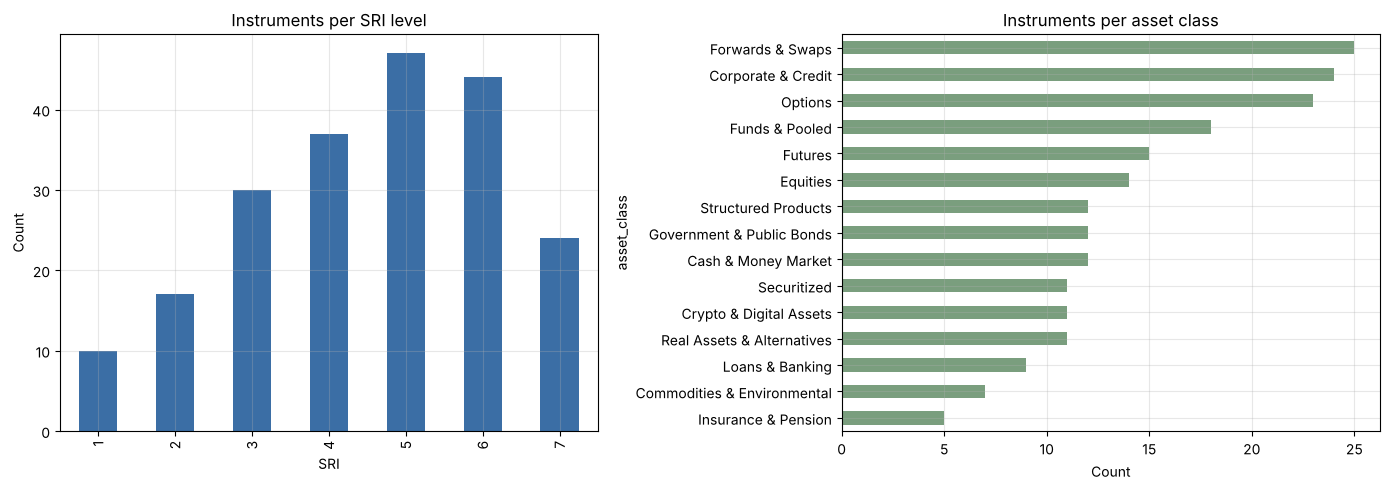

In [4]:
summary = (catalog.groupby("asset_class")
           .agg(n=("name", "size"), sri_mean=("sri", "mean"), sri_min=("sri", "min"), sri_max=("sri", "max"),
                composite_mean=("composite_risk", "mean"), **{f"{d}_mean": (d, "mean") for d in RISK_DIMS})
           .sort_values("composite_mean"))
show(summary.round(2), "Risk summary by asset class (sorted from boring to exciting)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
catalog["sri"].value_counts().sort_index().plot.bar(ax=axes[0], color="#3b6ea5")
axes[0].set(title="Instruments per SRI level", xlabel="SRI", ylabel="Count")
summary["n"].sort_values().plot.barh(ax=axes[1], color="#7a9e7e")
axes[1].set(title="Instruments per asset class", xlabel="Count")
plt.tight_layout(); plt.show()

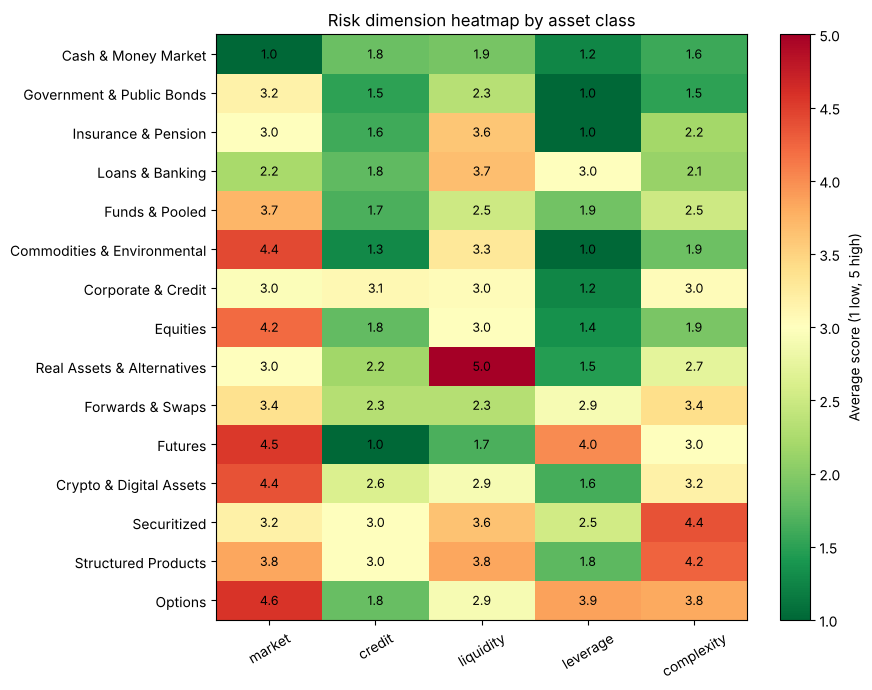

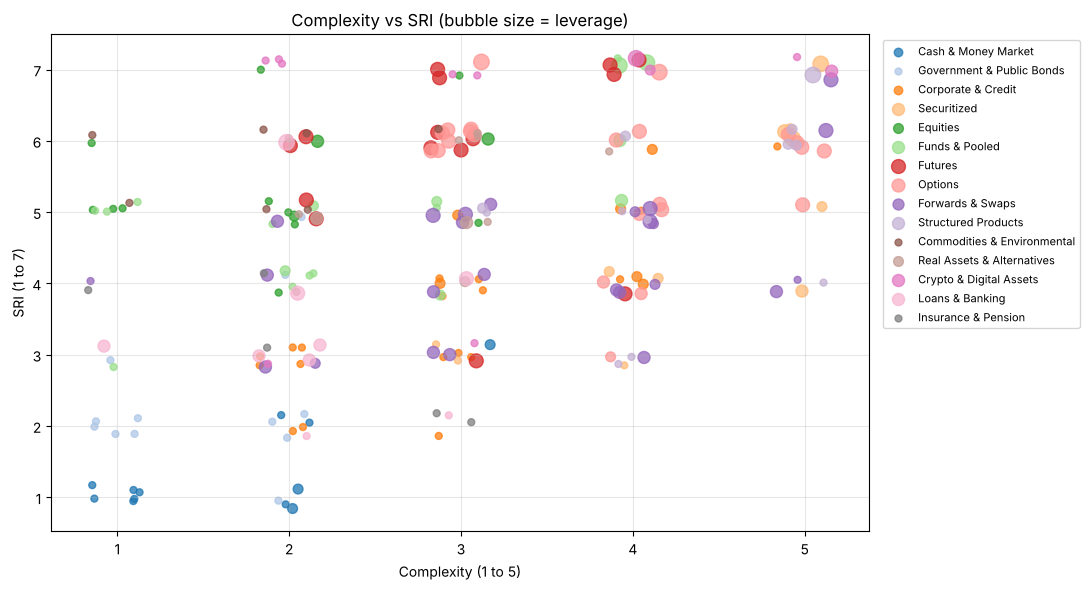


### Top 15 by composite risk (handle with oven mitts)


,name,asset_class,sri,composite_risk
58,CDO-squared,Securitized,7,91.3000
188,Algorithmic stablecoin,Crypto & Digital Assets,7,88.8000
164,Accumulator (KODA),Structured Products,7,87.5000
56,CLO equity tranche,Securitized,6,82.5000
57,Synthetic CDO,Securitized,6,78.8000
124,Lookback option,Options,6,73.8000
126,Spread option,Options,6,73.8000
127,Quanto option,Options,6,73.8000
128,Basket / rainbow option,Options,6,73.8000
190,Crypto perpetual swap,Crypto & Digital Assets,7,73.8000



### Bottom 15 by composite risk (your inflation-losing comfort zone)


,name,asset_class,sri,composite_risk
0,Bank deposit (current account),Cash & Money Market,1,0.0000
1,Savings account,Cash & Money Market,1,0.0000
4,Treasury bill (statsskuldväxel),Cash & Money Market,1,0.0000
2,Term deposit (fasträntekonto),Cash & Money Market,1,3.7000
10,Money market fund,Cash & Money Market,1,6.2000
16,Government floating rate note,Government & Public Bonds,1,6.2000
3,Certificate of deposit (CD),Cash & Money Market,1,10.0000
7,Reverse repo,Cash & Money Market,1,12.5000
9,Securities lending,Cash & Money Market,2,12.5000
22,Premium bond (premieobligation),Government & Public Bonds,2,12.5000


In [5]:
# Heatmap: the "where does the pain come from" picture
hm = catalog.groupby("asset_class")[RISK_DIMS].mean().loc[summary.index]
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(hm.values, cmap="RdYlGn_r", vmin=1, vmax=5, aspect="auto")
ax.set_xticks(range(len(RISK_DIMS)), RISK_DIMS, rotation=30)
ax.set_yticks(range(len(hm)), hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm.values[i, j]:.1f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="Average score (1 low, 5 high)")
ax.set_title("Risk dimension heatmap by asset class"); ax.grid(False)
plt.tight_layout(); plt.show()

# Scatter: complexity vs SRI. Top-right corner is where retail products go to hurt people.
fig, ax = plt.subplots(figsize=(11, 6))
classes = catalog["asset_class"].unique()
cmap = plt.get_cmap("tab20")
jit = np.random.default_rng(SEED).uniform(-0.18, 0.18, size=(len(catalog), 2))
for i, ac in enumerate(classes):
    m = catalog["asset_class"] == ac
    ax.scatter(catalog.loc[m, "complexity"] + jit[m.values, 0], catalog.loc[m, "sri"] + jit[m.values, 1],
               s=catalog.loc[m, "leverage"] * 25, color=cmap(i), alpha=0.75, label=ac)
ax.set(xlabel="Complexity (1 to 5)", ylabel="SRI (1 to 7)", title="Complexity vs SRI (bubble size = leverage)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

show(catalog.nlargest(15, "composite_risk")[["name", "asset_class", "sri", "composite_risk"]],
     "Top 15 by composite risk (handle with oven mitts)")
show(catalog.nsmallest(15, "composite_risk")[["name", "asset_class", "sri", "composite_risk"]],
     "Bottom 15 by composite risk (your inflation-losing comfort zone)")

## 5. Time value of money

| Concept | Formula |
|---|---|
| Simple interest | $I = P\,r\,\frac{d}{B}$ with day basis $B$ (360 or 365) |
| Compound future value | $FV = PV\left(1+\frac{r}{m}\right)^{mT}$ |
| Present value | $PV = \sum_i CF_i (1+r)^{-t_i}$ |
| Annuity payment | $A = P\frac{r/m}{1-(1+r/m)^{-mT}}$ |
| Growing perpetuity | $PV = \frac{CF_1}{r-g}$, $r>g$ |
| NPV / IRR | $NPV(r)=\sum CF_t(1+r)^{-t}$, IRR solves $NPV=0$ |
| Real return (Fisher) | $1+r_{real} = \frac{1+r_{nom}}{1+\pi}$ |

In [6]:
def simple_interest(principal, rate, days, basis=360):
    return principal * rate * days / basis

def fv_compound(pv, rate, years, m=1):
    return pv * (1 + rate / m) ** (m * years)

def pv_cashflows(cfs, times, rate):
    cfs, times = np.asarray(cfs, float), np.asarray(times, float)
    return float(np.sum(cfs / (1 + rate) ** times))

def annuity_payment(principal, rate, years, m=12):
    r, n = rate / m, int(round(years * m))
    return principal / n if r == 0 else principal * r / (1 - (1 + r) ** -n)

def perpetuity(cf, rate, g=0.0):
    if rate <= g:
        raise ValueError("r <= g: infinite value. Congratulations, you broke finance.")
    return cf / (rate - g)

def npv(rate, cfs, times=None):
    times = np.arange(len(cfs)) if times is None else np.asarray(times, float)
    return float(np.sum(np.asarray(cfs, float) / (1 + rate) ** times))

def irr(cfs, times=None, lo=-0.99, hi=10.0):
    # brentq beats np.irr-style polynomial roots: stable, and handles irregular timing
    return optimize.brentq(lambda r: npv(r, cfs, times), lo, hi)

def real_return(nominal, inflation):
    return (1 + nominal) / (1 + inflation) - 1

@demo("simple_interest")
def demo_simple_interest():
    show({"Interest on SEK 1m, 2.0%, 90 days ACT/360": simple_interest(1e6, 0.02, 90),
          "Same on ACT/365": simple_interest(1e6, 0.02, 90, 365)}, "Simple interest")

@demo("fv_compound")
def demo_fv_compound():
    rows = [{"compounding": lbl, "FV of 100k, 3%, 10y": fv_compound(100_000, 0.03, 10, m)}
            for lbl, m in [("annual", 1), ("quarterly", 4), ("monthly", 12), ("daily", 365)]]
    rows.append({"compounding": "continuous", "FV of 100k, 3%, 10y": 100_000 * math.exp(0.03 * 10)})
    show(pd.DataFrame(rows), "Compounding frequency (spoiler: it matters less than fees)")

@demo("annuity_payment")
def demo_annuity():
    pmt = annuity_payment(3_000_000, 0.035, 30)
    show({"Monthly payment, SEK 3m, 3.5%, 30y": pmt, "Total paid": pmt * 360,
          "Total interest": pmt * 360 - 3e6}, "Annuity loan")

@demo("perpetuity")
def demo_perpetuity():
    show({"Consol 4 coupon at 4% yield": perpetuity(4, 0.04),
          "Same at 5% yield": perpetuity(4, 0.05),
          "Price drop for +1pp": perpetuity(4, 0.05) / perpetuity(4, 0.04) - 1,
          "Duration (1+y)/y at 4%": 1.04 / 0.04}, "Perpetuity")

@demo("npv_irr")
def demo_npv_irr():
    cfs = [-1000, 60, 60, 60, 60, 60, 60, 60, 60, 60, 1300]
    show({"NPV at 6%": npv(0.06, cfs), "NPV at 8%": npv(0.08, cfs), "IRR": irr(cfs)}, "NPV / IRR (infrastructure-ish)")

@demo("real_return")
def demo_real_return():
    show({"Gold +8%, CPI 3%: real return": real_return(0.08, 0.03),
          "Savings 1.5%, CPI 3%: real return": real_return(0.015, 0.03)}, "Fisher real return")

for k in ["simple_interest", "fv_compound", "annuity_payment", "perpetuity", "npv_irr", "real_return"]:
    DEMOS[k]()


### Simple interest


,value
"Interest on SEK 1m, 2.0%, 90 days ACT/360","5,000.0000"
Same on ACT/365,"4,931.5068"



### Compounding frequency (spoiler: it matters less than fees)


,compounding,"FV of 100k, 3%, 10y"
0,annual,"134,391.6379"
1,quarterly,"134,834.8612"
2,monthly,"134,935.3547"
3,daily,"134,984.2166"
4,continuous,"134,985.8808"



### Annuity loan


...

,value
Consol 4 coupon at 4% yield,100.0000
Same at 5% yield,80.0000
Price drop for +1pp,-0.2000
Duration (1+y)/y at 4%,26.0000



### NPV / IRR (infrastructure-ish)


,value
NPV at 6%,134.0147
NPV at 8%,-23.0352
IRR,0.0768



### Fisher real return


,value
"Gold +8%, CPI 3%: real return",0.0485
"Savings 1.5%, CPI 3%: real return",-0.0146


## 6. Money market

| Measure | Formula |
|---|---|
| Discount yield | $d = \frac{F-P}{F}\cdot\frac{360}{t}$ |
| Money market yield | $\frac{F-P}{P}\cdot\frac{360}{t}$ |
| Bond equivalent yield | $\frac{F-P}{P}\cdot\frac{365}{t}$ |
| Effective annual yield | $(F/P)^{365/t}-1$ |
| Repo | Cash $= MV(1-h)$, repurchase price $= \text{Cash}\,(1 + r\,t/360)$ |
| Compounded overnight (SWESTR/SOFR/ESTR) | $\left[\prod_i\left(1+\frac{r_i d_i}{360}\right)-1\right]\frac{360}{D}$ |

In [7]:
def money_market_yields(price, face, days):
    return {"price": price,
            "discount_yield": (face - price) / face * 360 / days,
            "money_market_yield": (face - price) / price * 360 / days,
            "bond_equivalent_yield": (face - price) / price * 365 / days,
            "effective_annual_yield": (face / price) ** (365 / days) - 1}

def repo_calc(collateral_mv, haircut, repo_rate, days, basis=360):
    cash = collateral_mv * (1 - haircut)
    interest = cash * repo_rate * days / basis
    return {"cash_lent": cash, "repo_interest": interest, "repurchase_price": cash + interest,
            "collateral_cushion": collateral_mv - cash,
            "collateral_drop_until_undercollateralized": 1 - (cash + interest) / collateral_mv}

def ois_compounding(daily_rates, day_counts, basis=360):
    daily_rates, day_counts = np.asarray(daily_rates), np.asarray(day_counts)
    growth = np.prod(1 + daily_rates * day_counts / basis)
    return (growth - 1) * basis / day_counts.sum()

@demo("money_market_yields")
def demo_mm():
    show(money_market_yields(price=99.25, face=100, days=182), "182-day T-bill at 99.25")

@demo("repo_calc")
def demo_repo():
    show(repo_calc(collateral_mv=10_200_000, haircut=0.02, repo_rate=0.0225, days=7), "7-day repo on govvies")

@demo("ois_compounding")
def demo_ois():
    # 3 months of business days; weekends get 3-day weights because Friday's rate works overtime
    rng = np.random.default_rng(SEED)
    dates = pd.bdate_range("2026-01-02", "2026-03-31")
    dc = np.diff(np.append(dates.values, np.datetime64("2026-04-01"))).astype("timedelta64[D]").astype(int)
    rates = 0.0200 + np.cumsum(rng.normal(0, 0.00003, len(dates)))
    rates[len(rates) // 2:] -= 0.0025  # a policy cut halfway through, central banks love drama
    show({"simple avg fixing": rates.mean(), "compounded rate": ois_compounding(rates, dc),
          "days": dc.sum()}, "Compounded overnight rate over a quarter")

for k in ["money_market_yields", "repo_calc", "ois_compounding"]:
    DEMOS[k]()


### 182-day T-bill at 99.25


,value
price,99.2500
discount_yield,0.0148
money_market_yield,0.0149
bond_equivalent_yield,0.0152
effective_annual_yield,0.0152



### 7-day repo on govvies


,value
cash_lent,"9,996,000.0000"
repo_interest,"4,373.2500"
repurchase_price,"10,000,373.2500"
collateral_cushion,"204,000.0000"
collateral_drop_until_undercollateralized,0.0196



### Compounded overnight rate over a quarter


,value
simple avg fixing,0.0188
compounded rate,0.0188
days,89.0000


## 7. Bonds and interest rate curves

| Concept | Formula |
|---|---|
| Price | $P = \sum_{i=1}^{n}\frac{C/f}{(1+y/f)^{i}} + \frac{F}{(1+y/f)^{n}}$ |
| Macaulay duration | $D_{mac} = \frac{1}{P}\sum t_i\,PV(CF_i)$ |
| Modified duration | $D_{mod} = \frac{D_{mac}}{1+y/f}$ |
| Convexity | $\frac{1}{P}\sum \frac{PV(CF_i)\,t_i(t_i+1/f)}{(1+y/f)^2}$ |
| Price change | $\frac{\Delta P}{P}\approx -D_{mod}\Delta y + \tfrac12 C\,\Delta y^2$ |
| DV01 | $D_{mod}\cdot P\cdot 0.0001$ |
| Bootstrap | $DF_n = \frac{1 - c_n\sum_{i<n}DF_i}{1+c_n}$ (annual par bonds) |
| Forward rate | $f_{t_1,t_2} = \left(\frac{DF_{t_1}}{DF_{t_2}}\right)^{1/(t_2-t_1)}-1$ |
| Inflation-linked | Settlement $=$ real price $\times \frac{CPI_{settle}}{CPI_{base}}$; breakeven $\frac{1+y_{nom}}{1+y_{real}}-1$ |
| Z-spread | $z$ such that $P_{mkt} = \sum CF_i\,(1+z_i+z)^{-t_i}$ |

Callable/puttable bonds use a **Black-Derman-Toy** short-rate tree calibrated to the zero curve. Convertibles use a **Tsiveriotis-Fernandes** split tree (cash part discounted with credit spread, equity part risk-free).


### 10y 2.5% annual bond at 3% yield


,value
price,95.7349
macaulay_duration,8.9434
modified_duration,8.6829
convexity,89.2189
dv01_per_100,0.0831
approx dP/P for +100bp,-0.0824
exact dP/P for +100bp,-0.0825
YTM back-solved from price,0.0300
accrued (73 of 365 days),0.5000


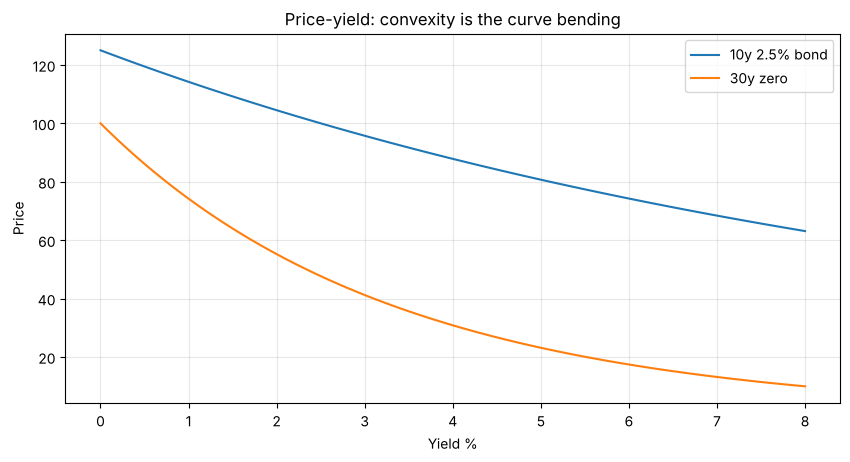

In [8]:
def bond_cashflows(face, coupon_rate, years, freq=1):
    n = int(round(years * freq))
    t = np.arange(1, n + 1) / freq
    cf = np.full(n, face * coupon_rate / freq)
    cf[-1] += face
    return t, cf

def bond_price(face, coupon_rate, ytm, years, freq=1):
    t, cf = bond_cashflows(face, coupon_rate, years, freq)
    return float(np.sum(cf / (1 + ytm / freq) ** (t * freq)))

def bond_ytm(price, face, coupon_rate, years, freq=1):
    return optimize.brentq(lambda y: bond_price(face, coupon_rate, y, years, freq) - price, -0.5, 2.0)

def bond_risk(face, coupon_rate, ytm, years, freq=1):
    t, cf = bond_cashflows(face, coupon_rate, years, freq)
    disc = (1 + ytm / freq) ** (t * freq)
    pv = cf / disc
    P = pv.sum()
    mac = np.sum(t * pv) / P
    mod = mac / (1 + ytm / freq)
    conv = np.sum(pv * t * (t + 1 / freq)) / (P * (1 + ytm / freq) ** 2)
    return {"price": P, "macaulay_duration": mac, "modified_duration": mod, "convexity": conv,
            "dv01_per_100": mod * P * 1e-4}

def accrued_interest(face, coupon_rate, freq, days_since_coupon, days_in_period):
    return face * coupon_rate / freq * days_since_coupon / days_in_period

@demo("bond_price")
def demo_bond():
    r = bond_risk(100, 0.025, 0.03, 10, 1)
    dy = 0.01
    approx = -r["modified_duration"] * dy + 0.5 * r["convexity"] * dy ** 2
    exact = bond_price(100, 0.025, 0.03 + dy, 10) / r["price"] - 1
    r.update({"approx dP/P for +100bp": approx, "exact dP/P for +100bp": exact,
              "YTM back-solved from price": bond_ytm(r["price"], 100, 0.025, 10),
              "accrued (73 of 365 days)": accrued_interest(100, 0.025, 1, 73, 365)})
    show(r, "10y 2.5% annual bond at 3% yield")
    ys = np.linspace(0.0, 0.08, 81)
    plt.plot(ys * 100, [bond_price(100, 0.025, y, 10) for y in ys], label="10y 2.5% bond")
    plt.plot(ys * 100, [bond_price(100, 0, y, 30) for y in ys], label="30y zero")
    plt.xlabel("Yield %"); plt.ylabel("Price"); plt.title("Price-yield: convexity is the curve bending")
    plt.legend(); plt.show()

DEMOS["bond_price"]()


### Bootstrapped curve from par yields


,par,df,zero,fwd_1y
t,,,,
1,0.0200,0.9804,0.0200,0.0200
2,0.0210,0.9593,0.0210,0.0220
3,0.0222,0.9362,0.0222,0.0247
4,0.0233,0.9117,0.0234,0.0268
5,0.0243,0.8864,0.0244,0.0286
6,0.0252,0.8605,0.0254,0.0301
7,0.0260,0.8344,0.0262,0.0313
8,0.0267,0.8084,0.0269,0.0322
9,0.0273,0.7827,0.0276,0.0328


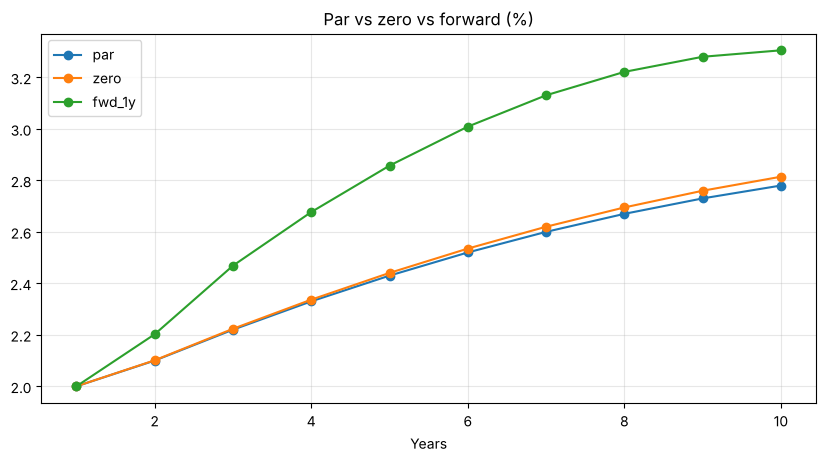


### Zero-coupon prices


,value
Zero-coupon 10y price per 100,75.7650
STRIP 7y price per 100,83.4408



### Nordic HY FRN: price vs required margin (rate duration small, spread duration not)


,discount_margin_bp,"price (3m STIBOR 2.1% + 400bp, 3y)"
0,300.0000,102.7655
1,350.0000,101.3720
2,400.0000,100.0000
3,500.0000,97.3193
4,700.0000,92.2008



### Swedish real bond style example


,value
real_clean_price,96.5108
index_ratio,1.2582
settlement_price,121.4281
breakeven_inflation,0.0184



### 5y 4% corporate across the rating spectrum


,rating,spread_bp,price,z_spread_check_bp,price_if_+100bp
0,AAA covered,30.0000,105.8909,30.0000,101.2409
1,A,80.0000,103.5330,80.0000,99.0124
2,BBB,140.0000,100.7901,140.0000,96.4194
3,BB,300.0000,93.9116,300.0000,89.9124
4,B,500.0000,86.1265,500.0000,82.5406
5,CCC,"1,100.0000",67.2063,"1,100.0000",64.5885


In [9]:
def bootstrap_par_curve(par_rates):
    """Annual par yields for 1..N years -> discount factors, zero rates and 1y forwards."""
    par_rates = np.asarray(par_rates, float)
    dfs = []
    for n, c in enumerate(par_rates, start=1):
        dfs.append((1 - c * sum(dfs)) / (1 + c))
    dfs = np.array(dfs)
    t = np.arange(1, len(par_rates) + 1)
    zeros = dfs ** (-1 / t) - 1
    fwds = np.append(zeros[0], dfs[:-1] / dfs[1:] - 1)
    return pd.DataFrame({"t": t, "par": par_rates, "df": dfs, "zero": zeros, "fwd_1y": fwds}).set_index("t")

class DiscountCurve:
    """Zero curve with linear interpolation on zero rates (annual comp). Not fancy, but honest."""
    def __init__(self, tenors, zeros):
        self.t = np.asarray(tenors, float)
        self.z = np.asarray(zeros, float)
    def zero(self, t):
        return np.interp(t, self.t, self.z)
    def df(self, t):
        t = np.asarray(t, float)
        return (1 + self.zero(t)) ** (-t)
    def fwd_simple(self, t1, t2):
        return (self.df(t1) / self.df(t2) - 1) / (t2 - t1)
    def shifted(self, bp):
        return DiscountCurve(self.t, self.z + bp / 1e4)

# A plausible SEK-ish curve. Plausible, not real. Replace with Riksbank/Bloomberg data before betting the house.
PAR_RATES = [0.0200, 0.0210, 0.0222, 0.0233, 0.0243, 0.0252, 0.0260, 0.0267, 0.0273, 0.0278]
BOOT = bootstrap_par_curve(PAR_RATES)
CURVE = DiscountCurve(np.r_[0.0, BOOT.index.values], np.r_[BOOT["zero"].iloc[0], BOOT["zero"].values])

@demo("zero_curve")
def demo_zero_curve():
    show(BOOT, "Bootstrapped curve from par yields")
    BOOT[["par", "zero", "fwd_1y"]].mul(100).plot(marker="o", title="Par vs zero vs forward (%)")
    plt.xlabel("Years"); plt.show()
    show({"Zero-coupon 10y price per 100": 100 * float(CURVE.df(10)),
          "STRIP 7y price per 100": 100 * float(CURVE.df(7))}, "Zero-coupon prices")

def frn_value(face, ref_rate, quoted_margin, discount_margin, years, freq=4):
    """FRN priced with flat projected reference rate. QM = what you get, DM = what the market wants."""
    n = int(round(years * freq))
    t = np.arange(1, n + 1)
    cpn = face * (ref_rate + quoted_margin) / freq
    disc = (1 + (ref_rate + discount_margin) / freq) ** t
    cf = np.full(n, cpn); cf[-1] += face
    return float(np.sum(cf / disc))

@demo("frn_value")
def demo_frn():
    rows = []
    for dm in [0.0300, 0.0350, 0.0400, 0.0500, 0.0700]:
        rows.append({"discount_margin_bp": dm * 1e4,
                     "price (3m STIBOR 2.1% + 400bp, 3y)": frn_value(100, 0.021, 0.04, dm, 3)})
    show(pd.DataFrame(rows), "Nordic HY FRN: price vs required margin (rate duration small, spread duration not)")

def inflation_linked_bond(face, real_coupon, real_yield, years, cpi_base, cpi_settle, nominal_yield=None):
    real_price = bond_price(face, real_coupon, real_yield, years)
    ir = cpi_settle / cpi_base
    out = {"real_clean_price": real_price, "index_ratio": ir, "settlement_price": real_price * ir}
    if nominal_yield is not None:
        out["breakeven_inflation"] = (1 + nominal_yield) / (1 + real_yield) - 1
    return out

@demo("inflation_linked_bond")
def demo_ilb():
    show(inflation_linked_bond(100, 0.0025, 0.007, 8, cpi_base=330.0, cpi_settle=415.2, nominal_yield=0.0255),
         "Swedish real bond style example")

def bond_price_spread(face, coupon_rate, years, curve, spread, freq=1):
    t, cf = bond_cashflows(face, coupon_rate, years, freq)
    return float(np.sum(cf * (1 + curve.zero(t) + spread) ** (-t)))

def z_spread(price, face, coupon_rate, years, curve, freq=1):
    return optimize.brentq(lambda s: bond_price_spread(face, coupon_rate, years, curve, s, freq) - price, -0.05, 1.0)

@demo("credit_spread_price")
def demo_credit():
    rows = []
    for rating, spr in [("AAA covered", 0.003), ("A", 0.008), ("BBB", 0.014), ("BB", 0.030), ("B", 0.050), ("CCC", 0.110)]:
        p = bond_price_spread(100, 0.04, 5, CURVE, spr)
        rows.append({"rating": rating, "spread_bp": spr * 1e4, "price": p,
                     "z_spread_check_bp": z_spread(p, 100, 0.04, 5, CURVE) * 1e4,
                     "price_if_+100bp": bond_price_spread(100, 0.04, 5, CURVE, spr + 0.01)})
    show(pd.DataFrame(rows), "5y 4% corporate across the rating spectrum")

for k in ["zero_curve", "frn_value", "inflation_linked_bond", "credit_spread_price"]:
    DEMOS[k]()

In [10]:
def bdt_tree(curve, years, steps_per_year, sigma):
    """Black-Derman-Toy with constant vol: r[i][j] = a_i * exp(sigma*sqrt(dt)*(2j - i)).
    a_i is solved step by step so the tree reprices every zero on the curve. Uncalibrated trees are just vibes."""
    n = int(round(years * steps_per_year))
    dt = 1 / steps_per_year
    rates = []
    Q = np.array([1.0])  # Arrow-Debreu prices at step i
    for i in range(n):
        shape = np.exp(sigma * math.sqrt(dt) * (2 * np.arange(i + 1) - i))
        target = float(curve.df((i + 1) * dt))
        f = lambda a: np.sum(Q / (1 + a * shape * dt)) - target
        a = optimize.brentq(f, -0.5, 2.0)
        r = a * shape
        rates.append(r)
        # forward induction: each node splits 50/50 up and down
        disc = Q / (1 + r * dt)
        Qn = np.zeros(i + 2)
        Qn[:-1] += 0.5 * disc
        Qn[1:] += 0.5 * disc
        Q = Qn
    return rates, dt

def tree_bond_value(rates, dt, face, coupon_rate, call_price=None, put_price=None, first_exercise=0.0):
    n = len(rates)
    cpn = face * coupon_rate * dt
    V = np.full(n + 1, face + cpn)
    for i in range(n - 1, -1, -1):
        cont = 0.5 * (V[1:] + V[:-1]) / (1 + rates[i] * dt)
        t = i * dt
        if t >= first_exercise and i > 0:
            if call_price is not None:
                cont = np.minimum(cont, call_price)  # issuer calls when the bond is worth more than the strike
            if put_price is not None:
                cont = np.maximum(cont, put_price)   # investor puts when it is worth less
        V = cont + (cpn if i > 0 else 0.0)
    return float(V[0])

@demo("callable_bond_tree")
def demo_callable():
    rates, dt = bdt_tree(CURVE, 10, 4, sigma=0.20)
    check = tree_bond_value(rates, dt, 100, 0.0)  # zero coupon through the tree should hit the curve
    straight = tree_bond_value(rates, dt, 100, 0.03)
    callable_ = tree_bond_value(rates, dt, 100, 0.03, call_price=100, first_exercise=5)
    puttable = tree_bond_value(rates, dt, 100, 0.03, put_price=100, first_exercise=5)
    show({"calibration check: 10y zero via tree": check, "curve 10y DF x 100": 100 * float(CURVE.df(10)),
          "straight 3% 10y": straight, "callable at par after 5y (10NC5)": callable_,
          "embedded call value (investor short)": straight - callable_,
          "puttable at par after 5y": puttable, "embedded put value (investor long)": puttable - straight},
         "BDT tree, 20% short-rate vol, quarterly steps")

def convertible_value(S0, conv_ratio, face, coupon_rate, years, r, credit_spread, sigma, q=0.0,
                      steps_per_year=50, call_price=None):
    """Tsiveriotis-Fernandes on a CRR tree. Returns total value and its bond/equity split."""
    n = int(years * steps_per_year); dt = years / n
    u = math.exp(sigma * math.sqrt(dt)); d = 1 / u
    p = (math.exp((r - q) * dt) - d) / (u - d)
    S = S0 * u ** np.arange(n, -1, -1) * d ** np.arange(0, n + 1)
    cpn_steps = set(int(round(k * steps_per_year)) for k in range(1, int(years) + 1))
    cpn = face * coupon_rate
    conv = conv_ratio * S
    redeem = face + cpn
    convert = conv > redeem
    E = np.where(convert, conv, 0.0)          # equity component
    B = np.where(convert, 0.0, redeem)        # cash-only component (carries credit risk)
    for i in range(n - 1, -1, -1):
        S = S[:-1] / u
        E = math.exp(-r * dt) * (p * E[:-1] + (1 - p) * E[1:])
        B = math.exp(-(r + credit_spread) * dt) * (p * B[:-1] + (1 - p) * B[1:])
        if i in cpn_steps:
            B = B + cpn
        hold = E + B
        conv = conv_ratio * S
        if call_price is not None:
            called = hold > call_price  # issuer forces conversion or redeems, whichever hurts us more
            forced = np.maximum(conv, call_price)
            E = np.where(called, np.where(conv >= call_price, conv, 0.0), E)
            B = np.where(called, np.where(conv >= call_price, 0.0, call_price), B)
            hold = np.where(called, forced, hold)
        do_conv = conv > hold
        E = np.where(do_conv, conv, E)
        B = np.where(do_conv, 0.0, B)
    straight = bond_price(face, coupon_rate, r + credit_spread, years)
    return {"convertible_value": float(E[0] + B[0]), "equity_component": float(E[0]),
            "debt_component": float(B[0]), "bond_floor": straight, "parity (conv value)": conv_ratio * S0,
            "premium_over_parity": (E[0] + B[0]) / (conv_ratio * S0) - 1}

@demo("convertible_value")
def demo_convertible():
    show(convertible_value(S0=50, conv_ratio=1.6, face=100, coupon_rate=0.015, years=5, r=0.025,
                           credit_spread=0.03, sigma=0.30), "5y convertible, conversion price 62.5")

def coco_trigger_sim(cet1_0=0.13, trigger=0.07, drift=0.0, vol=0.012, years=5, n_paths=50_000,
                     coupon=0.08, r=0.025, writedown=1.0):
    """CET1 ratio as arithmetic random walk with jumps. Crude, but the shape of the risk is right:
    nothing, nothing, nothing, then everything."""
    rng = np.random.default_rng(SEED)
    steps = years * 12
    shocks = rng.normal(drift / 12, vol / math.sqrt(12), (n_paths, steps))
    jumps = rng.binomial(1, 0.02 / 12, (n_paths, steps)) * rng.normal(-0.03, 0.01, (n_paths, steps))
    path = cet1_0 + np.cumsum(shocks + jumps, axis=1)
    hit = path <= trigger
    first = np.where(hit.any(axis=1), hit.argmax(axis=1), steps)
    t_hit = first / 12
    # Value: coupons until trigger (or call at year 5), principal written down on trigger
    pv_cpn = np.array([sum(coupon * math.exp(-r * k) for k in range(1, int(min(th, years)) + 1)) for th in t_hit])
    pv_prin = np.where(first < steps, (1 - writedown) * np.exp(-r * t_hit), np.exp(-r * years))
    return {"P(trigger within horizon)": hit.any(axis=1).mean(), "fair price per 1 nominal": (pv_cpn + pv_prin).mean(),
            "price if no trigger risk": sum(coupon * math.exp(-r * k) for k in range(1, years + 1)) + math.exp(-r * years)}

@demo("coco_trigger_sim")
def demo_coco():
    show(coco_trigger_sim(), "AT1 CoCo: CET1 13% start, 7% trigger, full write-down")

for k in ["callable_bond_tree", "convertible_value", "coco_trigger_sim"]:
    DEMOS[k]()


### BDT tree, 20% short-rate vol, quarterly steps


,value
calibration check: 10y zero via tree,75.7650
curve 10y DF x 100,75.7650
straight 3% 10y,102.1922
callable at par after 5y (10NC5),100.0549
embedded call value (investor short),2.1373
puttable at par after 5y,105.0248
embedded put value (investor long),2.8326



### 5y convertible, conversion price 62.5


,value
convertible_value,104.1299
equity_component,46.5309
debt_component,57.5989
bond_floor,82.9189
parity (conv value),80.0000
premium_over_parity,0.3016



### AT1 CoCo: CET1 13% start, 7% trigger, full write-down


,value
P(trigger within horizon),0.0416
fair price per 1 nominal,1.2112
price if no trigger risk,1.2538


## 8. Credit and securitization

| Concept | Formula |
|---|---|
| Expected loss | $EL = PD\times LGD\times EAD$ |
| Cumulative PD from hazard | $PD(t) = 1-e^{-\lambda t}$ |
| CDS par spread | $s = \frac{(1-R)\sum DF_i(Q_{i-1}-Q_i)}{\sum \tau_i DF_i Q_i}$, rule of thumb $s\approx\lambda(1-R)$ |
| PSA prepayment | $CPR_t = \min(t/30,1)\times 6\%\times\frac{PSA}{100}$, $SMM = 1-(1-CPR)^{1/12}$ |
| Vasicek large pool | $L(M) = LGD\cdot\Phi\!\left(\frac{\Phi^{-1}(PD)-\sqrt\rho M}{\sqrt{1-\rho}}\right)$ |
| Tranche loss $[A,D]$ | $\frac{\mathbb{E}[\min(\max(L-A,0),D-A)]}{D-A}$ |
| ICR / DSCR / LTV | $\frac{EBITDA}{Interest}$, $\frac{NOI}{Interest+Amortization}$, $\frac{Debt}{Value}$ |


### Expected loss over 3 years on 1m exposure


,cumulative_PD,LGD,EAD,expected_loss,breakeven_spread_approx
instrument,,,,,
Senior secured loan,0.0588,0.3500,1000000,"20,582.8000",0.0070
Unsecured HY bond,0.1153,0.6000,1000000,"69,158.4000",0.0240
P2P consumer loan,0.2213,0.8500,1000000,"188,115.2000",0.0680
Cat bond (attach prob),0.0588,1.0000,1000000,"58,808.0000",0.0200



### 5y CDS


,value
"implied hazard (150bp, R=40%)",0.0250
rule of thumb s/(1-R),0.0250
5y implied cumulative PD,0.1175
RPV01,4.4397
"MTM to protection buyer if spread -> 250bp, 10m notional","426,704.8514"



### MBS / IO / PO value per 100 at 4.5% yield vs prepayment speed


,pass_through,IO_strip,PO_strip,WAL_years
PSA,,,,
50,100.0000,43.1493,56.8507,14.1156
100,100.0000,35.8171,64.1829,11.0889
200,100.0000,26.5229,73.4771,7.5403
400,100.0000,17.6321,82.3679,4.5568
800,100.0000,11.1392,88.8608,2.6875


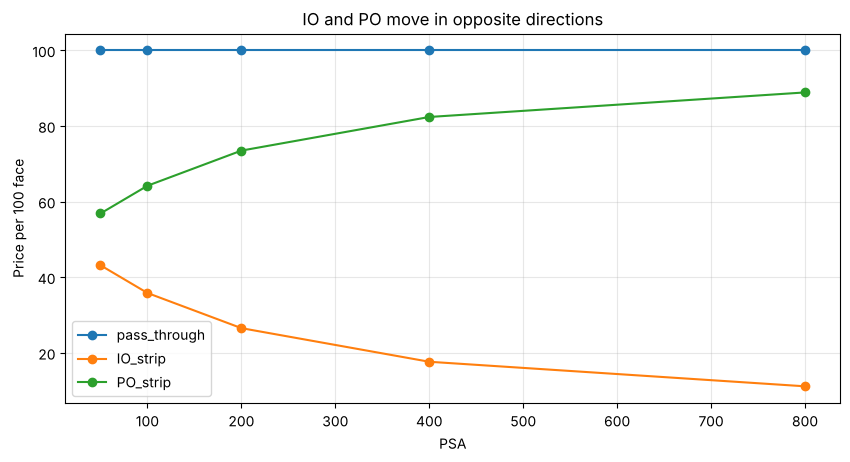


### Expected tranche loss (pool PD 3%, LGD 60%). Equity likes correlation, seniors hate it.


,Equity 0-3%,Mezz 3-7%,Senior 7-15%,Super senior 15-100%
correlation,,,,
0.0500,0.5716,0.0212,0.0001,0.0000
0.1500,0.4894,0.0711,0.0057,0.0000
0.3000,0.3909,0.1008,0.0234,0.0004
0.6000,0.2360,0.1020,0.0473,0.0036



### CRE loan covenant check (SEK)


,value
ICR,2.4167
DSCR,1.8235
LTV,0.5714
ICR covenant ok,True
LTV covenant ok,True
value drop to breach LTV,0.1209
"rate rise to breach ICR (pp, all floating)",1.8333


In [11]:
def expected_loss(pd_annual, lgd, ead, years=1):
    cum_pd = 1 - (1 - pd_annual) ** years
    return {"cumulative_PD": cum_pd, "LGD": lgd, "EAD": ead, "expected_loss": cum_pd * lgd * ead,
            "breakeven_spread_approx": pd_annual * lgd}

@demo("expected_loss")
def demo_el():
    rows = []
    for name, pdv, lgd in [("Senior secured loan", 0.02, 0.35), ("Unsecured HY bond", 0.04, 0.60),
                           ("P2P consumer loan", 0.08, 0.85), ("Cat bond (attach prob)", 0.02, 1.0)]:
        r = expected_loss(pdv, lgd, 1_000_000, years=3); r["instrument"] = name; rows.append(r)
    show(pd.DataFrame(rows).set_index("instrument"), "Expected loss over 3 years on 1m exposure")

def cds_par_spread(hazard, recovery, maturity, curve, freq=4):
    t = np.arange(1, int(maturity * freq) + 1) / freq
    Q = np.exp(-hazard * t)
    Qprev = np.r_[1.0, Q[:-1]]
    dfs = curve.df(t)
    prot = (1 - recovery) * np.sum(dfs * (Qprev - Q))
    rpv01 = np.sum((1 / freq) * dfs * 0.5 * (Q + Qprev))  # mid-period default accrual approximation
    return prot / rpv01, rpv01

def hazard_from_spread(spread, recovery, maturity, curve):
    return optimize.brentq(lambda h: cds_par_spread(h, recovery, maturity, curve)[0] - spread, 1e-8, 5)

@demo("cds_spread")
def demo_cds():
    h = hazard_from_spread(0.0150, 0.40, 5, CURVE)
    s_now, rpv01 = cds_par_spread(h, 0.40, 5, CURVE)
    h_wide = hazard_from_spread(0.0250, 0.40, 5, CURVE)
    s_w, rpv01_w = cds_par_spread(h_wide, 0.40, 5, CURVE)
    mtm_buyer = (s_w - 0.0150) * rpv01_w * 10_000_000
    show({"implied hazard (150bp, R=40%)": h, "rule of thumb s/(1-R)": 0.015 / 0.6,
          "5y implied cumulative PD": 1 - math.exp(-5 * h), "RPV01": rpv01,
          "MTM to protection buyer if spread -> 250bp, 10m notional": mtm_buyer}, "5y CDS")

def mbs_cashflows(balance, wac, wam_months, psa=100, servicing=0.005):
    r = wac / 12; net = (wac - servicing) / 12
    rows = []
    bal = balance
    for m in range(1, wam_months + 1):
        if bal <= 1e-8: break
        cpr = min(m / 30, 1) * 0.06 * psa / 100
        smm = 1 - (1 - cpr) ** (1 / 12)
        n_left = wam_months - m + 1
        pmt = bal * r / (1 - (1 + r) ** -n_left)
        interest = bal * net
        sched = pmt - bal * r
        prepay = (bal - sched) * smm
        rows.append({"month": m, "begin_bal": bal, "interest": interest, "sched_principal": sched, "prepay": prepay})
        bal -= sched + prepay
    return pd.DataFrame(rows)

def price_cf(cfs, annual_yield):
    m = np.arange(1, len(cfs) + 1)
    return float(np.sum(np.asarray(cfs) / (1 + annual_yield / 12) ** m))

@demo("mbs_cashflows")
def demo_mbs():
    rows = []
    for psa in [50, 100, 200, 400, 800]:
        cf = mbs_cashflows(100.0, 0.05, 360, psa)
        prin = cf["sched_principal"] + cf["prepay"]
        rows.append({"PSA": psa, "pass_through": price_cf(cf["interest"] + prin, 0.045),
                     "IO_strip": price_cf(cf["interest"], 0.045), "PO_strip": price_cf(prin, 0.045),
                     "WAL_years": float((cf["month"] * prin).sum() / prin.sum() / 12)})
    df = pd.DataFrame(rows).set_index("PSA")
    show(df, "MBS / IO / PO value per 100 at 4.5% yield vs prepayment speed")
    df[["pass_through", "IO_strip", "PO_strip"]].plot(marker="o", title="IO and PO move in opposite directions")
    plt.ylabel("Price per 100 face"); plt.show()

def vasicek_tranche_el(pd_, rho, lgd, attach, detach, n_nodes=200):
    """Expected tranche loss under the one-factor Gaussian large homogeneous pool."""
    x, w = np.polynomial.hermite_e.hermegauss(n_nodes)    # probabilists' Hermite: weight exp(-x^2/2)
    w = w / w.sum()
    L = lgd * norm.cdf((norm.ppf(pd_) - math.sqrt(rho) * x) / math.sqrt(1 - rho))
    tl = np.clip(L - attach, 0, detach - attach) / (detach - attach)
    return float(np.sum(w * tl))

@demo("tranche_loss")
def demo_tranche():
    tranches = [("Equity 0-3%", 0, .03), ("Mezz 3-7%", .03, .07), ("Senior 7-15%", .07, .15),
                ("Super senior 15-100%", .15, 1.0)]
    rows = []
    for rho in [0.05, 0.15, 0.30, 0.60]:
        row = {"correlation": rho}
        for nm, a, d in tranches:
            row[nm] = vasicek_tranche_el(0.03, rho, 0.6, a, d)
        rows.append(row)
    df = pd.DataFrame(rows).set_index("correlation")
    show(df, "Expected tranche loss (pool PD 3%, LGD 60%). Equity likes correlation, seniors hate it.")

def dscr_icr(noi, ebitda, interest, amortization, debt, value, icr_cov=1.5, ltv_cov=0.65):
    out = {"ICR": ebitda / interest, "DSCR": noi / (interest + amortization), "LTV": debt / value}
    out["ICR covenant ok"] = out["ICR"] >= icr_cov
    out["LTV covenant ok"] = out["LTV"] <= ltv_cov
    out["value drop to breach LTV"] = 1 - debt / (ltv_cov * value)
    out["rate rise to breach ICR (pp, all floating)"] = (ebitda / icr_cov - interest) / debt * 100
    return out

@demo("dscr_icr")
def demo_dscr():
    show(dscr_icr(noi=62e6, ebitda=58e6, interest=24e6, amortization=10e6, debt=800e6, value=1.4e9),
         "CRE loan covenant check (SEK)")

for k in ["expected_loss", "cds_spread", "mbs_cashflows", "tranche_loss", "dscr_icr"]:
    DEMOS[k]()

## 9. Equities and funds

| Concept | Formula |
|---|---|
| Gordon growth | $P_0 = \frac{D_0(1+g)}{r-g}$ |
| CAPM | $\mathbb{E}[R_i] = r_f + \beta_i(\mathbb{E}[R_m]-r_f)$, $\beta = \frac{Cov(R_i,R_m)}{Var(R_m)}$ |
| NAV discount | $\frac{P}{NAV}-1$ |
| TERP (rights issue) | $\frac{N_{old}P_{cum}+N_{new}S}{N_{old}+N_{new}}$, right value $=(TERP-S)\frac{N_{new}}{N_{old}}$ |
| Fee drag | $(1+r-fee)^T$ vs $(1+r)^T$ |
| Tracking error | $\sigma(R_p-R_b)\sqrt{252}$, IR $=\frac{\overline{R_p-R_b}\cdot 252}{TE}$ |
| Leveraged ETF decay | $\approx \exp\!\left(\tfrac{L-L^2}{2}\sigma^2T\right)$ relative to $L\times$ index |
| Private equity | IRR, TVPI $=\frac{Dist+NAV}{Paid in}$, DPI $=\frac{Dist}{Paid in}$ |
| Sharpe / Sortino | $\frac{\bar R - r_f}{\sigma}$, $\frac{\bar R - r_f}{\sigma_{down}}$ |


### Dividend discount model (sensitivity to r is the whole story)


,value
"Gordon (D0=6, g=3%, r=8%)",123.6000
Same with r=9%,103.0000
Two-stage (10% for 5y then 3%),167.1846



### Beta regression on 3y of daily data


,value
estimated beta (true 1.3),1.2910
annualized alpha,0.0030
R^2,0.5626
"CAPM required return (rf 2.5%, Rm 8%)",0.0960



### Price vs NAV


...

,gross_end_value,net_end_value,fees_cost_total,share_lost
product,,,,
Index fund 0.10%,"3,806,127.5213","3,700,847.2530","105,280.2684",0.0277
Active fund 1.4%,"3,806,127.5213","2,563,820.1133","1,242,307.4081",0.3264
Fund of funds 2.0%,"3,806,127.5213","2,160,971.1876","1,645,156.3338",0.4322
Unit-linked 1.4% + 0.6% wrapper,"3,806,127.5213","2,160,971.1876","1,645,156.3338",0.4322



### Tracking error and difference


,physical ETF,synthetic ETF
tracking_error,0.0064,0.0016
tracking_difference_ann,-0.0011,-0.0033
information_ratio,-0.1697,-2.1011



### Daily reset products over 1 year, flat market, 25% vol: the slow bleed


,leverage,median idx return,median product return,naive L x idx (median),P(product < 0),decay factor approx exp((L-L^2)s^2T/2)
0,2,-0.0274,-0.1110,-0.0549,0.5950,0.9394
1,3,-0.0274,-0.2364,-0.0823,0.6428,0.8290
2,-1,-0.0274,-0.0345,0.0274,0.5548,0.9394
3,-3,-0.0274,-0.2538,0.0823,0.6494,0.6873


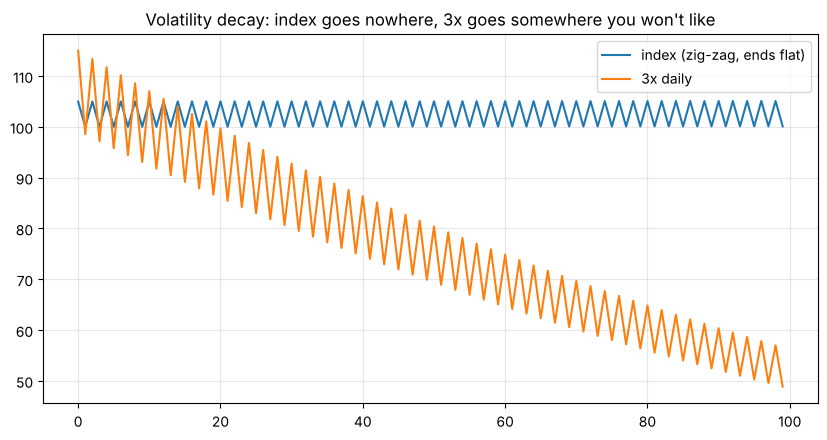

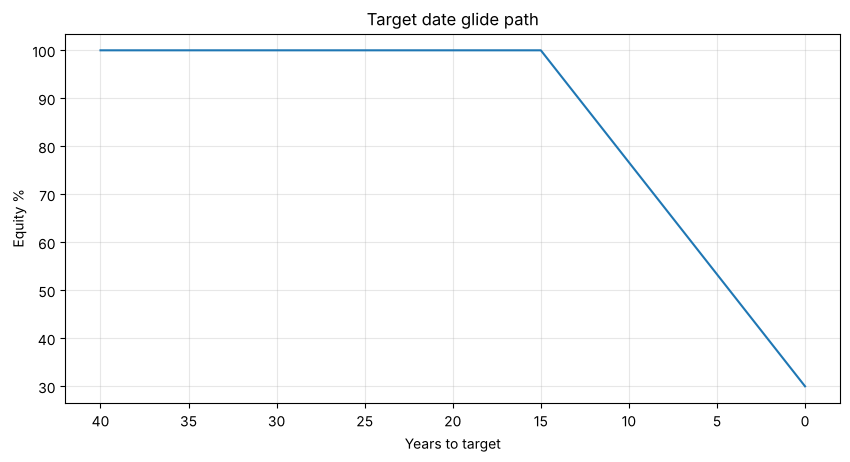


### PE fund cash flows (J-curve: negative early, positive late)


,value
IRR,0.1448
TVPI,1.8000
DPI,1.6500
RVPI,0.1500
paid_in,100.0000


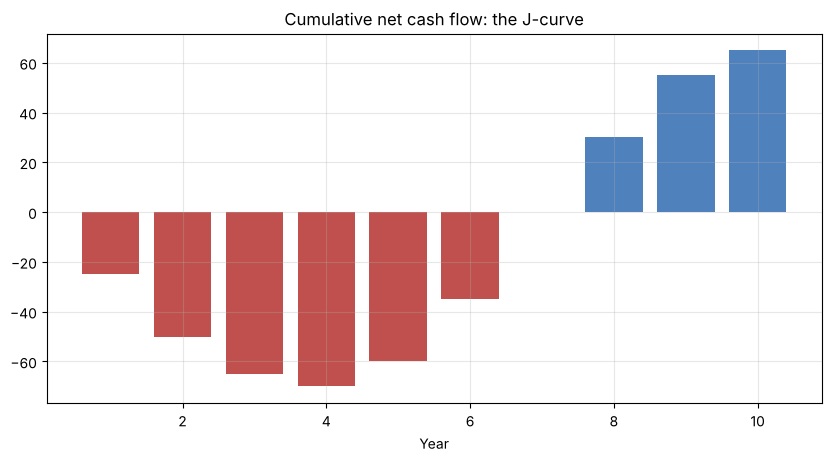


### Performance ratios on 20y of simulated daily returns


,hedge fund,equity index
ann_return,0.0078,0.0979
ann_vol,0.0739,0.1563
sharpe,-0.1958,0.5155
sortino,-0.2801,0.7808
max_drawdown,-0.3299,-0.4926
calmar,0.0237,0.1987


In [12]:
def ddm_gordon(d0, g, r):
    return d0 * (1 + g) / (r - g)

def ddm_two_stage(d0, g1, n1, g2, r):
    pv, d = 0.0, d0
    for t in range(1, n1 + 1):
        d *= 1 + g1; pv += d / (1 + r) ** t
    return pv + ddm_gordon(d, g2, r) / (1 + r) ** n1

@demo("ddm_gordon")
def demo_ddm():
    show({"Gordon (D0=6, g=3%, r=8%)": ddm_gordon(6, 0.03, 0.08),
          "Same with r=9%": ddm_gordon(6, 0.03, 0.09),
          "Two-stage (10% for 5y then 3%)": ddm_two_stage(6, 0.10, 5, 0.03, 0.08)},
         "Dividend discount model (sensitivity to r is the whole story)")

def capm(rf, beta, market_return):
    return rf + beta * (market_return - rf)

def estimate_beta(asset_ret, mkt_ret):
    cov = np.cov(asset_ret, mkt_ret)
    beta = cov[0, 1] / cov[1, 1]
    alpha = (np.mean(asset_ret) - beta * np.mean(mkt_ret)) * 252
    r2 = np.corrcoef(asset_ret, mkt_ret)[0, 1] ** 2
    return beta, alpha, r2

@demo("capm")
def demo_capm():
    rng = np.random.default_rng(SEED)
    mkt = rng.normal(0.07 / 252, 0.18 / math.sqrt(252), 756)
    small = 1.3 * mkt + rng.normal(0, 0.20 / math.sqrt(252), 756)
    b, a, r2 = estimate_beta(small, mkt)
    show({"estimated beta (true 1.3)": b, "annualized alpha": a, "R^2": r2,
          "CAPM required return (rf 2.5%, Rm 8%)": capm(0.025, b, 0.08)}, "Beta regression on 3y of daily data")

def nav_discount(price, nav):
    return price / nav - 1

@demo("nav_discount")
def demo_nav():
    df = pd.DataFrame({"price": [298, 185, 92, 41.5], "nav_per_share": [310, 240, 118, 39.0]},
                      index=["Investment company", "Listed real estate (EPRA NTA)", "Closed-end fund", "Premium example"])
    df["premium_discount"] = nav_discount(df["price"], df["nav_per_share"])
    show(df, "Price vs NAV")

def rights_issue_terp(p_cum, sub_price, new_per_old):
    terp = (p_cum + new_per_old * sub_price) / (1 + new_per_old)
    return {"TERP": terp, "theoretical_right_value": (terp - sub_price) * new_per_old,
            "discount_to_TERP": sub_price / terp - 1, "ownership_dilution_if_you_do_nothing": new_per_old / (1 + new_per_old)}

@demo("rights_issue_terp")
def demo_rights():
    show(rights_issue_terp(p_cum=80, sub_price=50, new_per_old=1 / 2), "1:2 rights issue at 50, share at 80")

def fund_fee_drag(initial, gross_return, fee, years):
    gross = initial * (1 + gross_return) ** years
    net = initial * (1 + gross_return - fee) ** years
    return {"gross_end_value": gross, "net_end_value": net, "fees_cost_total": gross - net, "share_lost": 1 - net / gross}

@demo("fund_fee_drag")
def demo_fee():
    rows = []
    for lbl, fee in [("Index fund 0.10%", 0.001), ("Active fund 1.4%", 0.014), ("Fund of funds 2.0%", 0.02),
                     ("Unit-linked 1.4% + 0.6% wrapper", 0.02)]:
        r = fund_fee_drag(500_000, 0.07, fee, 30); r["product"] = lbl; rows.append(r)
    show(pd.DataFrame(rows).set_index("product"), "Fee drag on SEK 500k over 30y at 7% gross")

def tracking_error(port_ret, bench_ret):
    diff = np.asarray(port_ret) - np.asarray(bench_ret)
    te = diff.std(ddof=1) * math.sqrt(252)
    return {"tracking_error": te, "tracking_difference_ann": diff.mean() * 252, "information_ratio": diff.mean() * 252 / te}

@demo("tracking_error")
def demo_te():
    rng = np.random.default_rng(SEED)
    idx = rng.normal(0.0003, 0.011, 756)
    etf = idx - 0.0012 / 252 + rng.normal(0, 0.0004, 756)
    synth = idx - 0.0005 / 252 + rng.normal(0, 0.0001, 756)
    show(pd.DataFrame({"physical ETF": tracking_error(etf, idx), "synthetic ETF": tracking_error(synth, idx)}),
         "Tracking error and difference")

@demo("leveraged_etf_decay")
def demo_lev():
    rng = np.random.default_rng(SEED)
    sig, T = 0.25, 1.0
    days = 252
    rets = rng.normal(0, sig / math.sqrt(days), (20_000, days))
    idx = np.prod(1 + rets, axis=1) - 1
    rows = []
    for L in [2, 3, -1, -3]:
        lev = np.prod(1 + L * rets, axis=1) - 1
        rows.append({"leverage": L, "median idx return": np.median(idx), "median product return": np.median(lev),
                     "naive L x idx (median)": L * np.median(idx), "P(product < 0)": (lev < 0).mean(),
                     "decay factor approx exp((L-L^2)s^2T/2)": math.exp((L - L * L) * sig ** 2 * T / 2)})
    show(pd.DataFrame(rows), "Daily reset products over 1 year, flat market, 25% vol: the slow bleed")
    path = 100 * np.cumprod(1 + np.tile([0.05, -0.0476], 50))
    lev3 = 100 * np.cumprod(1 + 3 * np.tile([0.05, -0.0476], 50))
    plt.plot(path, label="index (zig-zag, ends flat)"); plt.plot(lev3, label="3x daily")
    plt.title("Volatility decay: index goes nowhere, 3x goes somewhere you won't like"); plt.legend(); plt.show()

def glide_path(years_to_target, start_equity=1.0, end_equity=0.3, ramp_years=15):
    frac = np.clip(years_to_target / ramp_years, 0, 1)
    return end_equity + (start_equity - end_equity) * frac

@demo("glide_path")
def demo_glide():
    y = np.arange(40, -1, -1)
    plt.plot(y, glide_path(y) * 100); plt.gca().invert_xaxis()
    plt.xlabel("Years to target"); plt.ylabel("Equity %"); plt.title("Target date glide path"); plt.show()

def pe_fund_metrics(calls, dists, nav_end):
    calls, dists = np.asarray(calls, float), np.asarray(dists, float)
    net = dists - calls
    net[-1] += nav_end
    paid = calls.sum()
    return {"IRR": irr(net), "TVPI": (dists.sum() + nav_end) / paid, "DPI": dists.sum() / paid,
            "RVPI": nav_end / paid, "paid_in": paid}

@demo("pe_fund_irr")
def demo_pe():
    calls = [25, 25, 20, 15, 10, 5, 0, 0, 0, 0]
    dists = [0, 0, 5, 10, 20, 30, 35, 30, 25, 10]
    r = pe_fund_metrics(calls, dists, nav_end=15)
    show(r, "PE fund cash flows (J-curve: negative early, positive late)")
    cum = np.cumsum(np.array(dists) - np.array(calls))
    plt.bar(range(1, 11), cum, color=["#c0504d" if c < 0 else "#4f81bd" for c in cum])
    plt.title("Cumulative net cash flow: the J-curve"); plt.xlabel("Year"); plt.show()

def sharpe_sortino(returns, rf=0.0, periods=252):
    r = np.asarray(returns)
    ex = r - rf / periods
    downside = ex[ex < 0].std(ddof=1) * math.sqrt(periods)
    wealth = np.cumprod(1 + r)
    mdd = (wealth / np.maximum.accumulate(wealth) - 1).min()
    ann = wealth[-1] ** (periods / len(r)) - 1
    return {"ann_return": ann, "ann_vol": r.std(ddof=1) * math.sqrt(periods),
            "sharpe": ex.mean() * periods / (r.std(ddof=1) * math.sqrt(periods)),
            "sortino": ex.mean() * periods / downside, "max_drawdown": mdd, "calmar": ann / abs(mdd)}

@demo("sharpe_sortino")
def demo_sharpe():
    rng = np.random.default_rng(SEED)
    n = 252 * 20  # 20 years, because 5 years of noise lets any strategy look like genius or garbage
    hf = rng.normal(0.06 / 252, 0.07 / math.sqrt(252), n)
    hf[rng.choice(n, 20, replace=False)] -= 0.025  # the "uncorrelated" strategy finds out about correlation
    eq = rng.standard_t(4, n) * 0.16 / math.sqrt(252) / math.sqrt(2) + 0.08 / 252
    show(pd.DataFrame({"hedge fund": sharpe_sortino(hf, 0.025), "equity index": sharpe_sortino(eq, 0.025)}),
         "Performance ratios on 20y of simulated daily returns")

for k in ["ddm_gordon", "capm", "nav_discount", "rights_issue_terp", "fund_fee_drag", "tracking_error",
          "leveraged_etf_decay", "glide_path", "pe_fund_irr", "sharpe_sortino"]:
    DEMOS[k]()

## 10. Forwards and futures

| Concept | Formula |
|---|---|
| Cost of carry | $F = S\,e^{(r-q)T}$; value of long forward $=(F-K)e^{-rT}$ |
| FX forward (CIP) | $F = S\frac{1+r_dT}{1+r_fT}$, points $=F-S$ |
| Commodity | $F = S\,e^{(r+u-y)T}$ with storage $u$, convenience yield $y$ |
| Roll yield | $\frac{F_{near}-F_{far}}{F_{far}}\cdot\frac{1}{\Delta T}$ (contango = negative) |
| STIR | rate $=100-P$; futures rate $\approx$ forward $+\tfrac12\sigma^2t_1t_2$ |
| Bond future | invoice $=F\cdot CF + AI$; CTD = max implied repo |
| Power future | payoff $=(\bar S_{delivery}-F)\cdot MW\cdot hours$; EPAD $=(\bar S_{area}-\bar S_{sys}-EPAD)\cdot MW\cdot h$ |


### Cost of carry


,value
"OMXS30 fair future (S=2600, r=2.2%, q=3.2%, T=0.5)","2,587.0324"
Value of long forward struck at 2550,36.6273
"BTC fair future (S=100k, r=4%, T=0.25, no carry)","101,005.0167"


Real BTC basis often runs 5-15% p.a.: that's leveraged longs paying up, not a free lunch you found first.

### USD/SEK 6m forward (SEK domestic, USD foreign)


,value
spot,10.4500
forward,10.3475
forward_points,"-1,024.5098"
annualized_carry,-0.0196


Hedging USD assets back to SEK earns/costs approx -1.92% per year (rate differential).

### Commodity forward curves


,months,"contango (u=5%, y=0)",backwardation (y=15%),gold (lease ~0.5%)
0,1.0000,75.5646,74.4396,"2,607.5944"
1,3.0000,76.7066,73.3313,"2,622.8498"
2,6.0000,78.4521,71.6998,"2,645.9005"
3,12.0000,82.0631,68.5448,"2,692.6112"
4,24.0000,89.7913,62.6453,"2,788.5213"


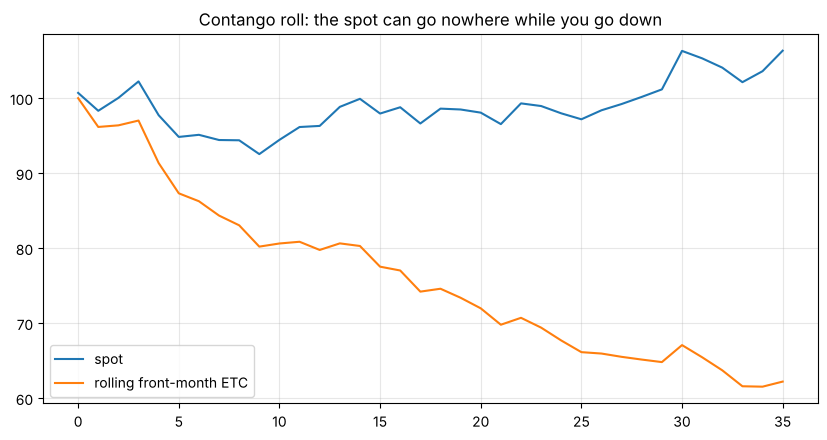


### Roll yield drag


,value
spot change,0.0559
ETC change,-0.3779
annual roll yield,-0.1659



### 3m STIR future 2y out


,value
futures_implied_rate,0.0215
convexity_adjustment,0.0003
forward_rate,0.0212



### 10y bond future: cheapest-to-deliver = highest implied repo


,conversion_factor,gross_basis,net_basis,implied_repo,CTD
bond,,,,,
2.0% 2035,0.7279,0.0453,0.5062,0.0184,False
1.5% 2036,0.6688,0.1540,0.5754,0.0091,False
3.0% 2034,0.8137,0.0917,0.6119,0.0235,True



### Nordic power: system future + SE2 EPAD for a month


,value
system avg EUR/MWh,47.1212
SE2 avg EUR/MWh,38.6863
"long system future P&L (10 MW, F=52)","-36,298.2765"
long SE2 EPAD P&L (EPAD=-6),"-18,115.3183"
fully hedged SE2 price = F_sys + EPAD,46.0000


In [13]:
def forward_price(S, r, T, q=0.0):
    return S * math.exp((r - q) * T)

def forward_value(S, K, r, T, q=0.0):
    return (forward_price(S, r, T, q) - K) * math.exp(-r * T)

@demo("forward_price")
def demo_fwd():
    show({"OMXS30 fair future (S=2600, r=2.2%, q=3.2%, T=0.5)": forward_price(2600, 0.022, 0.5, 0.032),
          "Value of long forward struck at 2550": forward_value(2600, 2550, 0.022, 0.5, 0.032),
          "BTC fair future (S=100k, r=4%, T=0.25, no carry)": forward_price(100_000, 0.04, 0.25)}, "Cost of carry")
    print("Real BTC basis often runs 5-15% p.a.: that's leveraged longs paying up, not a free lunch you found first.")

def fx_forward(spot, r_dom, r_for, T):
    F = spot * (1 + r_dom * T) / (1 + r_for * T)
    return {"spot": spot, "forward": F, "forward_points": (F - spot) * 1e4, "annualized_carry": (F / spot - 1) / T}

@demo("fx_forward")
def demo_fx():
    show(fx_forward(spot=10.45, r_dom=0.0200, r_for=0.0400, T=0.5), "USD/SEK 6m forward (SEK domestic, USD foreign)")
    hedge_cost = fx_forward(10.45, 0.02, 0.04, 1)["annualized_carry"]
    print(f"Hedging USD assets back to SEK earns/costs approx {hedge_cost:.2%} per year (rate differential).")

def commodity_forward(S, r, T, storage=0.0, convenience=0.0):
    return S * math.exp((r + storage - convenience) * T)

@demo("commodity_forward")
def demo_commo():
    T = np.array([1, 3, 6, 12, 24]) / 12
    df = pd.DataFrame({"months": T * 12,
                       "contango (u=5%, y=0)": [commodity_forward(75, 0.04, t, 0.05, 0.0) for t in T],
                       "backwardation (y=15%)": [commodity_forward(75, 0.04, t, 0.02, 0.15) for t in T],
                       "gold (lease ~0.5%)": [commodity_forward(2600, 0.04, t, 0.0, 0.005) for t in T]})
    show(df, "Commodity forward curves")

@demo("futures_roll_yield")
def demo_roll():
    rng = np.random.default_rng(SEED)
    months = 36
    spot = 100 * np.exp(np.cumsum(rng.normal(0, 0.08 / math.sqrt(12), months)))
    contango = 0.015  # 1.5% per month front-to-second spread: typical VIX-ish/nat gas pain
    etc = np.cumprod(np.r_[1, (spot[1:] / spot[:-1]) * (1 - contango)]) * 100
    plt.plot(spot, label="spot"); plt.plot(etc, label="rolling front-month ETC")
    plt.title("Contango roll: the spot can go nowhere while you go down"); plt.legend(); plt.show()
    show({"spot change": spot[-1] / spot[0] - 1, "ETC change": etc[-1] / etc[0] - 1,
          "annual roll yield": (1 - contango) ** 12 - 1}, "Roll yield drag")

def stir_future(price, sigma=0.01, t1=1.0, t2=1.25):
    fut_rate = (100 - price) / 100
    conv_adj = 0.5 * sigma ** 2 * t1 * t2
    return {"futures_implied_rate": fut_rate, "convexity_adjustment": conv_adj, "forward_rate": fut_rate - conv_adj}

@demo("stir_future")
def demo_stir():
    show(stir_future(97.85, sigma=0.012, t1=2, t2=2.25), "3m STIR future 2y out")

def bond_future_ctd(F, basket, repo, days_to_delivery, notional_coupon=0.06):
    rows = []
    for b in basket:
        cf = bond_price(1, b["coupon"], notional_coupon, b["years"])
        full = b["price"] + b["ai"]
        invoice = F * cf + b["ai_delivery"]
        implied_repo = (invoice + b["coupon_income"] - full) / full * 360 / days_to_delivery
        gross = b["price"] - F * cf
        carry = b["coupon_income"] - full * repo * days_to_delivery / 360
        rows.append({"bond": b["name"], "conversion_factor": cf, "gross_basis": gross,
                     "net_basis": gross - carry, "implied_repo": implied_repo})
    df = pd.DataFrame(rows).set_index("bond")
    df["CTD"] = df["implied_repo"] == df["implied_repo"].max()
    return df

@demo("bond_future_ctd")
def demo_ctd():
    days = 82
    basket = [dict(name="2.0% 2035", coupon=0.020, years=9, price=95.55, ai=0.80),
              dict(name="1.5% 2036", coupon=0.015, years=10, price=87.90, ai=0.20),
              dict(name="3.0% 2034", coupon=0.030, years=8, price=106.85, ai=1.90)]
    for b in basket:  # no coupon dates before delivery here, so AI just keeps accruing
        b["ai_delivery"] = b["ai"] + 100 * b["coupon"] * days / 365
        b["coupon_income"] = 0.0
    show(bond_future_ctd(F=131.20, basket=basket, repo=0.021, days_to_delivery=days),
         "10y bond future: cheapest-to-deliver = highest implied repo")

@demo("power_future")
def demo_power():
    rng = np.random.default_rng(SEED)
    hours = 31 * 24
    h = np.arange(hours)
    daily = 10 * np.sin(2 * np.pi * (h % 24 - 7) / 24)              # morning/evening peaks, roughly
    sys_p = np.clip(55 + daily + np.cumsum(rng.normal(0, 1.2, hours)) + rng.gamma(1, 3, hours), -5, None)
    se2 = sys_p - 8 + rng.normal(0, 4, hours)                         # north is hydro-rich, cheaper usually
    F_sys, epad_se2, mw = 52.0, -6.0, 10
    sys_avg, se2_avg = sys_p.mean(), se2.mean()
    show({"system avg EUR/MWh": sys_avg, "SE2 avg EUR/MWh": se2_avg,
          "long system future P&L (10 MW, F=52)": (sys_avg - F_sys) * mw * hours,
          "long SE2 EPAD P&L (EPAD=-6)": ((se2_avg - sys_avg) - epad_se2) * mw * hours,
          "fully hedged SE2 price = F_sys + EPAD": F_sys + epad_se2}, "Nordic power: system future + SE2 EPAD for a month")

for k in ["forward_price", "fx_forward", "commodity_forward", "futures_roll_yield", "stir_future",
          "bond_future_ctd", "power_future"]:
    DEMOS[k]()

## 11. Swaps

| Instrument | Valuation |
|---|---|
| FRA | value $=N(F-K)\tau\,DF(t_2)$; settlement $=\frac{N(L-K)\tau}{1+L\tau}$ |
| IRS | $PV_{fix}=NK\sum\tau_iDF_i$, $PV_{float}=N(DF_0-DF_n)$ (single curve), par rate $=\frac{DF_0-DF_n}{\sum\tau_iDF_i}$ |
| Cross-currency | $V_{SEK} = PV_{SEK\,leg} - S\cdot PV_{USD\,leg}$ including notional exchange |
| ZC inflation swap | $N\left[\frac{I_T}{I_0}-1\right]$ vs $N[(1+K)^T-1]$ |
| TRS | receiver gets $\Delta P + D$, pays $(r_{float}+s)\tau$ on notional |
| Commodity swap | $\sum_i(F_i-K)Q_iDF_i$ |
| Variance swap | $N_{var}(\sigma^2_{realized}-K^2)$, $N_{var}=\frac{N_{vega}}{2K}$; fair $K^2=\frac{2e^{rT}}{T}\sum\frac{\Delta K_i}{K_i^2}O(K_i)$ |

In [14]:
def fra_value(N, K, t1, t2, curve):
    tau = t2 - t1
    F = float(curve.fwd_simple(t1, t2))
    return {"forward_rate": F, "value_to_payer_of_fixed": N * (F - K) * tau * float(curve.df(t2))}

def fra_settlement(N, K, L, tau):
    return N * (L - K) * tau / (1 + L * tau)

@demo("fra_value")
def demo_fra():
    r = fra_value(100e6, 0.0215, 0.5, 0.75, CURVE)
    r["settlement if 3m fixes at 2.40%"] = fra_settlement(100e6, 0.0215, 0.024, 0.25)
    show(r, "6x9 FRA on SEK 100m")

def swap_annuity(tenor, freq, curve, start=0.0):
    t = start + np.arange(1, int(round((tenor) * freq)) + 1) / freq
    return float(np.sum((1 / freq) * curve.df(t))), t

def par_swap_rate(tenor, freq, curve, start=0.0):
    A, t = swap_annuity(tenor, freq, curve, start)
    return (float(curve.df(start)) - float(curve.df(t[-1]))) / A

def irs_value(N, K, tenor, freq, curve, pay_fixed=True, start=0.0):
    A, t = swap_annuity(tenor, freq, curve, start)
    pv_float = N * (float(curve.df(start)) - float(curve.df(t[-1])))
    pv_fixed = N * K * A
    v = pv_float - pv_fixed
    return v if pay_fixed else -v

@demo("irs_value")
def demo_irs():
    N, K = 500e6, 0.0240
    par = par_swap_rate(5, 1, CURVE)
    v = irs_value(N, K, 5, 1, CURVE)
    dv01 = irs_value(N, K, 5, 1, CURVE.shifted(1)) - v
    fwd_par = par_swap_rate(5, 1, CURVE, start=2)
    show({"5y par swap rate": par, "value: pay fixed 2.40% on 500m": v, "DV01 (per +1bp)": dv01,
          "2y-forward 5y swap rate": fwd_par,
          "amortizing 10y (straight-line) par rate": amortizing_par_rate(10, CURVE)},
         "Interest rate swaps (property company hedge style)")

def amortizing_par_rate(years, curve):
    t = np.arange(1, years + 1)
    notional = 1 - (t - 1) / years   # notional outstanding during each year
    df = curve.df(t)
    df_prev = curve.df(t - 1)
    pv_float = np.sum(notional * (df_prev - df))
    return pv_float / np.sum(notional * df)

def ccs_value(N_dom, N_for, spot, k_dom, k_for, tenor, curve_dom, curve_for):
    """Fixed-fixed cross-currency swap from the side receiving domestic, paying foreign. Value in domestic."""
    t = np.arange(1, tenor + 1)
    pv_dom = N_dom * (k_dom * np.sum(curve_dom.df(t)) + float(curve_dom.df(tenor)))
    pv_for = N_for * (k_for * np.sum(curve_for.df(t)) + float(curve_for.df(tenor)))
    return {"PV domestic leg": pv_dom, "PV foreign leg (in dom)": spot * pv_for, "value (dom)": pv_dom - spot * pv_for}

USD_CURVE = DiscountCurve([0, 1, 2, 5, 10], [0.040, 0.039, 0.037, 0.036, 0.038])

@demo("ccs_value")
def demo_ccs():
    show(ccs_value(N_dom=104.5e6, N_for=10e6, spot=10.0, k_dom=0.023, k_for=0.0365, tenor=5,
                   curve_dom=CURVE, curve_for=USD_CURVE), "5y SEK/USD fixed-fixed CCS after USD weakened to 10.00")

@demo("inflation_swap")
def demo_infl():
    N, T, K = 100e6, 10, 0.0200
    breakeven = 0.0215
    fixed_leg = N * ((1 + K) ** T - 1)
    infl_leg = N * ((1 + breakeven) ** T - 1)
    show({"fixed leg (pay K=2.00%)": fixed_leg, "expected inflation leg (BE 2.15%)": infl_leg,
          "PV to inflation receiver": (infl_leg - fixed_leg) * float(CURVE.df(T))}, "10y zero-coupon inflation swap")

@demo("trs_value")
def demo_trs():
    rng = np.random.default_rng(SEED)
    N, q = 50e6, 4
    prices = 100 * np.cumprod(1 + rng.normal(0.02, 0.08, q))
    prices = np.r_[100, prices]
    divs = np.array([0, 1.0, 0, 1.0])
    fl = np.array([0.022, 0.021, 0.020, 0.020]) + 0.005
    rows = []
    for i in range(q):
        ret = (prices[i + 1] - prices[i] + divs[i]) / prices[i]
        rows.append({"quarter": i + 1, "asset_return": ret, "financing_paid": fl[i] / 4,
                     "net_to_receiver": N * (ret - fl[i] / 4)})
    show(pd.DataFrame(rows), "Equity TRS quarterly resets on 50m (leverage without owning anything)")

@demo("commodity_swap")
def demo_cswap():
    months = np.arange(1, 13) / 12
    fwd = 50 + 12 * np.cos(2 * np.pi * (months - 1 / 12))  # winter expensive, summer cheap
    K, vol_mwh = 52.0, 10 * 730
    pv = np.sum((fwd - K) * vol_mwh * CURVE.df(months))
    show({"PV to fixed payer (buy power at 52)": pv, "average forward": fwd.mean()},
         "1y baseload power swap / financial PPA, 10 MW")

# BSM lives here (not in section 12) because the variance swap replication needs it first. Options reuse it.
def bsm_price(S, K, T, r, sigma, q=0.0, kind="call"):
    if T <= 0 or sigma <= 0:
        return max(0.0, (S - K) if kind == "call" else (K - S))
    d1 = (math.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)
    if kind == "call":
        return S * math.exp(-q * T) * norm.cdf(d1) - K * math.exp(-r * T) * norm.cdf(d2)
    return K * math.exp(-r * T) * norm.cdf(-d2) - S * math.exp(-q * T) * norm.cdf(-d1)

def fair_variance_strike(S, T, r, smile, strikes):
    """Replicate variance with OTM options. smile(K) -> implied vol. The log contract in disguise."""
    F = S * math.exp(r * T)
    strikes = np.asarray(strikes)
    dK = np.gradient(strikes)
    otm = np.array([bsm_price(S, K, T, r, smile(K), kind="put" if K < F else "call") for K in strikes])
    return math.sqrt(2 * math.exp(r * T) / T * np.sum(dK / strikes ** 2 * otm))

@demo("variance_swap")
def demo_var():
    smile = lambda K: 0.20 - 0.10 * math.log(K / 100) + 0.10 * math.log(K / 100) ** 2  # equity-style put skew
    Kvar = fair_variance_strike(100, 1.0, 0.02, smile, np.linspace(40, 220, 600))
    rng = np.random.default_rng(SEED)
    realized = (rng.normal(0, 0.28 / math.sqrt(252), 252)).std(ddof=0) * math.sqrt(252)
    n_vega = 100_000
    n_var = n_vega / (2 * Kvar * 100)
    show({"ATM vol": smile(100), "fair variance strike (vol pts)": Kvar * 100,
          "realized vol": realized * 100,
          "variance swap P&L (long, vega notional 100k)": n_var * ((realized * 100) ** 2 - (Kvar * 100) ** 2)},
         "Variance swap: strike sits above ATM because of the skew")

for k in ["fra_value", "irs_value", "ccs_value", "inflation_swap", "trs_value", "commodity_swap", "variance_swap"]:
    DEMOS[k]()


### 6x9 FRA on SEK 100m


,value
forward_rate,0.0199
value_to_payer_of_fixed,"-40,599.3622"
settlement if 3m fixes at 2.40%,"62,127.2366"



### Interest rate swaps (property company hedge style)


,value
5y par swap rate,0.0243
value: pay fixed 2.40% on 500m,"701,098.1997"
DV01 (per +1bp),"232,432.4223"
2y-forward 5y swap rate,0.0282
amortizing 10y (straight-line) par rate,0.0256



### 5y SEK/USD fixed-fixed CCS after USD weakened to 10.00


...

,quarter,asset_return,financing_paid,net_to_receiver
0,1,0.0444,0.0067,"1,881,368.3190"
1,2,-0.0536,0.0065,"-3,006,182.2734"
2,3,0.0800,0.0063,"3,689,304.7832"
3,4,0.1047,0.0063,"4,922,939.3356"



### 1y baseload power swap / financial PPA, 10 MW


,value
PV to fixed payer (buy power at 52),"-172,465.6177"
average forward,50.0000



### Variance swap: strike sits above ATM because of the skew


,value
ATM vol,0.2000
fair variance strike (vol pts),21.0262
realized vol,26.2014
"variance swap P&L (long, vega notional 100k)","581,205.8868"


## 12. Options: closed form and trees

| Model | Use |
|---|---|
| Black-Scholes-Merton | $C = Se^{-qT}N(d_1)-Ke^{-rT}N(d_2)$, $d_{1,2}=\frac{\ln(S/K)+(r-q\pm\sigma^2/2)T}{\sigma\sqrt T}$ |
| Greeks | $\Delta=e^{-qT}N(d_1)$, $\Gamma=\frac{e^{-qT}\phi(d_1)}{S\sigma\sqrt T}$, $\nu=Se^{-qT}\phi(d_1)\sqrt T$ |
| Put-call parity | $C-P = Se^{-qT}-Ke^{-rT}$ |
| Black-76 | options on futures, caps/floors, swaptions: $e^{-rT}[FN(d_1)-KN(d_2)]$ |
| Garman-Kohlhagen | FX: BSM with $q=r_f$ |
| CRR binomial | $u=e^{\sigma\sqrt{\Delta t}}$, $p=\frac{e^{(r-q)\Delta t}-d}{u-d}$, early exercise at each node |
| Digital | cash-or-nothing call $=Qe^{-rT}N(d_2)$ |
| Caplet | $N\tau DF(t_{i+1})[F_iN(d_1)-KN(d_2)]$ with expiry $t_i$ |
| Swaption | $N\cdot A\,[S_0N(d_1)-KN(d_2)]$ |
| Turbo / mini future | $\frac{S - FL}{ratio}$, knocked out at stop-loss |


### BSM S=100 K=105 T=6m vol=25% q=2%


,call,put
price,4.9793,9.8257
delta,0.4236,-0.5665
gamma,0.0220,0.0220
vega_per_vol_pt,0.2747,0.2747
theta_per_day,-0.0187,-0.0179
rho_per_1pct,0.1869,-0.3324


Put-call parity error: -7.11e-15 (if this is not ~0, call a doctor)
Implied vol recovered from call price: 25.0000%

### Black-76


,value
call on Brent future F=75 K=80 T=0.25 vol=35%,3.2335
put on power future F=52 K=45 T=0.5 vol=60%,5.0449



### FX options (Garman-Kohlhagen)


...

,S,digital call (pays 1),digital 1 day left
0,80.0000,0.0128,0.0000
1,85.0000,0.0518,0.0000
2,90.0000,0.1453,0.0000
3,95.0000,0.3025,0.0000
4,100.0000,0.4975,0.5000
5,105.0000,0.6838,0.9999
6,110.0000,0.8256,0.9999
7,115.0000,0.9143,0.9999
8,120.0000,0.9610,0.9999


Range accrual (STIBOR 2.1%, range 1.5% to 3.0%, 25% normalised vol): expected accrual 93.6% of days

### Caps, floors, collars (Black)


,value
5y cap 3.0% on 200m,"2,665,982.4481"
5y floor 1.5% on 200m,"572,743.5706"
"collar cost for borrower (long cap, short floor)","2,093,238.8775"
cap cost in bp running,28.2593



### European swaptions (Black)


,value
forward swap rate 2y5y,0.0282
payer 2.8% (2y into 5y),"1,788,388.6553"
receiver 2.8%,"1,704,412.3500"
parity check: payer - receiver - fwd swap,-0.0000


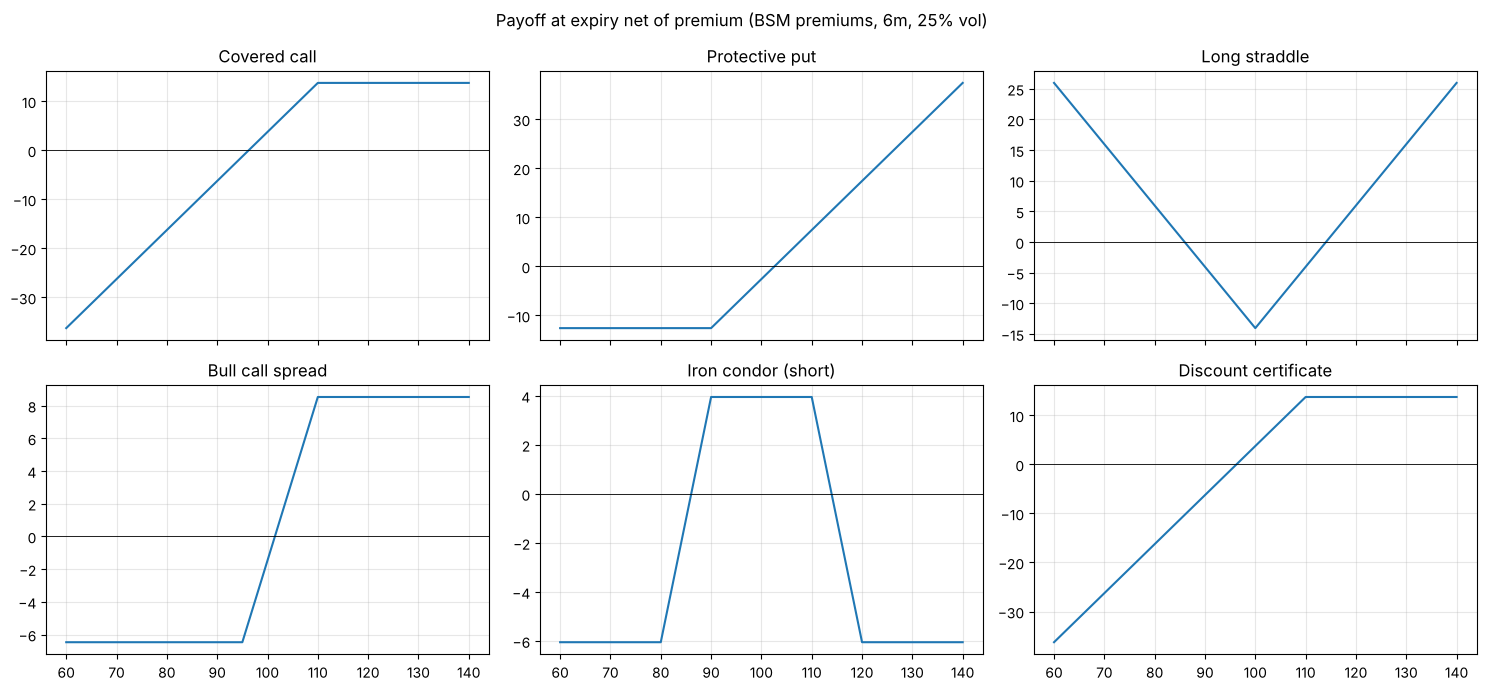


### Mini long OMXS30, financing 2340, stop 2380


,value
value,26.0000
leverage,10.0000
distance_to_stop,0.0924
daily_financing_creep,0.3526


Probability of knock-out within 60 trading days (18% vol): 31.1%


In [15]:
def bsm_greeks(S, K, T, r, sigma, q=0.0, kind="call"):
    d1 = (math.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)
    pdf = norm.pdf(d1)
    gamma = math.exp(-q * T) * pdf / (S * sigma * math.sqrt(T))
    vega = S * math.exp(-q * T) * pdf * math.sqrt(T) / 100      # per 1 vol point
    if kind == "call":
        delta = math.exp(-q * T) * norm.cdf(d1)
        theta = (-S * math.exp(-q * T) * pdf * sigma / (2 * math.sqrt(T)) - r * K * math.exp(-r * T) * norm.cdf(d2)
                 + q * S * math.exp(-q * T) * norm.cdf(d1)) / 365
        rho = K * T * math.exp(-r * T) * norm.cdf(d2) / 100
    else:
        delta = -math.exp(-q * T) * norm.cdf(-d1)
        theta = (-S * math.exp(-q * T) * pdf * sigma / (2 * math.sqrt(T)) + r * K * math.exp(-r * T) * norm.cdf(-d2)
                 - q * S * math.exp(-q * T) * norm.cdf(-d1)) / 365
        rho = -K * T * math.exp(-r * T) * norm.cdf(-d2) / 100
    return {"price": bsm_price(S, K, T, r, sigma, q, kind), "delta": delta, "gamma": gamma,
            "vega_per_vol_pt": vega, "theta_per_day": theta, "rho_per_1pct": rho}

def implied_vol(price, S, K, T, r, q=0.0, kind="call"):
    return optimize.brentq(lambda s: bsm_price(S, K, T, r, s, q, kind) - price, 1e-4, 5.0)

@demo("bsm_price")
def demo_bsm():
    S, K, T, r, s, q = 100, 105, 0.5, 0.022, 0.25, 0.02
    c, p = bsm_greeks(S, K, T, r, s, q, "call"), bsm_greeks(S, K, T, r, s, q, "put")
    show(pd.DataFrame({"call": c, "put": p}), "BSM S=100 K=105 T=6m vol=25% q=2%")
    parity = c["price"] - p["price"] - (S * math.exp(-q * T) - K * math.exp(-r * T))
    print(f"Put-call parity error: {parity:.2e} (if this is not ~0, call a doctor)")
    print(f"Implied vol recovered from call price: {implied_vol(c['price'], S, K, T, r, q):.4%}")

def black76(F, K, T, r, sigma, kind="call"):
    d1 = (math.log(F / K) + 0.5 * sigma ** 2 * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)
    if kind == "call":
        return math.exp(-r * T) * (F * norm.cdf(d1) - K * norm.cdf(d2))
    return math.exp(-r * T) * (K * norm.cdf(-d2) - F * norm.cdf(-d1))

@demo("black76")
def demo_b76():
    show({"call on Brent future F=75 K=80 T=0.25 vol=35%": black76(75, 80, 0.25, 0.04, 0.35),
          "put on power future F=52 K=45 T=0.5 vol=60%": black76(52, 45, 0.5, 0.025, 0.60, "put")}, "Black-76")

def garman_kohlhagen(S, K, T, rd, rf, sigma, kind="call"):
    return bsm_price(S, K, T, rd, sigma, q=rf, kind=kind)

@demo("garman_kohlhagen")
def demo_gk():
    show({"EUR/SEK 3m call K=11.30 (S=11.15)": garman_kohlhagen(11.15, 11.30, 0.25, 0.020, 0.0225, 0.07),
          "USD/SEK 1y put K=10.00 (S=10.45)": garman_kohlhagen(10.45, 10.00, 1.0, 0.020, 0.040, 0.10, "put")},
         "FX options (Garman-Kohlhagen)")

def binomial_american(S, K, T, r, sigma, q=0.0, steps=500, kind="put", american=True):
    dt = T / steps
    u = math.exp(sigma * math.sqrt(dt)); d = 1 / u
    p = (math.exp((r - q) * dt) - d) / (u - d)
    disc = math.exp(-r * dt)
    ST = S * u ** np.arange(steps, -1, -1) * d ** np.arange(0, steps + 1)
    V = np.maximum(ST - K, 0) if kind == "call" else np.maximum(K - ST, 0)
    for i in range(steps - 1, -1, -1):
        ST = ST[:-1] / u
        V = disc * (p * V[:-1] + (1 - p) * V[1:])
        if american:
            V = np.maximum(V, (ST - K) if kind == "call" else (K - ST))
    return float(V[0])

@demo("binomial_american")
def demo_binom():
    args = dict(S=100, K=110, T=1.0, r=0.04, sigma=0.25)
    show({"European put (BSM)": bsm_price(kind="put", **args),
          "European put (CRR 500 steps)": binomial_american(**args, american=False),
          "American put (CRR)": binomial_american(**args),
          "early exercise premium": binomial_american(**args) - bsm_price(kind="put", **args)}, "American vs European")

def digital_option(S, K, T, r, sigma, q=0.0, payout=1.0, kind="call", style="cash"):
    d1 = (math.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)
    sgn = 1 if kind == "call" else -1
    if style == "cash":
        return payout * math.exp(-r * T) * norm.cdf(sgn * d2)
    return S * math.exp(-q * T) * norm.cdf(sgn * d1)

@demo("digital_option")
def demo_digital():
    Ss = np.linspace(80, 120, 9)
    df = pd.DataFrame({"S": Ss, "digital call (pays 1)": [digital_option(s, 100, 0.25, 0.02, 0.2) for s in Ss],
                       "digital 1 day left": [digital_option(s, 100, 1 / 365, 0.02, 0.2) for s in Ss]})
    show(df, "Cash-or-nothing digital: near expiry it is a cliff (pin risk)")
    # Range accrual coupon: each day pays if rate in range. Expected accrual fraction:
    days = 252
    fr = np.mean([digital_option(2.1, 1.5, t, 0.0, 0.25) - digital_option(2.1, 3.0, t, 0.0, 0.25)
                  for t in np.arange(1, days + 1) / days])
    print(f"Range accrual (STIBOR 2.1%, range 1.5% to 3.0%, 25% normalised vol): expected accrual {fr:.1%} of days")

def cap_floor_black(N, K, maturity, freq, curve, sigma, kind="cap"):
    t = np.arange(1, int(maturity * freq) + 1) / freq
    total, rows = 0.0, []
    for t1, t2 in zip(t[:-1], t[1:]):  # first period is already fixed, so caplets start at t[0]
        F = float(curve.fwd_simple(t1, t2)); tau = t2 - t1
        d1 = (math.log(F / K) + 0.5 * sigma ** 2 * t1) / (sigma * math.sqrt(t1)); d2 = d1 - sigma * math.sqrt(t1)
        if kind == "cap":
            v = N * tau * float(curve.df(t2)) * (F * norm.cdf(d1) - K * norm.cdf(d2))
        else:
            v = N * tau * float(curve.df(t2)) * (K * norm.cdf(-d2) - F * norm.cdf(-d1))
        total += v
        rows.append({"expiry": t1, "fwd": F, "value": v})
    return total, pd.DataFrame(rows)

@demo("cap_floor_black")
def demo_cap():
    cap, _ = cap_floor_black(200e6, 0.030, 5, 4, CURVE, 0.30, "cap")
    flo, _ = cap_floor_black(200e6, 0.015, 5, 4, CURVE, 0.30, "floor")
    show({"5y cap 3.0% on 200m": cap, "5y floor 1.5% on 200m": flo,
          "collar cost for borrower (long cap, short floor)": cap - flo,
          "cap cost in bp running": cap / 200e6 / swap_annuity(5, 4, CURVE)[0] * 1e4}, "Caps, floors, collars (Black)")

def swaption_black(N, K, expiry, tenor, freq, curve, sigma, payer=True):
    A, t = swap_annuity(tenor, freq, curve, start=expiry)
    S0 = par_swap_rate(tenor, freq, curve, start=expiry)
    d1 = (math.log(S0 / K) + 0.5 * sigma ** 2 * expiry) / (sigma * math.sqrt(expiry)); d2 = d1 - sigma * math.sqrt(expiry)
    if payer:
        return N * A * (S0 * norm.cdf(d1) - K * norm.cdf(d2)), S0
    return N * A * (K * norm.cdf(-d2) - S0 * norm.cdf(-d1)), S0

@demo("swaption_black")
def demo_swaption():
    pay, S0 = swaption_black(100e6, 0.028, 2, 5, 1, CURVE, 0.25, True)
    rec, _ = swaption_black(100e6, 0.028, 2, 5, 1, CURVE, 0.25, False)
    show({"forward swap rate 2y5y": S0, "payer 2.8% (2y into 5y)": pay, "receiver 2.8%": rec,
          "parity check: payer - receiver - fwd swap": pay - rec - irs_value(100e6, 0.028, 5, 1, CURVE, start=2)},
         "European swaptions (Black)")

@demo("option_strategies")
def demo_strats():
    S = np.linspace(60, 140, 401)
    c = lambda K: np.maximum(S - K, 0); p = lambda K: np.maximum(K - S, 0)
    prem = lambda K, kind: bsm_price(100, K, 0.5, 0.02, 0.25, kind=kind)
    strategies = {
        "Covered call": (S - 100) - c(110) + prem(110, "call"),
        "Protective put": (S - 100) + p(90) - prem(90, "put"),
        "Long straddle": c(100) + p(100) - prem(100, "call") - prem(100, "put"),
        "Bull call spread": c(95) - c(110) - prem(95, "call") + prem(110, "call"),
        "Iron condor (short)": (-p(90) + p(80) - c(110) + c(120) + prem(90, "put") - prem(80, "put")
                                + prem(110, "call") - prem(120, "call")),
        "Discount certificate": np.minimum(S, 110) - (100 - prem(110, "call")),
    }
    fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
    for ax, (nm, pl) in zip(axes.ravel(), strategies.items()):
        ax.plot(S, pl); ax.axhline(0, color="k", lw=0.6); ax.set_title(nm)
    plt.suptitle("Payoff at expiry net of premium (BSM premiums, 6m, 25% vol)"); plt.tight_layout(); plt.show()

def turbo_mini_future(S, financing_level, stop_loss, ratio=10, r=0.025, spread_fin=0.03):
    value = max(S - financing_level, 0) / ratio
    return {"value": value, "leverage": S / (S - financing_level), "distance_to_stop": S / stop_loss - 1,
            "daily_financing_creep": financing_level * (r + spread_fin) / 365}

@demo("turbo_mini_future")
def demo_turbo():
    rng = np.random.default_rng(SEED)
    S0, FL, SL = 2600, 2340, 2380
    show(turbo_mini_future(S0, FL, SL), "Mini long OMXS30, financing 2340, stop 2380")
    days, n = 60, 20_000
    paths = S0 * np.exp(np.cumsum(rng.normal(0, 0.18 / math.sqrt(252), (n, days)), axis=1))
    fl_path = FL * (1 + 0.055 / 365) ** np.arange(1, days + 1)
    sl_path = SL * (1 + 0.055 / 365) ** np.arange(1, days + 1)
    ko = (paths <= sl_path).any(axis=1)
    print(f"Probability of knock-out within {days} trading days (18% vol): {ko.mean():.1%}")

for k in ["bsm_price", "black76", "garman_kohlhagen", "binomial_american", "digital_option", "cap_floor_black",
          "swaption_black", "option_strategies", "turbo_mini_future"]:
    DEMOS[k]()

## 13. Exotic options via Monte Carlo

Paths: $S_{t+\Delta t}=S_t\exp\!\left((r-q-\tfrac12\sigma^2)\Delta t+\sigma\sqrt{\Delta t}\,Z\right)$, antithetic variates on.

| Exotic | Check / variance reduction |
|---|---|
| Barrier (down-and-in / out) | in + out = vanilla; closed form Reiner-Rubinstein for down-and-in call ($H\le K$) |
| Arithmetic Asian | geometric Asian closed form as control variate |
| Lookback | floating strike call $S_T-\min S$ |
| Spread | Kirk's approximation |
| Basket / worst-of | Cholesky-correlated paths |

In [16]:
def gbm_paths(S0, r, q, sigma, T, steps, n_paths, seed=SEED, antithetic=True):
    rng = np.random.default_rng(seed)
    dt = T / steps
    half = n_paths // 2 if antithetic else n_paths
    Z = rng.standard_normal((half, steps))
    if antithetic:
        Z = np.vstack([Z, -Z])
    inc = (r - q - 0.5 * sigma ** 2) * dt + sigma * math.sqrt(dt) * Z
    return S0 * np.exp(np.cumsum(inc, axis=1))

def mc_stats(payoffs, r, T):
    disc = math.exp(-r * T) * payoffs
    return disc.mean(), disc.std(ddof=1) / math.sqrt(len(disc))

def down_in_call_closed(S, K, H, T, r, sigma, q=0.0):
    lam = (r - q + 0.5 * sigma ** 2) / sigma ** 2
    y = math.log(H ** 2 / (S * K)) / (sigma * math.sqrt(T)) + lam * sigma * math.sqrt(T)
    return (S * math.exp(-q * T) * (H / S) ** (2 * lam) * norm.cdf(y)
            - K * math.exp(-r * T) * (H / S) ** (2 * lam - 2) * norm.cdf(y - sigma * math.sqrt(T)))

@demo("barrier_mc")
def demo_barrier():
    S0, K, H, T, r, s = 100, 100, 85, 1.0, 0.02, 0.25
    steps = 252
    P = gbm_paths(S0, r, 0, s, T, steps, 100_000)
    # Broadie-Glasserman-Kou in reverse: discrete paths miss intra-step crossings, so we move the barrier
    # TOWARDS the spot to approximate the continuous closed form. (Shift it the other way and you get 30% wrong.)
    H_adj = H * math.exp(0.5826 * s * math.sqrt(T / steps))
    hit = (P.min(axis=1) <= H_adj)
    vanilla = np.maximum(P[:, -1] - K, 0)
    di, di_se = mc_stats(vanilla * hit, r, T)
    do, do_se = mc_stats(vanilla * ~hit, r, T)
    show({"down-and-in call MC": di, "+/- 1 s.e.": di_se, "closed form (continuous)": down_in_call_closed(S0, K, H, T, r, s),
          "down-and-out call MC": do, "in + out": di + do, "vanilla BSM": bsm_price(S0, K, T, r, s),
          "P(barrier hit)": hit.mean()}, "Barrier options, H=85")

def geometric_asian_call(S, K, T, r, sigma, n, q=0.0):
    sig_g = sigma * math.sqrt((n + 1) * (2 * n + 1) / (6 * n ** 2))
    nu = (r - q - 0.5 * sigma ** 2) * (n + 1) / (2 * n)
    d1 = (math.log(S / K) + (nu + sig_g ** 2) * T) / (sig_g * math.sqrt(T))
    d2 = d1 - sig_g * math.sqrt(T)
    return math.exp(-r * T) * (S * math.exp((nu + 0.5 * sig_g ** 2) * T) * norm.cdf(d1) - K * norm.cdf(d2))

@demo("asian_mc")
def demo_asian():
    S0, K, T, r, s, n = 100, 100, 1.0, 0.02, 0.30, 12
    P = gbm_paths(S0, r, 0, s, T, n, 100_000)
    arith = np.maximum(P.mean(axis=1) - K, 0) * math.exp(-r * T)
    geo = np.maximum(np.exp(np.log(P).mean(axis=1)) - K, 0) * math.exp(-r * T)
    geo_exact = geometric_asian_call(S0, K, T, r, s, n)
    b = np.cov(arith, geo)[0, 1] / geo.var()
    cv = arith - b * (geo - geo_exact)
    show({"arithmetic Asian (plain MC)": arith.mean(), "plain s.e.": arith.std() / math.sqrt(len(arith)),
          "arithmetic Asian (control variate)": cv.mean(), "CV s.e.": cv.std() / math.sqrt(len(cv)),
          "geometric closed form": geo_exact, "vanilla BSM (for scale)": bsm_price(S0, K, T, r, s)},
         "Asian call, monthly averaging: variance reduction is not optional")

@demo("lookback_mc")
def demo_lookback():
    P = gbm_paths(100, 0.02, 0, 0.25, 1.0, 252, 60_000)
    full = np.hstack([np.full((P.shape[0], 1), 100.0), P])
    v, se = mc_stats(full[:, -1] - full.min(axis=1), 0.02, 1.0)
    show({"floating-strike lookback call": v, "s.e.": se, "ATM vanilla call": bsm_price(100, 100, 1, 0.02, 0.25)},
         "Lookback: buy at the low, in hindsight, for a price")

def correlated_paths(S0s, vols, corr, r, T, steps, n_paths, seed=SEED):
    rng = np.random.default_rng(seed)
    L = np.linalg.cholesky(np.asarray(corr))
    k = len(S0s); dt = T / steps
    Z = rng.standard_normal((n_paths, steps, k)) @ L.T
    vols = np.asarray(vols)
    inc = (r - 0.5 * vols ** 2) * dt + vols * math.sqrt(dt) * Z
    return np.asarray(S0s) * np.exp(np.cumsum(inc, axis=1))

def kirk_spread(F1, F2, K, T, r, s1, s2, rho):
    w = F2 / (F2 + K)
    s = math.sqrt(s1 ** 2 - 2 * rho * s1 * s2 * w + (s2 * w) ** 2)
    d1 = (math.log(F1 / (F2 + K)) + 0.5 * s ** 2 * T) / (s * math.sqrt(T)); d2 = d1 - s * math.sqrt(T)
    return math.exp(-r * T) * (F1 * norm.cdf(d1) - (F2 + K) * norm.cdf(d2))

@demo("spread_option_mc")
def demo_spread():
    F1, F2, K, T, r, s1, s2, rho = 80, 70, 5, 0.5, 0.03, 0.40, 0.35, 0.8
    P = correlated_paths([F1, F2], [s1, s2], [[1, rho], [rho, 1]], 0.0, T, 1, 200_000)[:, -1, :]
    v = math.exp(-r * T) * np.maximum(P[:, 0] - P[:, 1] - K, 0).mean()
    show({"MC spread option": v, "Kirk approximation": kirk_spread(F1, F2, K, T, r, s1, s2, rho)},
         "Spark/crack spread call on futures")

@demo("basket_mc")
def demo_basket():
    corr = [[1, 0.6, 0.5], [0.6, 1, 0.55], [0.5, 0.55, 1]]
    P = correlated_paths([100, 100, 100], [0.25, 0.30, 0.20], corr, 0.02, 1.0, 1, 200_000)[:, -1, :]
    perf = P / 100
    d = math.exp(-0.02)
    show({"average basket call ATM": d * np.maximum(perf.mean(axis=1) - 1, 0).mean() * 100,
          "best-of call ATM": d * np.maximum(perf.max(axis=1) - 1, 0).mean() * 100,
          "worst-of put ATM": d * np.maximum(1 - perf.min(axis=1), 0).mean() * 100,
          "single-name put ATM (vol 25%)": bsm_price(100, 100, 1, 0.02, 0.25, kind="put")},
         "Basket / rainbow: worst-of puts are why autocalls pay fat coupons")

for k in ["barrier_mc", "asian_mc", "lookback_mc", "spread_option_mc", "basket_mc"]:
    DEMOS[k]()


### Barrier options, H=85


,value
down-and-in call MC,1.1662
+/- 1 s.e.,0.0162
closed form (continuous),1.1942
down-and-out call MC,9.6825
in + out,10.8487
vanilla BSM,10.8706
P(barrier hit),0.5298



### Asian call, monthly averaging: variance reduction is not optional


,value
arithmetic Asian (plain MC),7.7509
plain s.e.,0.0393
arithmetic Asian (control variate),7.7765
CV s.e.,0.0016
geometric closed form,7.3645
vanilla BSM (for scale),12.8216



### Lookback: buy at the low, in hindsight, for a price


,value
floating-strike lookback call,18.5531
s.e.,0.0732
ATM vanilla call,10.8706



### Spark/crack spread call on futures


,value
MC spread option,7.9810
Kirk approximation,7.9951



### Basket / rainbow: worst-of puts are why autocalls pay fat coupons


,value
average basket call ATM,9.3322
best-of call ATM,20.1291
worst-of put ATM,15.6296
single-name put ATM (vol 25%),8.8904


## 14. Structured products

Every retail structured product is a bond plus a bag of options, minus a fee you cannot see.

| Product | Decomposition |
|---|---|
| Capital-protected note | zero-coupon bond (issuer curve) + participation $\times$ ATM call; participation $=\frac{N-ZCB-fee}{Call}$ |
| Reverse convertible | bond + short put; fair coupon solves note value = par |
| Autocallable | bond + digital calls on observation dates + short down-and-in put; Monte Carlo |

In [17]:
def capital_protected_note(N=100, T=5, r=0.024, issuer_spread=0.008, sigma=0.18, q=0.03, fee_total=0.03):
    zcb = N * math.exp(-(r + issuer_spread) * T)
    budget = N - zcb - N * fee_total
    call = bsm_price(N, N, T, r, sigma, q)
    return {"zero_coupon_cost": zcb, "fee (upfront eq.)": N * fee_total, "option_budget": budget,
            "ATM call cost": call, "participation_rate": budget / call,
            "participation if rates were 0.5%": (N - N * math.exp(-0.013 * T) - N * fee_total) / bsm_price(N, N, T, 0.005, sigma, q)}

@demo("capital_protected_note")
def demo_cpn():
    show(capital_protected_note(), "5y capital-protected note on an index (why these vanished when rates hit zero)")

def reverse_convertible(N=100, T=1, r=0.024, credit=0.01, sigma=0.32, q=0.02, fee=0.015, barrier=None):
    if barrier is None:
        put = bsm_price(N, N, T, r, sigma, q, "put")
    else:  # down-and-in put via MC, barrier observed daily
        P = gbm_paths(N, r, q, sigma, T, 252, 100_000)
        put = math.exp(-r * T) * (np.maximum(N - P[:, -1], 0) * (P.min(axis=1) <= barrier)).mean()
    df = math.exp(-(r + credit) * T)
    coupon = (N * (1 - fee) - N * df + put) / (N * df)  # solve: N*df*(1+c) - put = N*(1-fee)
    return {"short put value": put, "fair coupon": coupon, "plain bond yield": math.exp((r + credit) * T) - 1}

@demo("reverse_convertible")
def demo_rc():
    show(pd.DataFrame({"plain RC": reverse_convertible(), "barrier RC (70%)": reverse_convertible(barrier=70)}),
         "1y reverse convertible on a 32% vol stock")

def autocallable_mc(S0=100, T=5, r=0.024, q=0.03, sigma=0.22, autocall=1.0, coupon_barrier=0.7,
                    protection=0.6, coupon=0.08, memory=True, issuer_spread=0.008, n_paths=100_000):
    obs = np.arange(1, T + 1)
    P = gbm_paths(S0, r, q, sigma, T, T, n_paths)  # annual steps; European protection barrier
    perf = P / S0
    alive = np.ones(n_paths, bool)
    owed = np.zeros(n_paths)
    pv = np.zeros(n_paths)
    called_year = np.full(n_paths, 0)
    disc = lambda t: math.exp(-(r + issuer_spread) * t)
    for i, t in enumerate(obs):
        x = perf[:, i]
        owed = owed + coupon
        pay_cpn = alive & (x >= coupon_barrier)
        pv += np.where(pay_cpn, (owed if memory else coupon) * disc(t), 0)
        owed = np.where(pay_cpn, 0, owed if memory else 0)
        if t < T:
            call = alive & (x >= autocall)
            pv += np.where(call, disc(t), 0)
            called_year = np.where(call, t, called_year)
            alive &= ~call
    last = perf[:, -1]
    pv += np.where(alive, np.where(last >= protection, 1.0, last) * disc(T), 0)
    called_year = np.where(alive, T, called_year)
    loss = alive & (last < protection)
    dist = pd.Series(called_year).value_counts(normalize=True).sort_index()
    return {"fair value per 1": pv.mean(), "implied fee if sold at par": 1 - pv.mean(),
            "P(capital loss)": loss.mean(), "avg loss given loss": (1 - last[loss]).mean() if loss.any() else 0,
            "expected life (years)": called_year.mean()}, dist

@demo("autocallable_mc")
def demo_autocall():
    res, dist = autocallable_mc()
    show(res, "5y Phoenix autocall: 8% memory coupon, 70% coupon barrier, 60% protection")
    show(dist.rename("probability").to_frame(), "Redemption year distribution")

for k in ["capital_protected_note", "reverse_convertible", "autocallable_mc"]:
    DEMOS[k]()


### 5y capital-protected note on an index (why these vanished when rates hit zero)


,value
zero_coupon_cost,85.2144
fee (upfront eq.),3.0000
option_budget,11.7856
ATM call cost,12.6644
participation_rate,0.9306
participation if rates were 0.5%,0.3430



### 1y reverse convertible on a 32% vol stock


,plain RC,barrier RC (70%)
short put value,12.2406,8.9128
fair coupon,0.1457,0.1113
plain bond yield,0.0346,0.0346



### 5y Phoenix autocall: 8% memory coupon, 70% coupon barrier, 60% protection


,value
fair value per 1,0.9892
implied fee if sold at par,0.0108
P(capital loss),0.1721
avg loss given loss,0.5485
expected life (years),2.7387



### Redemption year distribution


,probability
1,0.4448
2,0.1122
3,0.0555
4,0.0345
5,0.3530


## 15. Crypto

| Concept | Formula |
|---|---|
| Annualized vol | $\sigma_{daily}\sqrt{365}$ (crypto trades every day, so 365 not 252) |
| Perp funding | funding $\approx$ premium index + clamp(interest - premium, $\pm0.05\%$), paid every 8h |
| Liquidation (isolated long) | $P_{liq}\approx P_{entry}\left(1-\frac{1}{L}+mmr\right)$ |
| Impermanent loss (x*y=k) | $IL = \frac{2\sqrt{k}}{1+k}-1$, $k = P_{new}/P_{old}$ |

In [18]:
@demo("crypto_vol")
def demo_crypto_vol():
    rng = np.random.default_rng(SEED)
    # Student-t with 3 dof: fat tails, the defining feature. Swap for real data via yfinance if you have it.
    daily = rng.standard_t(3, 3 * 365) * 0.035 / math.sqrt(3) + 0.0008
    w = np.cumprod(1 + daily)
    show({"annualized vol (sqrt 365)": daily.std() * math.sqrt(365),
          "max drawdown": (w / np.maximum.accumulate(w) - 1).min(),
          "1-day 99% VaR (historical)": -np.percentile(daily, 1),
          "1-day 99% VaR (normal, too optimistic)": -(daily.mean() + norm.ppf(0.01) * daily.std()),
          "excess kurtosis": stats.kurtosis(daily)}, "Synthetic BTC-like returns, 3 years")

def perp_funding(mark, index, interest=0.0001, clamp=0.0005):
    premium = (mark - index) / index
    return premium + np.clip(interest - premium, -clamp, clamp)

def liquidation_price(entry, leverage, mmr=0.005, side="long"):
    return entry * (1 - 1 / leverage + mmr) if side == "long" else entry * (1 + 1 / leverage - mmr)

@demo("crypto_funding")
def demo_funding():
    f = perp_funding(mark=100_080, index=100_000)  # perp 8bp rich: frothy, not insane
    show({"funding per 8h": f, "annualized (x3 x365)": f * 3 * 365,
          "30-day cost of a 1 BTC long": f * 3 * 30 * 100_000,
          "liq price 10x long from 100k": liquidation_price(100_000, 10),
          "liq price 50x long from 100k": liquidation_price(100_000, 50)}, "Perpetual swap mechanics")

def impermanent_loss(price_ratio):
    k = np.asarray(price_ratio, float)
    return 2 * np.sqrt(k) / (1 + k) - 1

@demo("impermanent_loss")
def demo_il():
    k = np.array([0.25, 0.5, 0.8, 1, 1.25, 2, 4, 10])
    show(pd.DataFrame({"price_ratio": k, "impermanent_loss": impermanent_loss(k)}),
         "AMM LP vs just holding (fees have to beat this)")

for k in ["crypto_vol", "crypto_funding", "impermanent_loss"]:
    DEMOS[k]()


### Synthetic BTC-like returns, 3 years


,value
annualized vol (sqrt 365),0.6470
max drawdown,-0.6500
1-day 99% VaR (historical),0.0989
"1-day 99% VaR (normal, too optimistic)",0.0780
excess kurtosis,7.9663



### Perpetual swap mechanics


,value
funding per 8h,0.0003
annualized (x3 x365),0.3285
30-day cost of a 1 BTC long,"2,700.0000"
liq price 10x long from 100k,"90,500.0000"
liq price 50x long from 100k,"98,500.0000"



### AMM LP vs just holding (fees have to beat this)


,price_ratio,impermanent_loss
0,0.2500,-0.2000
1,0.5000,-0.0572
2,0.8000,-0.0062
3,1.0000,0.0000
4,1.2500,-0.0062
5,2.0000,-0.0572
6,4.0000,-0.2000
7,10.0000,-0.4250


## 16. Loans, real estate, insurance and Swedish wrappers

| Concept | Formula |
|---|---|
| Margin call trigger | portfolio drop $=1-\frac{Loan}{LTV_{max}\cdot V}$ |
| Property value (direct cap) | $V = \frac{NOI}{y}$; DCF with exit yield $V=\sum\frac{NOI_t}{(1+r)^t}+\frac{NOI_{T+1}/y_{exit}}{(1+r)^T}$ |
| Life annuity | $\ddot a_x = \sum_t v^t\,{}_tp_x$, Gompertz-Makeham survival |
| ISK tax | $(\text{capital base} - \text{tax-free amount})\times\max(SLR+1\%, 1.25\%)\times30\%$ |


### Depåbelåning: SEK 1m portfolio, 400k loan, 60% max LTV


,value
current LTV,0.4000
max LTV,0.6000
drop that triggers margin call,0.3333



### Commercial property, NOI SEK 40m


,value
direct capitalisation,"800,000,000.0000"
DCF value,"776,393,335.2183"
value change if yield +50bp,-0.0909


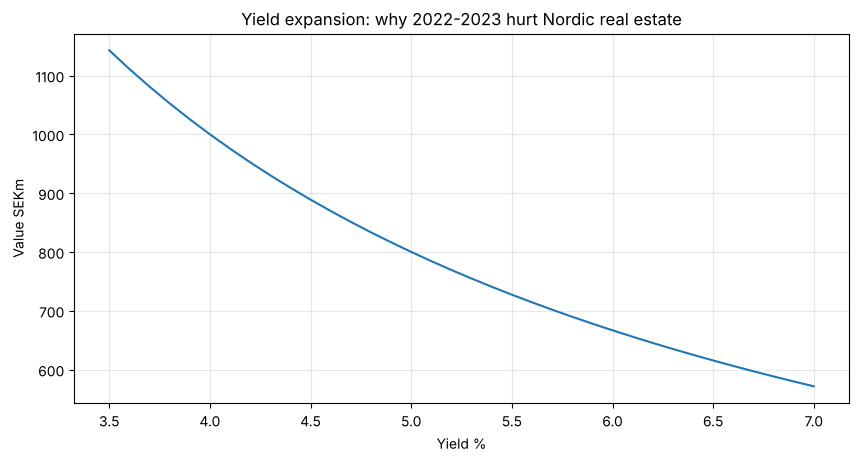


### Life annuity pricing (illustrative mortality)


,annuity factor,life expectancy approx,SEK 1m buys yearly income
age,,,
55,18.9337,26.4987,"52,815.8030"
65,14.3906,18.4652,"69,489.7942"
75,9.9300,11.7694,"100,704.4919"



### ISK tax vs regular account: ISK wins when return > break-even


,schablon rate,taxable base,tax SEK,effective tax on total capital,break-even return vs 30% gains tax
capital,,,,,
200000,0.0355,0,0.0000,0.0000,0.0000
1000000,0.0355,700000,"7,455.0000",0.0075,0.0248
3000000,0.0355,2700000,"28,755.0000",0.0096,0.0319


In [19]:
def margin_call(portfolio_value, loan, max_ltv):
    return {"current LTV": loan / portfolio_value, "max LTV": max_ltv,
            "drop that triggers margin call": 1 - loan / (max_ltv * portfolio_value)}

@demo("margin_call")
def demo_margin():
    show(margin_call(1_000_000, 400_000, 0.6), "Depåbelåning: SEK 1m portfolio, 400k loan, 60% max LTV")

def property_valuation(noi, cap_rate, growth=0.02, discount=0.07, exit_yield=None, years=10):
    exit_yield = exit_yield or cap_rate
    t = np.arange(1, years + 1)
    nois = noi * (1 + growth) ** (t - 1)
    tv = noi * (1 + growth) ** years / exit_yield
    dcf = np.sum(nois / (1 + discount) ** t) + tv / (1 + discount) ** years
    return {"direct capitalisation": noi / cap_rate, "DCF value": dcf,
            "value change if yield +50bp": noi / (cap_rate + 0.005) / (noi / cap_rate) - 1}

@demo("property_valuation")
def demo_prop():
    show(property_valuation(noi=40e6, cap_rate=0.05, exit_yield=0.0525), "Commercial property, NOI SEK 40m")
    ys = np.linspace(0.035, 0.07, 36)
    plt.plot(ys * 100, 40e6 / ys / 1e6); plt.xlabel("Yield %"); plt.ylabel("Value SEKm")
    plt.title("Yield expansion: why 2022-2023 hurt Nordic real estate"); plt.show()

def life_annuity(age, payment=1.0, r=0.025, A=0.0002, B=0.00003, c=1.1, max_age=120, guaranteed_years=0):
    """Gompertz-Makeham hazard mu(x) = A + B*c^x. Parameters are illustrative, not an insurer's table."""
    ages = np.arange(age, max_age)
    mu = A + B * c ** ages
    surv = np.r_[1.0, np.exp(-np.cumsum(mu))][:-1]   # survival to start of each year (annuity-due)
    t = np.arange(len(ages))
    disc = (1 + r) ** -t
    p = np.where(t < guaranteed_years, 1.0, surv)
    return {"annuity factor": float(np.sum(disc * p)) * payment, "life expectancy approx": float(np.sum(surv))}

@demo("life_annuity")
def demo_annuity_life():
    rows = []
    for a in [55, 65, 75]:
        r_ = life_annuity(a); r_["age"] = a; r_["SEK 1m buys yearly income"] = 1e6 / r_["annuity factor"]; rows.append(r_)
    show(pd.DataFrame(rows).set_index("age"), "Life annuity pricing (illustrative mortality)")

def isk_tax(avg_capital_base, slr, tax_free=300_000, min_rate=0.0125, add_on=0.01, tax_rate=0.30):
    """ISK schablonskatt. Defaults reflect 2026 rules as understood at writing time: VERIFY on skatteverket.se."""
    rate = max(slr + add_on, min_rate)
    base = max(avg_capital_base - tax_free, 0)
    tax = base * rate * tax_rate
    return {"schablon rate": rate, "taxable base": base, "tax SEK": tax,
            "effective tax on total capital": tax / avg_capital_base if avg_capital_base else 0}

@demo("isk_tax")
def demo_isk():
    slr = 0.0255  # statslåneränta 30 Nov prior year: placeholder, check the actual figure
    rows = []
    for cap in [200_000, 1_000_000, 3_000_000]:
        r_ = isk_tax(cap, slr); r_["capital"] = cap
        r_["break-even return vs 30% gains tax"] = r_["effective tax on total capital"] / 0.30
        rows.append(r_)
    show(pd.DataFrame(rows).set_index("capital"), "ISK tax vs regular account: ISK wins when return > break-even")

for k in ["margin_call", "property_valuation", "life_annuity", "isk_tax"]:
    DEMOS[k]()

## 17. Portfolio risk toolkit

Build a portfolio straight from catalog names. Each holding inherits the indicative vol from its SRI, and correlations come from a block matrix (same asset class high, different classes lower). Then: parametric VaR, Monte Carlo VaR with fat tails, CVaR (expected shortfall), risk contributions and stress scenarios.

| Measure | Formula |
|---|---|
| Portfolio vol | $\sigma_p = \sqrt{w^\top\Sigma w}$ |
| Parametric VaR | $VaR_\alpha = z_\alpha\,\sigma_p\sqrt{h}\cdot V$ |
| CVaR / ES | $\mathbb{E}[L\mid L\ge VaR_\alpha]$; normal: $\frac{\phi(z_\alpha)}{1-\alpha}\sigma_p\sqrt h V$ |
| Risk contribution | $RC_i = w_i\frac{(\Sigma w)_i}{\sigma_p}$, sums to $\sigma_p$ |


### Portfolio risk on SEK 1m


,value
portfolio vol (ann.),0.1202
parametric VaR 99% 10d,"55,714.5948"
parametric ES 99%,"63,830.2345"
MC VaR (t4),"61,365.2672"
MC ES (t4),"82,485.0768"



### Weights vs risk contribution (2% bitcoin is not 2% of the risk)


,asset_class,sri,indicative_vol,weight,risk_contribution
name,,,,,
Index fund,Funds & Pooled,5,0.2500,0.3000,0.5315
Large-cap blue chip stock,Equities,5,0.2500,0.1000,0.1231
Bitcoin,Crypto & Digital Assets,7,0.9000,0.0200,0.0743
REIT / listed real estate company,Equities,5,0.2500,0.0500,0.0589
Autocallable,Structured Products,6,0.4500,0.0300,0.0526
Investment grade corporate bond,Corporate & Credit,3,0.0850,0.1500,0.0526
Physical gold bullion,Commodities & Environmental,5,0.2500,0.0500,0.0481
Nordic high yield bond,Corporate & Credit,4,0.1600,0.0500,0.0319
Nominal government bond (statsobligation),Government & Public Bonds,2,0.0300,0.1500,0.0154


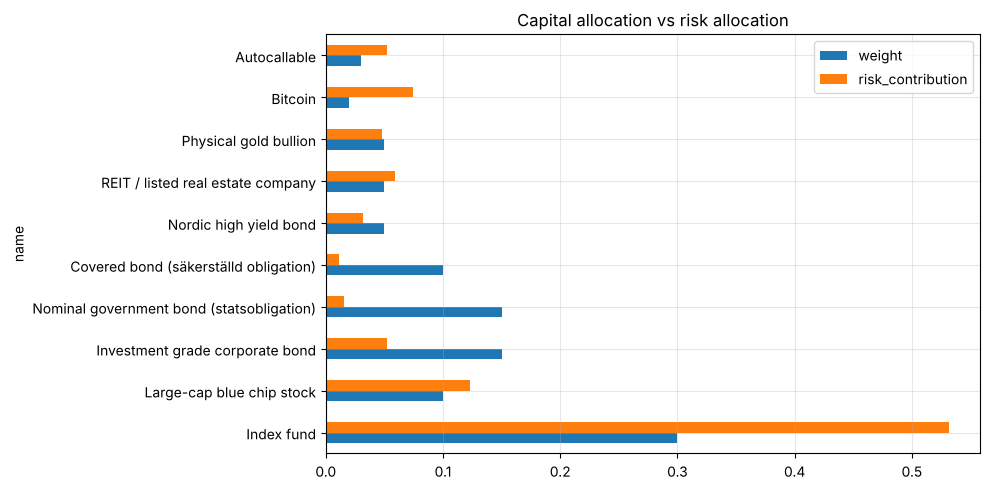

In [20]:
CLASS_CORR = {  # same-class correlation; cross-class uses CROSS_CORR. Crude on purpose: it's a map, not the territory.
    "Equities": 0.75, "Funds & Pooled": 0.7, "Futures": 0.5, "Options": 0.5, "Structured Products": 0.6,
    "Crypto & Digital Assets": 0.8, "Corporate & Credit": 0.6, "Government & Public Bonds": 0.85,
}
CROSS_CORR = 0.25

def build_portfolio(holdings):
    """holdings: dict {catalog name: weight}. Weights normalised to 1."""
    df = catalog.set_index("name").loc[list(holdings), ["asset_class", "sri", "indicative_vol"]].copy()
    w = np.array(list(holdings.values()), float); df["weight"] = w / w.sum()
    n = len(df)
    C = np.full((n, n), CROSS_CORR)
    for i in range(n):
        for j in range(n):
            if i == j: C[i, j] = 1
            elif df["asset_class"].iloc[i] == df["asset_class"].iloc[j]:
                C[i, j] = CLASS_CORR.get(df["asset_class"].iloc[i], 0.5)
    vol = df["indicative_vol"].values
    cov = np.outer(vol, vol) * C
    return df, cov

def portfolio_risk(df, cov, value=1_000_000, alpha=0.99, horizon_days=10, n_sims=200_000, dof=4):
    w = df["weight"].values
    sp = math.sqrt(w @ cov @ w)
    h = math.sqrt(horizon_days / 252)
    z = norm.ppf(alpha)
    var_p = z * sp * h * value
    es_p = norm.pdf(z) / (1 - alpha) * sp * h * value
    rng = np.random.default_rng(SEED)
    L = np.linalg.cholesky(cov)
    t = rng.standard_t(dof, (n_sims, len(w))) / math.sqrt(dof / (dof - 2))  # unit variance, fat tails
    pnl = (t @ L.T) @ w * h * value
    var_mc = -np.percentile(pnl, (1 - alpha) * 100)
    es_mc = -pnl[pnl <= -var_mc].mean()
    rc = w * (cov @ w) / sp
    df = df.assign(risk_contribution=rc / sp)
    return {"portfolio vol (ann.)": sp, f"parametric VaR {alpha:.0%} {horizon_days}d": var_p,
            f"parametric ES {alpha:.0%}": es_p, f"MC VaR (t{dof})": var_mc, f"MC ES (t{dof})": es_mc}, df

PORTFOLIO = {
    "Index fund": 30, "Large-cap blue chip stock": 10, "Investment grade corporate bond": 15,
    "Nominal government bond (statsobligation)": 15, "Covered bond (säkerställd obligation)": 10,
    "Nordic high yield bond": 5, "REIT / listed real estate company": 5, "Physical gold bullion": 5,
    "Bitcoin": 2, "Autocallable": 3,
}
pf, cov = build_portfolio(PORTFOLIO)
risk, pf = portfolio_risk(pf, cov)
show(risk, "Portfolio risk on SEK 1m")
show(pf.sort_values("risk_contribution", ascending=False), "Weights vs risk contribution (2% bitcoin is not 2% of the risk)")
pf[["weight", "risk_contribution"]].plot.barh(figsize=(10, 5), title="Capital allocation vs risk allocation")
plt.tight_layout(); plt.show()

In [21]:
# Stress scenarios: shocks applied per asset class (return over the scenario).
# Numbers are stylised versions of real episodes. They are guesses with good manners, not history.
SCENARIOS = pd.DataFrame({
    "2008 GFC":            {"Equities": -0.45, "Funds & Pooled": -0.40, "Corporate & Credit": -0.15, "Government & Public Bonds": 0.08,
                            "Commodities & Environmental": 0.05, "Crypto & Digital Assets": -0.60, "Structured Products": -0.35,
                            "Real Assets & Alternatives": -0.25, "Cash & Money Market": 0.0, "Securitized": -0.30},
    "2022 rate shock":     {"Equities": -0.20, "Funds & Pooled": -0.18, "Corporate & Credit": -0.14, "Government & Public Bonds": -0.12,
                            "Commodities & Environmental": 0.10, "Crypto & Digital Assets": -0.65, "Structured Products": -0.15,
                            "Real Assets & Alternatives": -0.30, "Cash & Money Market": 0.0, "Securitized": -0.10},
    "2020 Covid crash":    {"Equities": -0.33, "Funds & Pooled": -0.30, "Corporate & Credit": -0.12, "Government & Public Bonds": 0.03,
                            "Commodities & Environmental": -0.02, "Crypto & Digital Assets": -0.50, "Structured Products": -0.30,
                            "Real Assets & Alternatives": -0.20, "Cash & Money Market": 0.0, "Securitized": -0.15},
    "Stagflation":         {"Equities": -0.25, "Funds & Pooled": -0.22, "Corporate & Credit": -0.10, "Government & Public Bonds": -0.08,
                            "Commodities & Environmental": 0.30, "Crypto & Digital Assets": -0.40, "Structured Products": -0.20,
                            "Real Assets & Alternatives": -0.10, "Cash & Money Market": 0.0, "Securitized": -0.08},
}).fillna(0.0)

def stress_test(pf, value=1_000_000, scenarios=SCENARIOS):
    out = {}
    for sc in scenarios.columns:
        shocks = pf["asset_class"].map(scenarios[sc]).fillna(0.0)
        out[sc] = float((pf["weight"] * shocks).sum() * value)
    return pd.Series(out, name="P&L SEK").to_frame()

show(stress_test(pf), "Scenario P&L on the sample portfolio")

def var_backtest_kupiec(exceptions, n_obs, alpha=0.99):
    """Kupiec POF test: are VaR exceptions consistent with the confidence level?"""
    p = 1 - alpha; x = exceptions
    phat = x / n_obs
    lr = -2 * (math.log((1 - p) ** (n_obs - x) * p ** x) - math.log((1 - phat) ** (n_obs - x) * phat ** x))
    return {"exceptions": x, "expected": p * n_obs, "LR stat": lr, "p-value": 1 - stats.chi2.cdf(lr, 1),
            "reject model at 5%": lr > stats.chi2.ppf(0.95, 1)}

show(var_backtest_kupiec(exceptions=7, n_obs=250), "VaR backtest: 7 breaches in 250 days at 99%")


### Scenario P&L on the sample portfolio


,P&L SEK
2008 GFC,"-240,500.0000"
2022 rate shock,"-156,500.0000"
2020 Covid crash,"-191,000.0000"
Stagflation,"-144,500.0000"



### VaR backtest: 7 breaches in 250 days at 99%


,value
exceptions,7
expected,2.5000
LR stat,5.4970
p-value,0.0190
reject model at 5%,True


## 18. Coverage check, lookup examples and export

In [22]:
# Every catalog row with a calc reference must have a working demo. Fail loud, not quiet.
needed = set(catalog["calc"]) - {""}
missing = needed - set(DEMOS)
assert not missing, f"Catalog references undefined demos: {missing}"
cov_tbl = catalog.assign(has_calc=catalog["calc"] != "").groupby("asset_class")["has_calc"].agg(["sum", "size"])
cov_tbl["coverage"] = cov_tbl["sum"] / cov_tbl["size"]
show(cov_tbl.rename(columns={"sum": "with_calc", "size": "instruments"}), "Calculation coverage by asset class")
print(f"{len(DEMOS)} demo calculations registered, {catalog['calc'].ne('').sum()} of {len(catalog)} instruments wired to one.")


### Calculation coverage by asset class


,with_calc,instruments,coverage
asset_class,,,
Cash & Money Market,11,12,0.9167
Commodities & Environmental,1,7,0.1429
Corporate & Credit,23,24,0.9583
Crypto & Digital Assets,6,11,0.5455
Equities,9,14,0.6429
Forwards & Swaps,20,25,0.8000
Funds & Pooled,17,18,0.9444
Futures,15,15,1.0000
Government & Public Bonds,11,12,0.9167


70 demo calculations registered, 172 of 209 instruments wired to one.


In [23]:
describe("Autocallable")


**Autocallable** (#157)  |  Structured Products / Yield enhancement  |  Venue: Bank

*Definition:* Note that redeems early with coupon if underlying is above a call barrier on observation dates.

*Mechanics / payoff:* Embedded short down-and-in put on the downside.

*Key risks:* Capital loss below protection barrier.

| Metric | Score |
|---|---|
| SRI | 6 / 7 `######.` (Very high) |
| Market | 5 / 5 `#####` |
| Credit | 3 / 5 `###..` |
| Liquidity | 4 / 5 `####.` |
| Leverage | 2 / 5 `##...` |
| Complexity | 5 / 5 `#####` |
| Composite | 72.5 / 100 |
| Indicative vol | 45.0% |


--- Demo: autocallable_mc ---

### 5y Phoenix autocall: 8% memory coupon, 70% coupon barrier, 60% protection


,value
fair value per 1,0.9892
implied fee if sold at par,0.0108
P(capital loss),0.1721
avg loss given loss,0.5485
expected life (years),2.7387



### Redemption year distribution


,probability
1,0.4448
2,0.1122
3,0.0555
4,0.0345
5,0.3530


In [24]:
describe("Electricity future")


**Electricity future (Nasdaq Nordic / EEX)** (#99)  |  Futures / Commodity power  |  Venue: Exchange

*Definition:* Financial future on the Nordic system price or an area price.

*Mechanics / payoff:* Cash settled vs spot average over delivery period; EPADs for area spread (SE2 etc.).

*Key risks:* Weather, hydro balance, area price spreads.

| Metric | Score |
|---|---|
| SRI | 7 / 7 `#######` (Very high) |
| Market | 5 / 5 `#####` |
| Credit | 1 / 5 `#....` |
| Liquidity | 3 / 5 `###..` |
| Leverage | 4 / 5 `####.` |
| Complexity | 4 / 5 `####.` |
| Composite | 61.3 / 100 |
| Indicative vol | 90.0% |


--- Demo: power_future ---

### Nordic power: system future + SE2 EPAD for a month


,value
system avg EUR/MWh,47.1212
SE2 avg EUR/MWh,38.6863
"long system future P&L (10 MW, F=52)","-36,298.2765"
long SE2 EPAD P&L (EPAD=-6),"-18,115.3183"
fully hedged SE2 price = F_sys + EPAD,46.0000


In [25]:
filter_catalog(max_sri=3, venue="Exchange")

,id,name,asset_class,sri,composite_risk,venue
22,23,Premium bond (premieobligation),Government & Public Bonds,2,12.5000,Exchange
187,188,Fiat-backed stablecoin,Crypto & Digital Assets,3,18.7000,Exchange
94,95,Short-term interest rate future (STIR),Futures,3,25.0000,Exchange


In [26]:
# Full catalog view (everything, because you asked for everything)
catalog.drop(columns=["calc"])

,id,name,asset_class,sub_class,definition,mechanics_payoff,sri,market,credit,liquidity,leverage,complexity,venue,key_risks,composite_risk,indicative_vol,risk_band
0,1,Bank deposit (current account),Cash & Money Market,Deposit,"Demand deposit at a bank, withdrawable at any time.",Pays a (usually tiny) variable rate; principal guaranteed by the bank and deposit insurance up to the limit.,1,1,1,1,1,1,Bank,"Inflation erosion, bank failure above deposit guarantee (SEK 1.05m in Sweden).",0.0000,0.0030,Low
1,2,Savings account,Cash & Money Market,Deposit,Interest-bearing deposit with limited transaction features.,Variable rate credited periodically; compounding monthly or yearly.,1,1,1,1,1,1,Bank,"Real rate often negative, rate cuts flow through immediately.",0.0000,0.0030,Low
2,3,Term deposit (fasträntekonto),Cash & Money Market,Deposit,Deposit locked for a fixed term at a fixed rate.,Principal plus fixed interest at maturity; early break costs or forbidden.,1,1,1,2,1,1,Bank,"Lock-up, reinvestment risk at maturity.",3.7000,0.0030,Low
3,4,Certificate of deposit (CD),Cash & Money Market,Deposit,Negotiable or non-negotiable time deposit receipt issued by a bank.,"Fixed coupon, usually simple interest under 1 year, can trade in secondary market.",1,1,2,2,1,1,OTC,"Issuer bank credit risk above guarantee, rate risk if sold early.",10.0000,0.0030,Low
4,5,Treasury bill (statsskuldväxel),Cash & Money Market,Government bill,"Short-term zero-coupon government debt, typically 1 to 12 months.","Issued at a discount, pays par at maturity; yield quoted as discount or simple yield.",1,1,1,1,1,1,OTC,Practically only rate and inflation risk.,0.0000,0.0030,Low
5,6,Commercial paper (företagscertifikat),Cash & Money Market,Corporate short-term,Unsecured short-term promissory notes issued by corporates.,"Discount instrument, maturities up to 1 year; rolled continuously by issuers.",2,1,3,3,1,2,OTC,"Rollover risk, market freezes (2008, Swedish CP market 2020).",22.5000,0.0300,Low
6,7,Repurchase agreement (repo),Cash & Money Market,Secured funding,Sale of securities with agreement to buy back later at a higher price.,"Economically a collateralized loan; repo interest = cash x rate x days/360, collateral has haircut.",1,1,2,2,2,2,OTC,"Counterparty default plus collateral value drop, wrong-way risk.",16.2000,0.0030,Low
7,8,Reverse repo,Cash & Money Market,Secured lending,Mirror side of a repo: buy securities and agree to sell them back.,"Cash lender receives repo interest, holds collateral with haircut.",1,1,2,2,1,2,OTC,Collateral liquidation risk if counterparty fails.,12.5000,0.0030,Low
8,9,Tri-party repo,Cash & Money Market,Secured funding,"Repo where a custodian agent handles collateral selection, valuation and settlement.","Same economics as repo, operational burden outsourced to agent.",1,1,2,2,2,2,OTC,"Agent concentration, intraday credit exposures.",16.2000,0.0030,Low
9,10,Securities lending,Cash & Money Market,Secured lending,Lending securities to a borrower (often short sellers) against collateral and a fee.,"Lender earns fee, keeps economic exposure via manufactured dividends.",2,1,2,2,1,2,OTC,"Borrower default with collateral shortfall, cash-collateral reinvestment risk.",12.5000,0.0300,Low


In [27]:
# Export. Colab: files land in /content. Fabric: flip the flag to write a Delta table to the attached Lakehouse.
catalog.to_csv("financial_instruments_catalog.csv", index=False)
try:
    catalog.to_excel("financial_instruments_catalog.xlsx", index=False)
except ImportError:
    print("openpyxl missing, skipped Excel export. CSV is there.")

WRITE_TO_LAKEHOUSE = False  # True in Fabric with a default Lakehouse attached
if WRITE_TO_LAKEHOUSE:
    from pyspark.sql import functions as F
    sdf = spark.createDataFrame(catalog.assign(risk_band=catalog["risk_band"].astype(str)))  # noqa: F821 (spark exists in Fabric)
    (sdf.withColumn("loaded_at", F.current_timestamp())
        .write.mode("overwrite").option("overwriteSchema", "true")
        .format("delta").saveAsTable("ref_financial_instruments"))
    print("Written to Lakehouse table ref_financial_instruments")
else:
    print("Exported CSV/XLSX. Lakehouse write skipped (WRITE_TO_LAKEHOUSE = False).")

Exported CSV/XLSX. Lakehouse write skipped (WRITE_TO_LAKEHOUSE = False).


### How to extend

* **Add an instrument:** append a tuple to `RAW` in section 2, rerun from there. Point `calc` at an existing demo or write a new one with `@demo("your_key")`.
* **Real market data:** replace `PAR_RATES`, `USD_CURVE` and the hard-coded spots. In Fabric, read curves from your Lakehouse; in Colab, `yfinance` works for equities and FX.
* **Tune risk scores:** edit the 1 to 5 scores in `RAW` or the weights in `RISK_WEIGHTS`; everything downstream recalculates.